In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler

import joblib
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    Conv1D,
    MaxPooling1D,
    Flatten,
    LSTM
)

import shap

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [ ]:
# ============================================================
# LOAD DATASET
# ============================================================

df = pd.read_csv(
    "/content/drive/MyDrive/TamilNadu_2015_2024_CNNLSTM_Dataset.csv"
)

print("Dataset Shape :", df.shape)

df.head()

Dataset Shape : (28173, 30)


,system:index,Aspect,B11,B12,B2,B3,B4,B8,Date,District,...,Season,Slope,SoilMoisture,SoilTexture,Temperature,VH,VV,VVVH,Year,.geo
0,0_0_0,148.91924,0.0,0.0,0.0,0.0,0.0,0.0,2015-01,Dharmapuri,...,Winter,4.357264,0.0,6,295.864041,0.0,0.0,0.0,2015.0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
1,0_1_0,233.54536,0.0,0.0,0.0,0.0,0.0,0.0,2015-01,Madurai,...,Winter,0.292674,0.0,6,297.426588,0.0,0.0,0.0,2015.0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
2,0_2_0,283.90973,0.0,0.0,0.0,0.0,0.0,0.0,2015-01,Namakkal,...,Winter,2.891217,0.0,6,296.322873,0.0,0.0,0.0,2015.0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
3,0_3_0,176.10446,0.0,0.0,0.0,0.0,0.0,0.0,2015-01,Erode,...,Winter,5.214771,0.0,6,294.599975,0.0,0.0,0.0,2015.0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."
4,0_4_0,324.14893,0.0,0.0,0.0,0.0,0.0,0.0,2015-01,Tirunelveli Kattabo,...,Winter,0.250311,0.0,4,297.485208,0.0,0.0,0.0,2015.0,"{""geodesic"":false,""type"":""Point"",""coordinates""..."


In [ ]:
# ============================================================
# DATASET INFORMATION
# ============================================================

print(df.info())

print("\n")

print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28173 entries, 0 to 28172
Data columns (total 30 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   system:index  28173 non-null  object 
 1   Aspect        28173 non-null  float64
 2   B11           28173 non-null  float64
 3   B12           28173 non-null  float64
 4   B2            28173 non-null  float64
 5   B3            28173 non-null  float64
 6   B4            28173 non-null  float64
 7   B8            28173 non-null  float64
 8   Date          28173 non-null  object 
 9   District      28173 non-null  object 
 10  EVI           28173 non-null  float64
 11  Elevation     28173 non-null  int64  
 12  LULC          28173 non-null  int64  
 13  Latitude      28173 non-null  float64
 14  Longitude     28173 non-null  float64
 15  Month         28173 non-null  float64
 16  NDVI          28173 non-null  float64
 17  NDWI          28173 non-null  float64
 18  Rainfall      28173 non-nu

In [ ]:
# ============================================================
# REMOVE INVALID RECORDS
# ============================================================

df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

df.dropna(inplace=True)

print("After NA Removal:", df.shape)

After NA Removal: (28173, 30)


In [ ]:
# ============================================================
# REMOVE ZERO SOIL MOISTURE
# ============================================================

df = df[
    df["SoilMoisture"] > 0
]

print("After SM Filter:", df.shape)

# Remove invalid rows

df = df[
    (df["VV"] != 0) &
    (df["VH"] != 0) &
    (df["NDVI"] != 0)
]

print("Shape after removing invalid rows:", df.shape)
# ============================================================
# REMOVE DUPLICATES
# ============================================================

df.drop_duplicates(inplace=True)

print("After Duplicate Removal:", df.shape)

After SM Filter: (20475, 30)
Shape after removing invalid rows: (15883, 30)
After Duplicate Removal: (15883, 30)


In [ ]:
# ============================================================
# LABEL ENCODING
# ============================================================

district_encoder = LabelEncoder()

season_encoder = LabelEncoder()

df["District"] = district_encoder.fit_transform(
    df["District"]
)

df["Season"] = season_encoder.fit_transform(
    df["Season"]
)

print("Encoding Completed")

Encoding Completed


In [ ]:
cols = [
    'VWC',
    'Tau',
    'SigmaVeg',
    'SigmaSoil',
    'WCM_SM'
]

df.drop(columns=cols, inplace=True, errors='ignore')

In [ ]:
A = 0.1
B = 2.0

df['VWC'] = (
    0.6 * df['NDVI'] +
    0.4 * df['EVI']
)

df['VWC'] = df['VWC'].clip(lower=0)

df['Tau'] = np.exp(
    -2 * B * df['VWC']
)

df['Tau'] = np.clip(
    df['Tau'],
    0,
    1
)

df['SigmaVeg'] = (
    A *
    df['VWC'] *
    (1 - df['Tau'])
)

df['SigmaSoil'] = (
    df['VV'].abs() *
    df['Tau']
)

df['WCM_SM'] = (
    df['SigmaSoil'] *
    (1 + df['NDVI'])
)

In [ ]:
# ============================================================
# SAR FEATURES
# ============================================================

df["VV_minus_VH"] = (

    df["VV"]

    -

    df["VH"]

)

df["VV_plus_VH"] = (

    df["VV"]

    +

    df["VH"]

)

df["VVVH_ratio"] = (

    df["VV"]

    /

    (df["VH"] + 0.0001)

)

In [ ]:
# Climate Interaction Features

df["NDVI_Rainfall"] = (

    df["NDVI"] * df["Rainfall"]

)

df["NDVI_Temp"] = (

    df["NDVI"] * df["Temperature"]

)

In [ ]:
# ============================================================
# PHASE 1 : FEATURE ENGINEERING
# ============================================================

import numpy as np
import pandas as pd

# Sort for time series

df = df.sort_values(
    ['District','Year','Month']
).reset_index(drop=True)

# ============================================================
# TEMPORAL FEATURES
# ============================================================

df['SM_LAG1'] = (
    df.groupby('District')['SoilMoisture']
    .shift(1)
)

df['SM_LAG2'] = (
    df.groupby('District')['SoilMoisture']
    .shift(2)
)

df['SM_LAG3'] = (
    df.groupby('District')['SoilMoisture']
    .shift(3)
)

df['SM_LAG6'] = (
    df.groupby('District')['SoilMoisture']
    .shift(6)
)

# ============================================================
# ROLLING FEATURES
# ============================================================

df['SM_ROLL3'] = (
    df.groupby('District')['SoilMoisture']
    .transform(lambda x: x.rolling(3).mean())
)

df['SM_ROLL6'] = (
    df.groupby('District')['SoilMoisture']
    .transform(lambda x: x.rolling(6).mean())
)

df['SM_ROLL12'] = (
    df.groupby('District')['SoilMoisture']
    .transform(lambda x: x.rolling(12).mean())
)

# ============================================================
# MONTH CYCLIC FEATURES
# ============================================================

df['Month_Sin'] = np.sin(
    2*np.pi*df['Month']/12
)

df['Month_Cos'] = np.cos(
    2*np.pi*df['Month']/12
)

# ============================================================
# MONSOON FEATURE
# ============================================================

df['Monsoon'] = df['Month'].apply(
    lambda x: 1 if x in [6,7,8,9,10,11] else 0
)

# ============================================================
# REMOVE NaN CREATED BY LAGS
# ============================================================

df = df.dropna().reset_index(drop=True)

print("Dataset Shape :", df.shape)

Dataset Shape : (15575, 50)


In [ ]:
# ============================================================
# INPUT FEATURES
# ============================================================

features = [

'VV',
'VH',
'VVVH',

'B2',
'B3',
'B4',
'B8',
'B11',
'B12',

'NDVI',
'NDWI',
'SAVI',
'EVI',

'Rainfall',
'Temperature',

'Elevation',
'Slope',
'Aspect',

'LULC',
'SoilTexture',

'District',
'Month',
'Year',

'VWC',
'Tau',
'SigmaVeg',
'SigmaSoil',
'WCM_SM',

'SM_LAG1',
'SM_LAG2',
'SM_LAG3',
'SM_LAG6',

'SM_ROLL3',
'SM_ROLL6',
'SM_ROLL12',

'Month_Sin',
'Month_Cos',

'Monsoon'

]

target = 'SoilMoisture'

X = df[features]

y = df[target]

print("Features =", len(features))
print("X Shape =", X.shape)

Features = 38
X Shape = (15575, 38)


In [ ]:
from sklearn.preprocessing import StandardScaler

# NORMALIZATION

X = df[features]

y = df[target]

feature_scaler = StandardScaler()

X_scaled = feature_scaler.fit_transform(X)

target_scaler = MinMaxScaler()

y_scaled = target_scaler.fit_transform(
    y.values.reshape(-1,1)
)

In [ ]:
sequence_length = 12

X_seq = []
y_seq = []

for i in range(
    sequence_length,
    len(X_scaled)
):

    X_seq.append(
        X_scaled[
            i-sequence_length:i
        ]
    )

    y_seq.append(
        y_scaled[i]
    )

X_seq = np.array(X_seq)

y_seq = np.array(y_seq)

print(X_seq.shape)
print(y_seq.shape)

(15563, 12, 38)
(15563, 1)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    shuffle=False

)

In [ ]:
# ============================================================
# ADD WCM FEATURES TO ORIGINAL DATASET
# ============================================================

# Check whether WCM features exist
print(df[[
    'VWC',
    'Tau',
    'SigmaVeg',
    'SigmaSoil',
    'WCM_SM'
]].head())

# If they already exist, simply save the updated dataset
df.to_csv(
    "TamilNadu_SoilMoisture_Dataset_With_WCM.csv",
    index=False
)

print("Dataset saved successfully.")
print("New Shape :", df.shape)

print("\nColumns in Dataset:")
print(df.columns.tolist())

        VWC       Tau  SigmaVeg  SigmaSoil    WCM_SM
0  0.266896  0.343838  0.017513   3.795094  4.908407
1  0.330955  0.266116  0.024288   2.794801  3.859763
2  0.489804  0.140969  0.042076   1.466597  2.291740
3  0.293190  0.309512  0.020244   3.240260  4.344374
4  0.430253  0.178885  0.035329   1.802002  2.668071
Dataset saved successfully.
New Shape : (15575, 50)

Columns in Dataset:
['system:index', 'Aspect', 'B11', 'B12', 'B2', 'B3', 'B4', 'B8', 'Date', 'District', 'EVI', 'Elevation', 'LULC', 'Latitude', 'Longitude', 'Month', 'NDVI', 'NDWI', 'Rainfall', 'SAVI', 'Season', 'Slope', 'SoilMoisture', 'SoilTexture', 'Temperature', 'VH', 'VV', 'VVVH', 'Year', '.geo', 'VWC', 'Tau', 'SigmaVeg', 'SigmaSoil', 'WCM_SM', 'VV_minus_VH', 'VV_plus_VH', 'VVVH_ratio', 'NDVI_Rainfall', 'NDVI_Temp', 'SM_LAG1', 'SM_LAG2', 'SM_LAG3', 'SM_LAG6', 'SM_ROLL3', 'SM_ROLL6', 'SM_ROLL12', 'Month_Sin', 'Month_Cos', 'Monsoon']


In [ ]:
print(df.columns)

print(df[[
    "VWC",
    "Tau",
    "SigmaVeg",
    "SigmaSoil",
    "WCM_SM"
]].head())

Index(['system:index', 'Aspect', 'B11', 'B12', 'B2', 'B3', 'B4', 'B8', 'Date',
       'District', 'EVI', 'Elevation', 'LULC', 'Latitude', 'Longitude',
       'Month', 'NDVI', 'NDWI', 'Rainfall', 'SAVI', 'Season', 'Slope',
       'SoilMoisture', 'SoilTexture', 'Temperature', 'VH', 'VV', 'VVVH',
       'Year', '.geo', 'VWC', 'Tau', 'SigmaVeg', 'SigmaSoil', 'WCM_SM',
       'VV_minus_VH', 'VV_plus_VH', 'VVVH_ratio', 'NDVI_Rainfall', 'NDVI_Temp',
       'SM_LAG1', 'SM_LAG2', 'SM_LAG3', 'SM_LAG6', 'SM_ROLL3', 'SM_ROLL6',
       'SM_ROLL12', 'Month_Sin', 'Month_Cos', 'Monsoon'],
      dtype='object')
        VWC       Tau  SigmaVeg  SigmaSoil    WCM_SM
0  0.266896  0.343838  0.017513   3.795094  4.908407
1  0.330955  0.266116  0.024288   2.794801  3.859763
2  0.489804  0.140969  0.042076   1.466597  2.291740
3  0.293190  0.309512  0.020244   3.240260  4.344374
4  0.430253  0.178885  0.035329   1.802002  2.668071


In [ ]:
import numpy as np
import time

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ============================================================
# RESHAPE DATA
# ============================================================

X_train_rf = X_train.values.reshape(X_train.shape[0], -1)
X_test_rf = X_test.values.reshape(X_test.shape[0], -1)

y_train_rf = y_train.values
y_test_rf = y_test.values

print("X_train shape :", X_train_rf.shape)
print("X_test shape  :", X_test_rf.shape)

# ============================================================
# REMOVE NaN / INF
# ============================================================

X_train_rf = np.nan_to_num(X_train_rf)
X_test_rf = np.nan_to_num(X_test_rf)

y_train_rf = np.nan_to_num(y_train_rf)
y_test_rf = np.nan_to_num(y_test_rf)

print("NaN Check:")
print(np.isnan(X_train_rf).sum())
print(np.isnan(y_train_rf).sum())

# ============================================================
# RANDOM FOREST MODEL
# ============================================================

rf_model = RandomForestRegressor(

    n_estimators=100,      # faster than 300

    max_depth=15,          # sufficient

    min_samples_split=5,

    min_samples_leaf=2,

    max_features='sqrt',

    bootstrap=True,

    random_state=42,

    n_jobs=-1,

    verbose=1
)

# ============================================================
# TRAINING
# ============================================================

print("\nTraining Random Forest...")

start_time = time.time()

rf_model.fit(
    X_train_rf,
    y_train_rf
)

end_time = time.time()

print(
    f"\nTraining Completed in {(end_time-start_time):.2f} seconds"
)

# ============================================================
# PREDICTION
# ============================================================

rf_pred = rf_model.predict(X_test_rf)

# ============================================================
# METRICS
# ============================================================

rmse = np.sqrt(
    mean_squared_error(
        y_test_rf,
        rf_pred
    )
)

mae = mean_absolute_error(
    y_test_rf,
    rf_pred
)

mse = mean_squared_error(
    y_test_rf,
    rf_pred
)

r2 = r2_score(
    y_test_rf,
    rf_pred
)

nse = (
    1 -
    (
        np.sum(
            (y_test_rf-rf_pred)**2
        )
        /
        np.sum(
            (
                y_test_rf-
                np.mean(y_test_rf)
            )**2
        )
    )
)

r = np.corrcoef(
    y_test_rf,
    rf_pred
)[0,1]

# ============================================================
# RESULTS
# ============================================================

results_rf = {

    'Model' : 'Random Forest',

    'RMSE' : rmse,

    'MAE' : mae,

    'MSE' : mse,

    'R2' : r2,

    'NSE' : nse,

    'R' : r

}

print("\nResults")
print(results_rf)

import joblib

joblib.dump(
    rf_model,
    "rf_model.pkl"
)

X_train shape : (12460, 38)
X_test shape  : (3115, 38)
NaN Check:
0
0

Training Random Forest...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    2.3s



Training Completed in 5.20 seconds

Results
{'Model': 'Random Forest', 'RMSE': np.float64(1.64666290144724), 'MAE': 1.0824067266971853, 'MSE': 2.711498711002643, 'R2': 0.9436048044579731, 'NSE': np.float64(0.9436048044579731), 'R': np.float64(0.9717772422679667)}


[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    5.2s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.1s finished


['rf_model.pkl']

In [ ]:
joblib.dump(
    rf_model,
    "rf_model.pkl"
)
rf_model = joblib.load(
    "rf_model.pkl"
)

In [ ]:
# ============================================================
# IMPROVED RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(

    n_estimators=2500,

    max_depth=35,

    min_samples_split=2,

    min_samples_leaf=1,

    max_features='sqrt',

    bootstrap=True,

    random_state=42,

    n_jobs=-1,

    verbose=1

)

print("Training RF...")

rf_model.fit(X_train,y_train)

print("Training Completed")

rf_pred = rf_model.predict(X_test)

Training RF...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    4.3s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:   14.6s
[Parallel(n_jobs=-1)]: Done 446 tasks      | elapsed:   35.4s
[Parallel(n_jobs=-1)]: Done 796 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done 1246 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 1796 tasks      | elapsed:  2.3min
[Parallel(n_jobs=-1)]: Done 2446 tasks      | elapsed:  3.2min
[Parallel(n_jobs=-1)]: Done 2500 out of 2500 | elapsed:  3.2min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.1s


Training Completed


[Parallel(n_jobs=2)]: Done 446 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done 796 tasks      | elapsed:    0.6s
[Parallel(n_jobs=2)]: Done 1246 tasks      | elapsed:    0.9s
[Parallel(n_jobs=2)]: Done 1796 tasks      | elapsed:    1.3s
[Parallel(n_jobs=2)]: Done 2446 tasks      | elapsed:    1.7s
[Parallel(n_jobs=2)]: Done 2500 out of 2500 | elapsed:    1.8s finished


In [ ]:
# ============================================================
# METRICS
# ============================================================

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import numpy as np

rmse = np.sqrt(
    mean_squared_error(y_test,rf_pred)
)

mae = mean_absolute_error(
    y_test,
    rf_pred
)

mse = mean_squared_error(
    y_test,
    rf_pred
)

r2 = r2_score(
    y_test,
    rf_pred
)

nse = (
    1 -
    (
        np.sum((y_test-rf_pred)**2)
        /
        np.sum(
            (y_test-y_test.mean())**2
        )
    )
)

r = np.corrcoef(
    y_test.values,
    rf_pred
)[0,1]

results = {

'Model':'RF Final',

'RMSE':rmse,

'MAE':mae,

'MSE':mse,

'R2':r2,

'NSE':nse,

'R':r

}

print("\nRESULTS")
print("="*50)

print(results)


RESULTS
{'Model': 'RF Final', 'RMSE': np.float64(1.603924584309181), 'MAE': 1.055647649852927, 'MSE': 2.5725740721513786, 'R2': 0.9464942331498737, 'NSE': np.float64(0.9464942331498737), 'R': np.float64(0.9733665388692833)}



RESULTS
Model: RF Final
RMSE: 1.603924584309181
MAE: 1.055647649852927
MSE: 2.5725740721513786
R2: 0.9464942331498737
NSE: 0.9464942331498737
R: 0.9733665388692833

Metrics Used For Plot
  Metric     Value
0   RMSE  1.603925
1    MAE  1.055648
2    MSE  2.572574
3     R2  0.946494
4    NSE  0.946494
5      R  0.973367


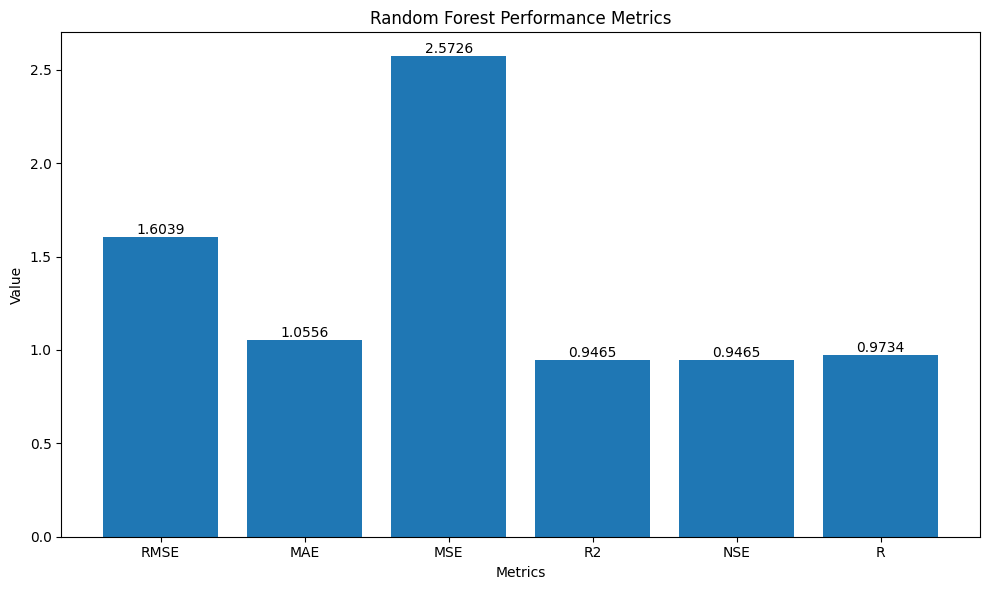

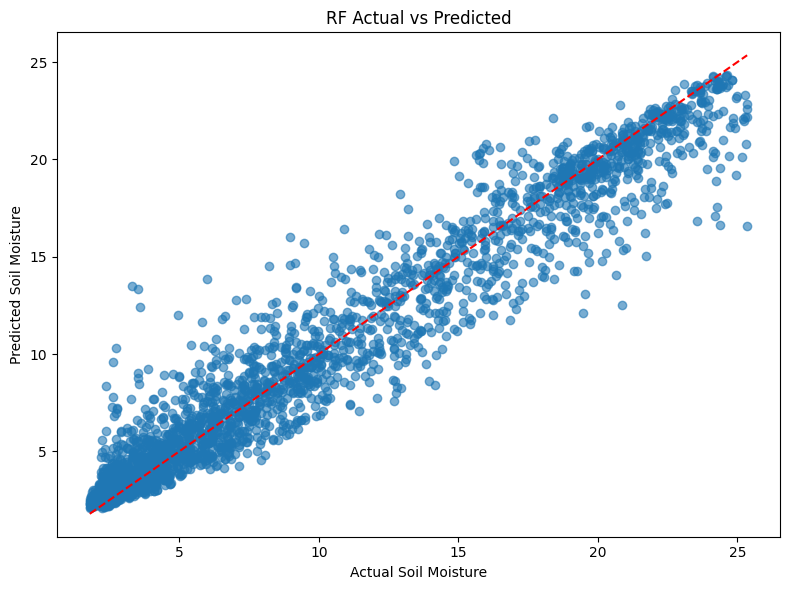

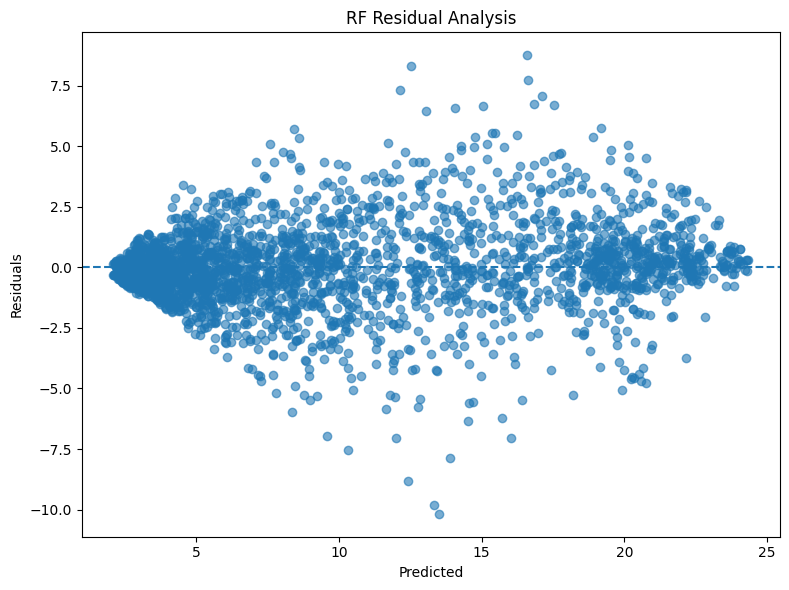

In [ ]:
# ============================================================
# PERFORMANCE METRICS
# ============================================================

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rmse = np.sqrt(
    mean_squared_error(y_test_rf, rf_pred)
)

mae = mean_absolute_error(
    y_test_rf,
    rf_pred
)

mse = mean_squared_error(
    y_test_rf,
    rf_pred
)

r2 = r2_score(
    y_test_rf,
    rf_pred
)

nse = (
    1 -
    (
        np.sum((y_test_rf - rf_pred) ** 2)
        /
        np.sum((y_test_rf - np.mean(y_test_rf)) ** 2)
    )
)

r = np.corrcoef(
    np.ravel(y_test_rf),
    np.ravel(rf_pred)
)[0,1]

results = {
    "Model": "RF Final",
    "RMSE": float(rmse),
    "MAE": float(mae),
    "MSE": float(mse),
    "R2": float(r2),
    "NSE": float(nse),
    "R": float(r)
}

print("\nRESULTS")
print("=" * 50)

for k, v in results.items():
    print(f"{k}: {v}")

# ============================================================
# METRICS DATAFRAME
# ============================================================

metrics_df = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "MSE", "R2", "NSE", "R"],
    "Value": [
        rmse,
        mae,
        mse,
        r2,
        nse,
        r
    ]
})

print("\nMetrics Used For Plot")
print(metrics_df)

# ============================================================
# PERFORMANCE METRICS BAR CHART
# ============================================================

plt.figure(figsize=(10,6))

bars = plt.bar(
    metrics_df["Metric"],
    metrics_df["Value"]
)

plt.title("Random Forest Performance Metrics")
plt.xlabel("Metrics")
plt.ylabel("Value")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(8,6))

plt.scatter(
    y_test_rf,
    rf_pred,
    alpha=0.6
)

plt.plot(
    [np.min(y_test_rf), np.max(y_test_rf)],
    [np.min(y_test_rf), np.max(y_test_rf)],
    'r--'
)

plt.xlabel("Actual Soil Moisture")
plt.ylabel("Predicted Soil Moisture")
plt.title("RF Actual vs Predicted")

plt.tight_layout()
plt.show()

# ============================================================
# RESIDUAL PLOT
# ============================================================

residuals = np.ravel(y_test_rf) - np.ravel(rf_pred)

plt.figure(figsize=(8,6))

plt.scatter(
    rf_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("RF Residual Analysis")

plt.tight_layout()
plt.show()

In [ ]:
!pip install skillmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.2/83.2 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 12.5 MB/s eta 0:00:00


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 446 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done 796 tasks      | elapsed:    0.7s
[Parallel(n_jobs=2)]: Done 1246 tasks      | elapsed:    1.6s
[Parallel(n_jobs=2)]: Done 1796 tasks      | elapsed:    2.3s
[Parallel(n_jobs=2)]: Done 2446 tasks      | elapsed:    3.0s
[Parallel(n_jobs=2)]: Done 2500 out of 2500 | elapsed:    3.0s finished


Random Forest Performance
RMSE : 1.60392
MAE  : 1.05565
MSE  : 2.57257
R²   : 0.94649
NSE  : 0.94649
R    : 0.97337


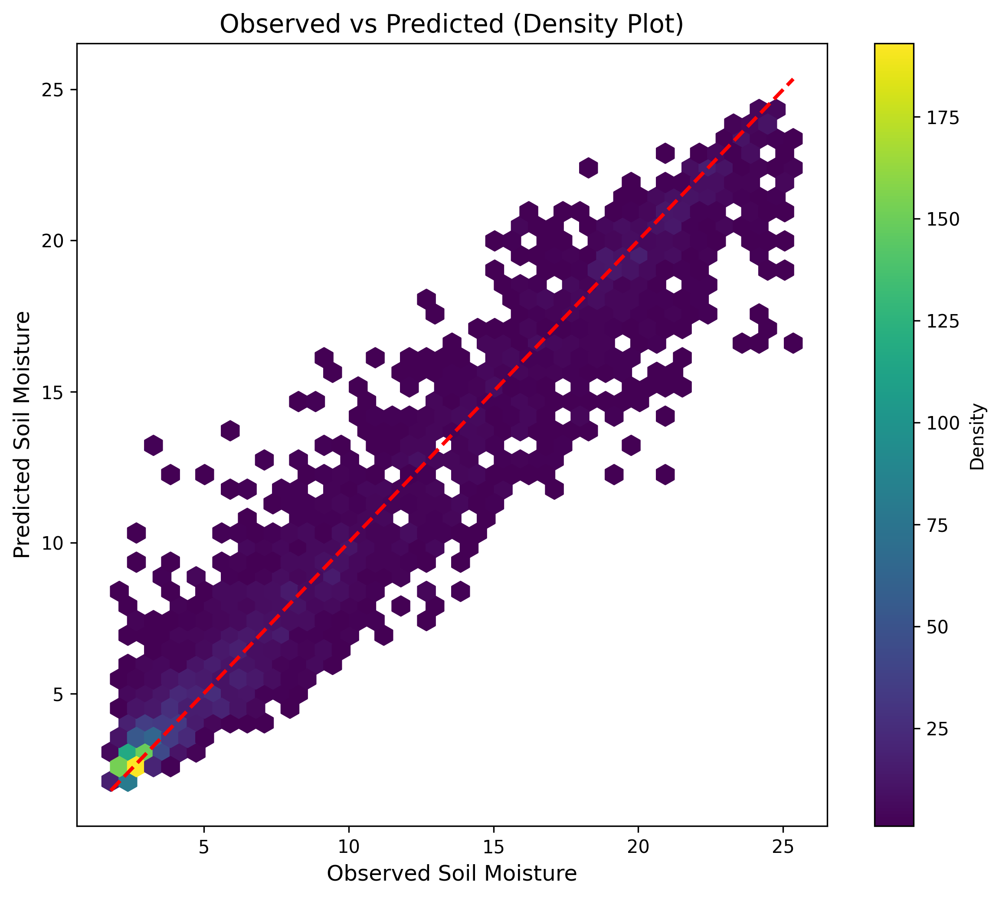

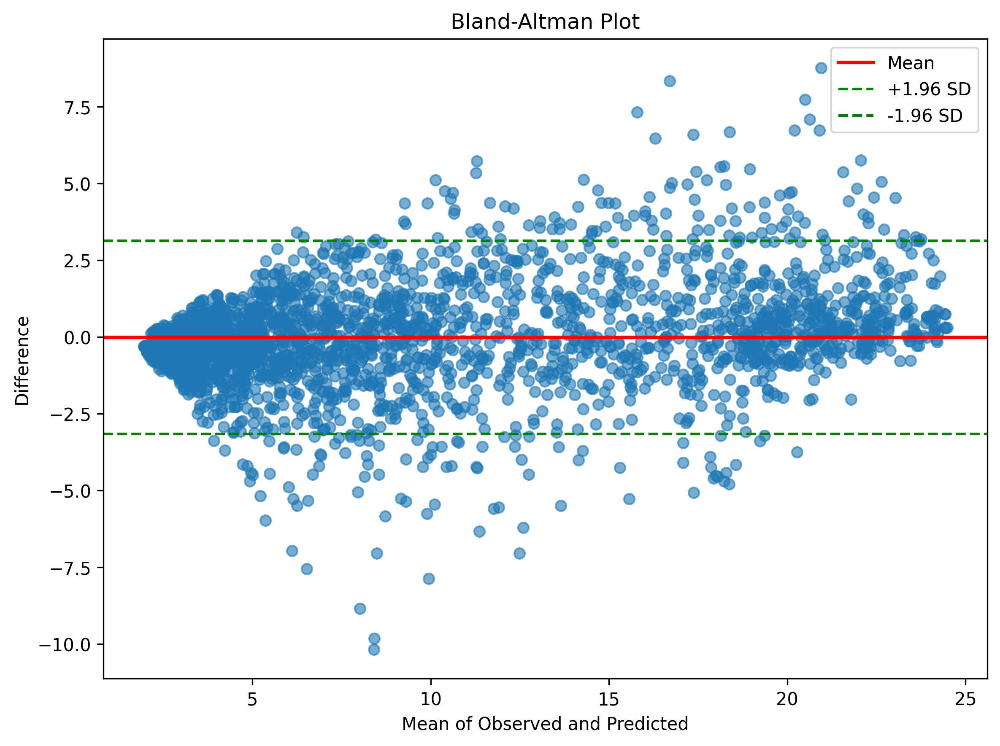

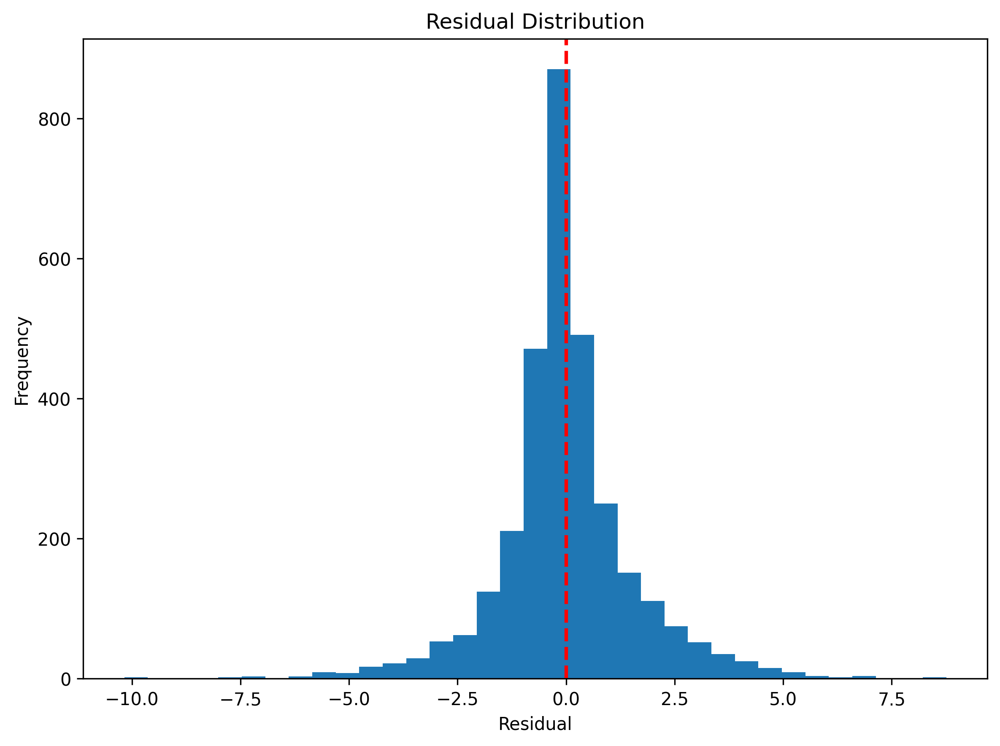

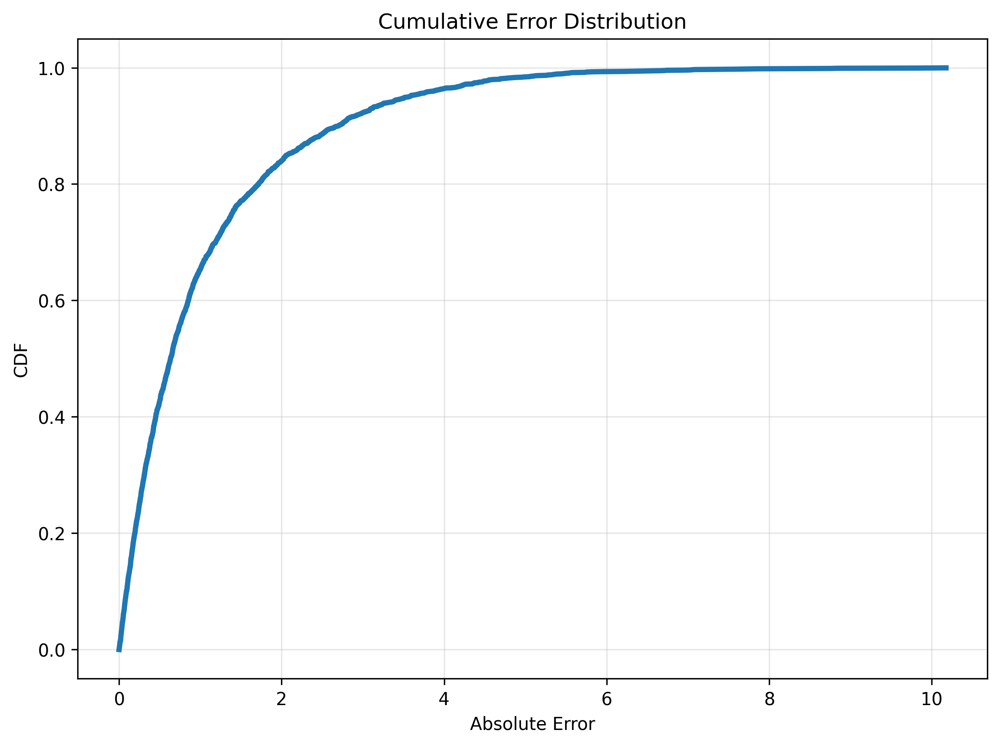

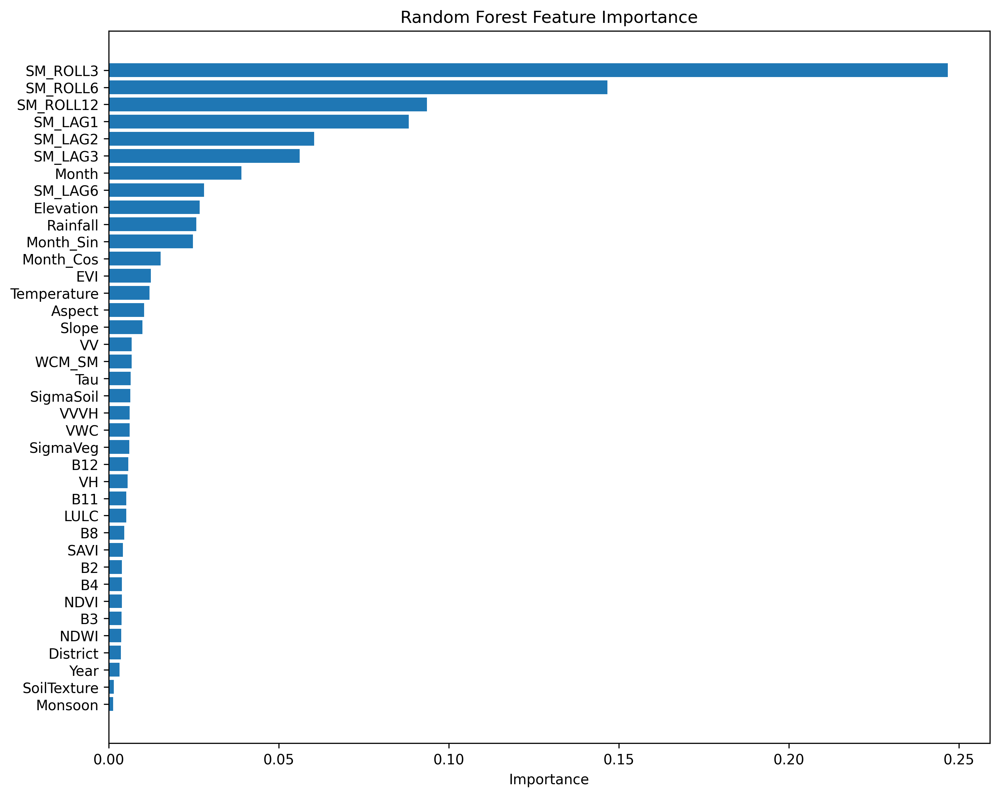

        Metric     Value
0         RMSE  1.603925
1          MAE  1.055648
2          MSE  2.572574
3           R2  0.946494
4          NSE  0.946494
5  Correlation  0.973367


In [ ]:
# ============================================================
# JOURNAL QUALITY RANDOM FOREST PERFORMANCE VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

rf_pred = rf_model.predict(X_test)

y_true = np.array(y_test).flatten()
y_pred = np.array(rf_pred).flatten()

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

nse = 1 - (
    np.sum((y_true - y_pred) ** 2) /
    np.sum((y_true - np.mean(y_true)) ** 2)
)

r = np.corrcoef(y_true, y_pred)[0,1]

print("="*60)
print("Random Forest Performance")
print("="*60)

print(f"RMSE : {rmse:.5f}")
print(f"MAE  : {mae:.5f}")
print(f"MSE  : {mse:.5f}")
print(f"R²   : {r2:.5f}")
print(f"NSE  : {nse:.5f}")
print(f"R    : {r:.5f}")

# ============================================================
# 1. HEXBIN DENSITY PLOT
# ============================================================

plt.figure(figsize=(8,7), dpi=300)

hb = plt.hexbin(
    y_true,
    y_pred,
    gridsize=40,
    cmap="viridis",
    mincnt=1
)

plt.plot(
    [y_true.min(), y_true.max()],
    [y_true.min(), y_true.max()],
    'r--',
    linewidth=2
)

plt.colorbar(label="Density")

plt.xlabel("Observed Soil Moisture", fontsize=12)
plt.ylabel("Predicted Soil Moisture", fontsize=12)

plt.title("Observed vs Predicted (Density Plot)", fontsize=14)

plt.tight_layout()

plt.show()

# ============================================================
# 2. BLAND ALTMAN PLOT
# ============================================================

mean = (y_true + y_pred)/2
diff = y_true - y_pred

md = np.mean(diff)
sd = np.std(diff)

plt.figure(figsize=(8,6), dpi=300)

plt.scatter(
    mean,
    diff,
    alpha=0.6
)

plt.axhline(
    md,
    color="red",
    linewidth=2,
    label="Mean"
)

plt.axhline(
    md + 1.96*sd,
    linestyle="--",
    color="green",
    label="+1.96 SD"
)

plt.axhline(
    md - 1.96*sd,
    linestyle="--",
    color="green",
    label="-1.96 SD"
)

plt.xlabel("Mean of Observed and Predicted")

plt.ylabel("Difference")

plt.title("Bland-Altman Plot")

plt.legend()

plt.tight_layout()

plt.show()

# ============================================================
# 3. RESIDUAL HISTOGRAM
# ============================================================

residuals = y_true - y_pred

plt.figure(figsize=(8,6), dpi=300)

plt.hist(
    residuals,
    bins=35
)

plt.axvline(
    0,
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel("Residual")

plt.ylabel("Frequency")

plt.title("Residual Distribution")

plt.tight_layout()

plt.show()

# ============================================================
# 4. CDF ERROR PLOT
# ============================================================

errors = np.abs(residuals)

sorted_errors = np.sort(errors)

cdf = np.arange(len(errors))/float(len(errors))

plt.figure(figsize=(8,6), dpi=300)

plt.plot(
    sorted_errors,
    cdf,
    linewidth=3
)

plt.grid(alpha=0.3)

plt.xlabel("Absolute Error")

plt.ylabel("CDF")

plt.title("Cumulative Error Distribution")

plt.tight_layout()

plt.show()

# ============================================================
# 5. FEATURE IMPORTANCE
# ============================================================

importance = rf_model.feature_importances_

feature_names = X_test.columns

indices = np.argsort(importance)

plt.figure(figsize=(10,8), dpi=300)

plt.barh(
    range(len(indices)),
    importance[indices]
)

plt.yticks(
    range(len(indices)),
    feature_names[indices]
)

plt.xlabel("Importance")

plt.title("Random Forest Feature Importance")

plt.tight_layout()

plt.show()

# ============================================================
# METRICS TABLE
# ============================================================

metrics_df = pd.DataFrame({
    "Metric":[
        "RMSE",
        "MAE",
        "MSE",
        "R2",
        "NSE",
        "Correlation"
    ],
    "Value":[
        rmse,
        mae,
        mse,
        r2,
        nse,
        r
    ]
})

print(metrics_df)

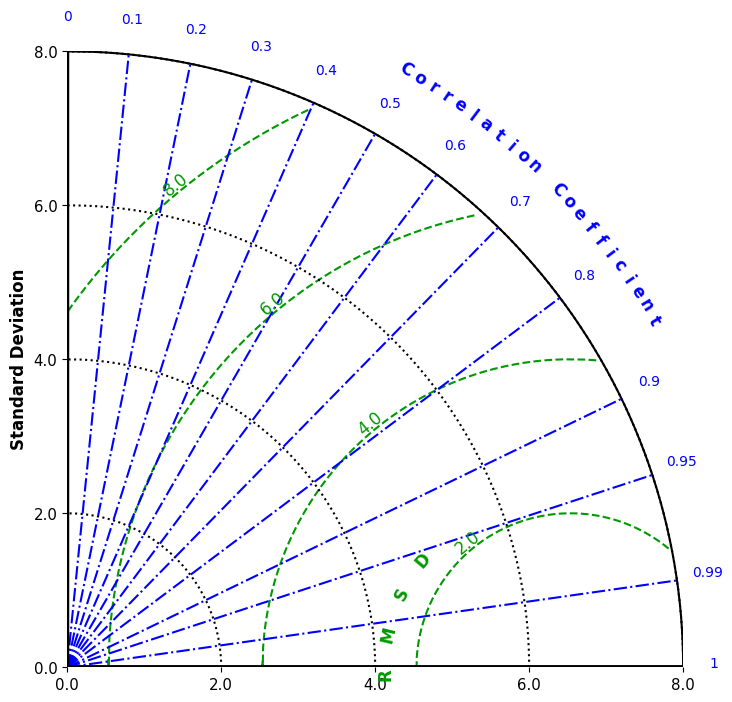

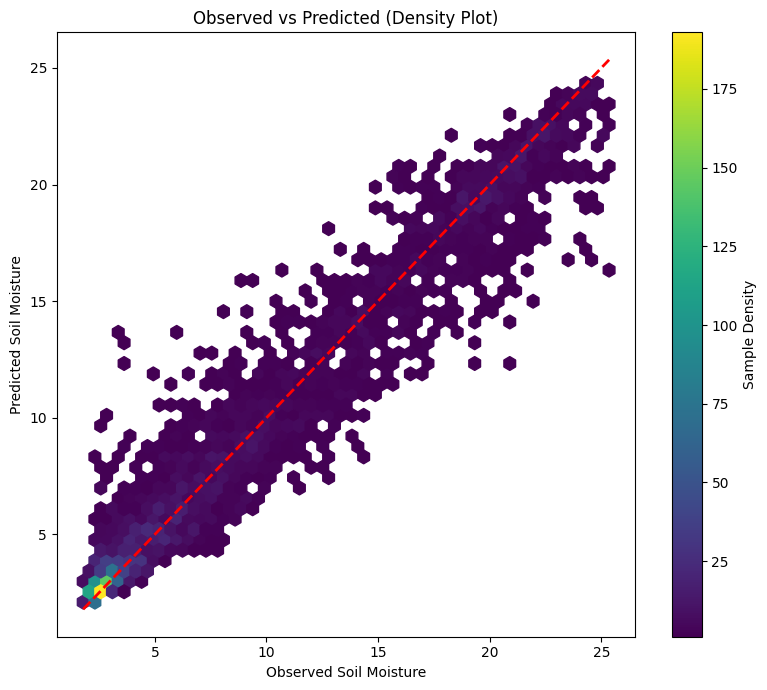

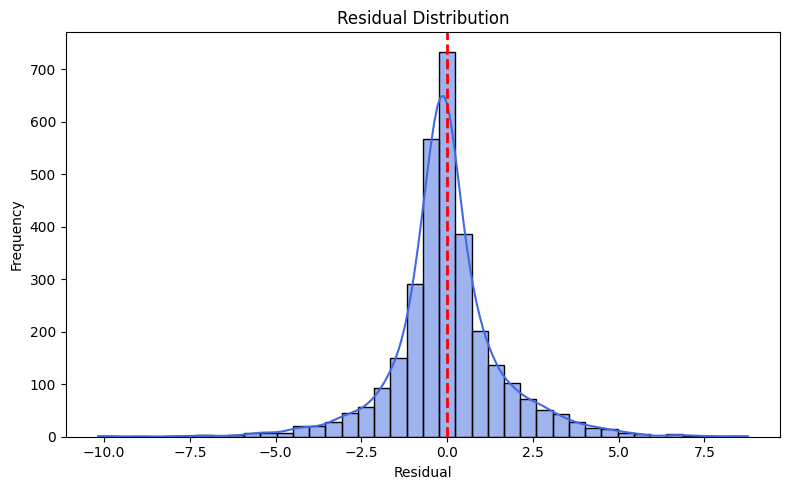

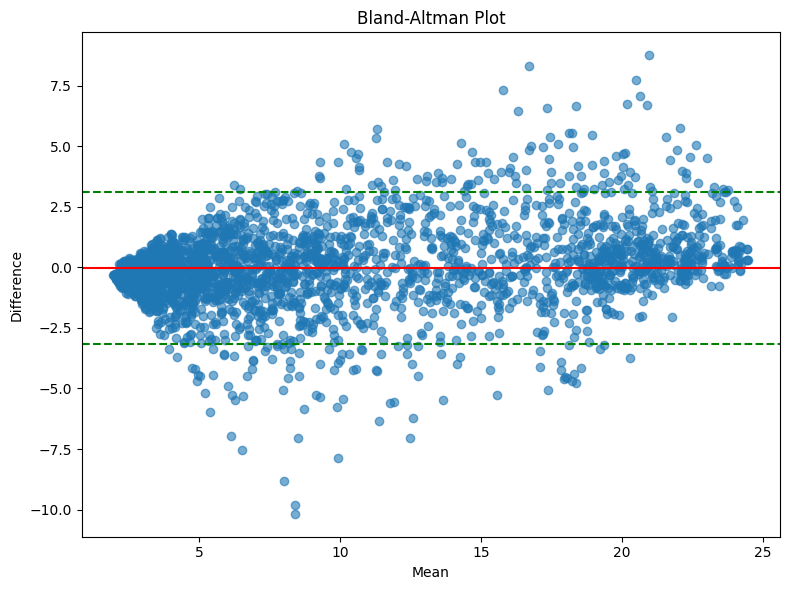

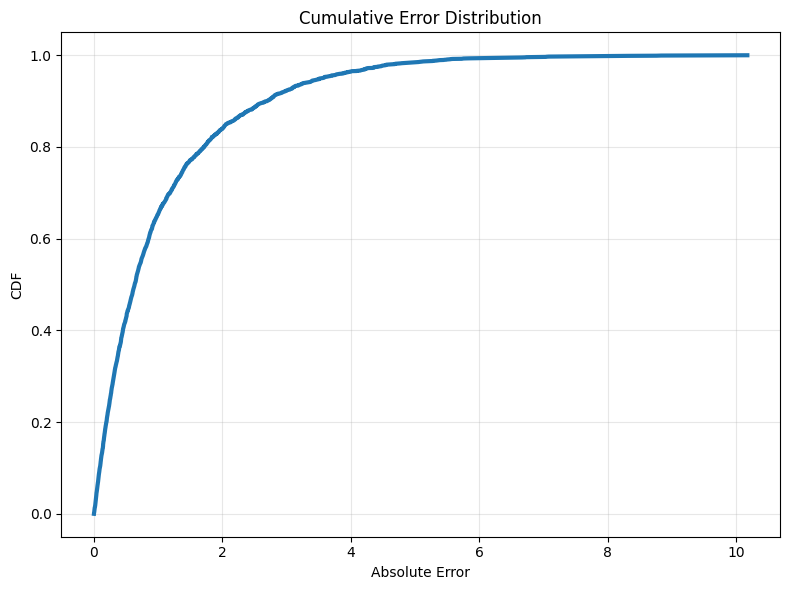

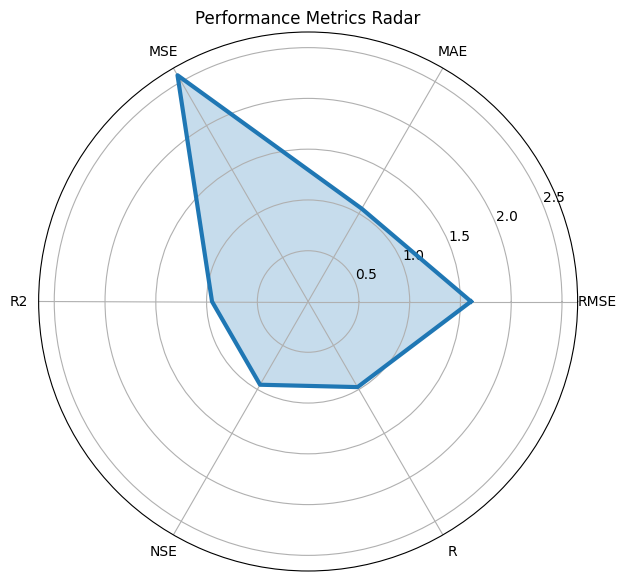

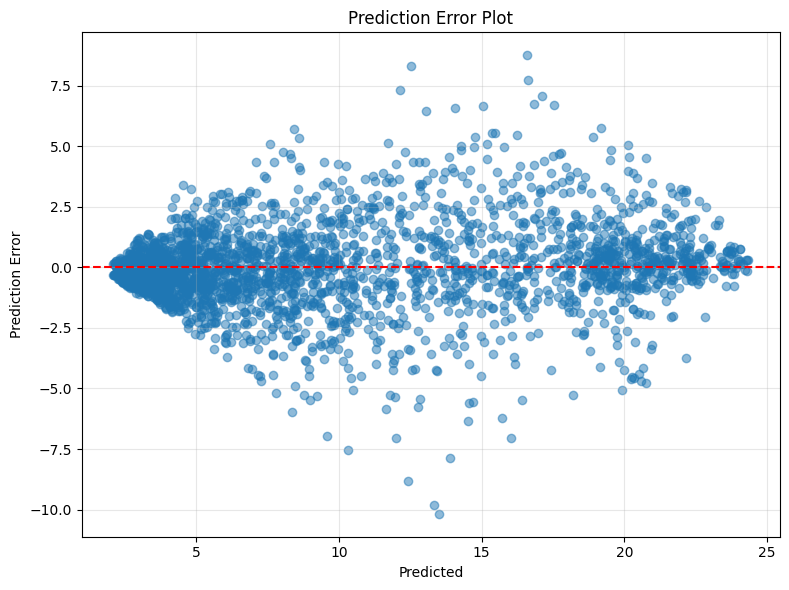

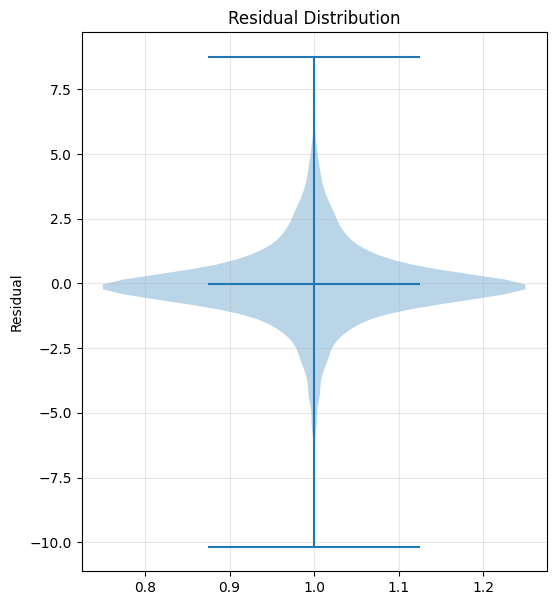

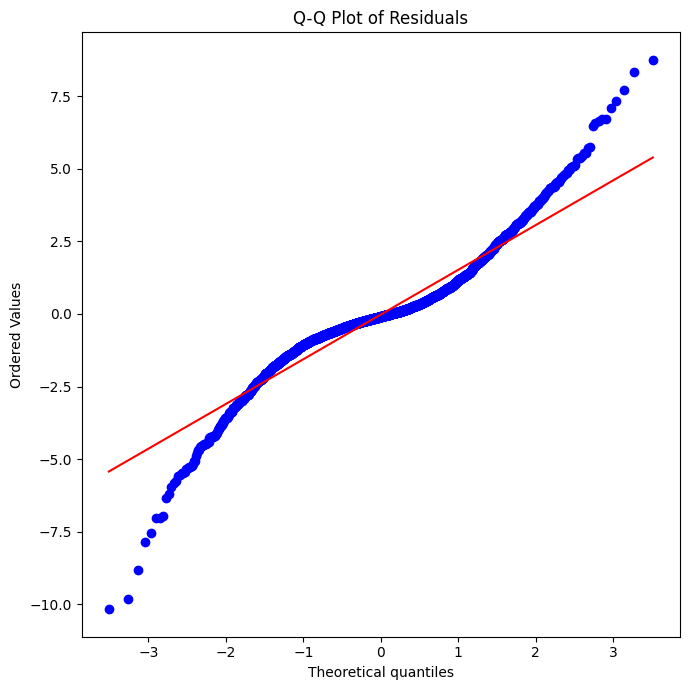

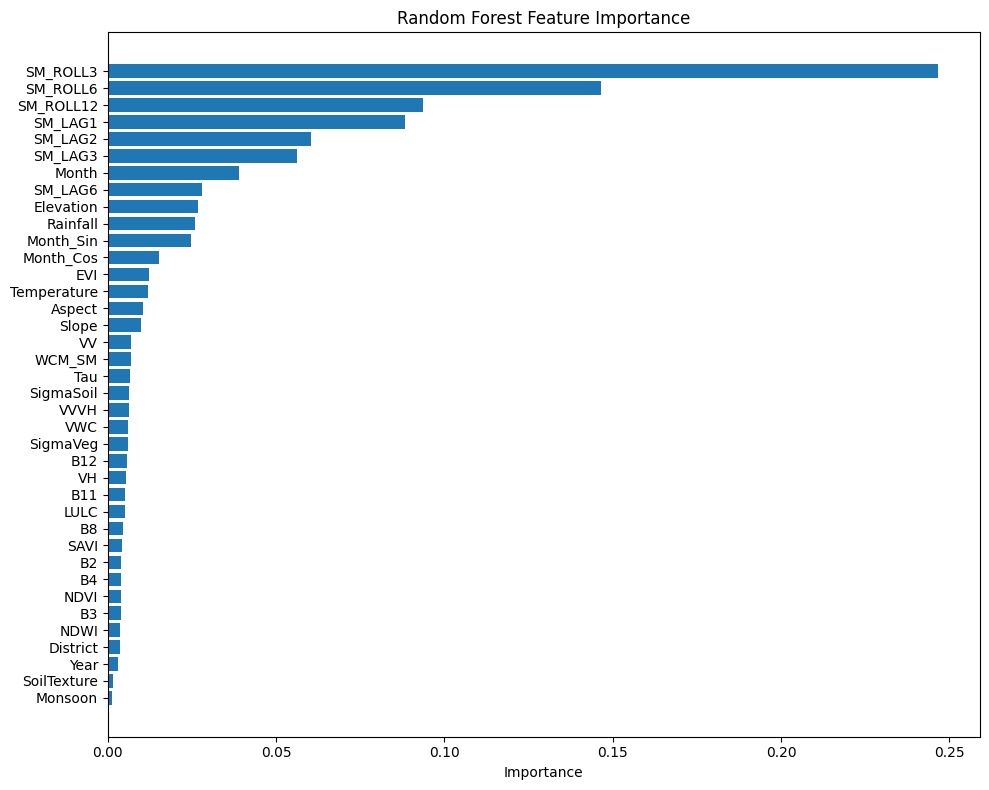

In [ ]:
import skill_metrics as sm
import matplotlib.pyplot as plt
import numpy as np

std_ref = np.std(y_test_rf)
std_model = np.std(rf_pred)

crmsd = np.sqrt(
    np.mean(
        ((rf_pred - np.mean(rf_pred)) -
         (y_test_rf - np.mean(y_test_rf)))**2
    )
)

ccoef = np.corrcoef(y_test_rf.flatten(),
                    rf_pred.flatten())[0,1]

plt.figure(figsize=(8,8))

sm.taylor_diagram(
    std_model,
    crmsd,
    ccoef,
    markerLabel=['RF'],
    markerColor='red'
)

plt.show()

plt.figure(figsize=(8,7))

hb = plt.hexbin(
    y_test_rf.flatten(),
    rf_pred.flatten(),
    gridsize=45,
    cmap="viridis",
    mincnt=1
)

plt.plot(
    [y_test_rf.min(), y_test_rf.max()],
    [y_test_rf.min(), y_test_rf.max()],
    '--',
    color='red',
    linewidth=2
)

plt.xlabel("Observed Soil Moisture")
plt.ylabel("Predicted Soil Moisture")
plt.title("Observed vs Predicted (Density Plot)")

cb = plt.colorbar(hb)
cb.set_label("Sample Density")

plt.tight_layout()
plt.show()

import seaborn as sns

residuals = y_test_rf.flatten()-rf_pred.flatten()

plt.figure(figsize=(8,5))

sns.histplot(
    residuals,
    bins=40,
    kde=True,
    color="royalblue"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution")

plt.tight_layout()
plt.show()

mean = (y_test_rf.flatten()+rf_pred.flatten())/2

diff = y_test_rf.flatten()-rf_pred.flatten()

md = np.mean(diff)
sd = np.std(diff)

plt.figure(figsize=(8,6))

plt.scatter(mean,diff,alpha=0.6)

plt.axhline(md,color='red')

plt.axhline(md+1.96*sd,color='green',linestyle='--')

plt.axhline(md-1.96*sd,color='green',linestyle='--')

plt.xlabel("Mean")
plt.ylabel("Difference")
plt.title("Bland-Altman Plot")

plt.tight_layout()
plt.show()

errors=np.abs(y_test_rf.flatten()-rf_pred.flatten())

sorted_errors=np.sort(errors)

cdf=np.arange(len(errors))/float(len(errors))

plt.figure(figsize=(8,6))

plt.plot(sorted_errors,cdf,
         linewidth=3)

plt.xlabel("Absolute Error")
plt.ylabel("CDF")

plt.title("Cumulative Error Distribution")

plt.grid(alpha=.3)

plt.tight_layout()

plt.show()

from math import pi

metrics=['RMSE','MAE','MSE','R2','NSE','R']

values=[
rmse,
mae,
mse,
r2,
nse,
r
]

angles=np.linspace(
0,
2*np.pi,
len(metrics),
endpoint=False
)

values=np.concatenate((values,[values[0]]))
angles=np.concatenate((angles,[angles[0]]))

fig=plt.figure(figsize=(7,7))

ax=plt.subplot(111,polar=True)

ax.plot(
angles,
values,
linewidth=3
)

ax.fill(
angles,
values,
alpha=0.25
)

ax.set_xticks(angles[:-1])

ax.set_xticklabels(metrics)

plt.title("Performance Metrics Radar")

plt.show()

plt.figure(figsize=(8,6))

errors=y_test_rf-rf_pred

plt.scatter(
rf_pred,
errors,
alpha=.5
)

plt.axhline(
0,
color='red',
linestyle='--'
)

plt.xlabel("Predicted")

plt.ylabel("Prediction Error")

plt.title("Prediction Error Plot")

plt.grid(alpha=.3)

plt.tight_layout()

plt.show()

plt.figure(figsize=(6,7))

plt.violinplot(
residuals,
showmeans=True
)

plt.ylabel("Residual")

plt.title("Residual Distribution")

plt.grid(alpha=.3)

plt.show()

import scipy.stats as stats

plt.figure(figsize=(7,7))

stats.probplot(
residuals,
dist="norm",
plot=plt
)

plt.title("Q-Q Plot of Residuals")

plt.tight_layout()

plt.show()

importance = rf_model.feature_importances_

indices = np.argsort(importance)

plt.figure(figsize=(10,8))

plt.barh(
range(len(indices)),
importance[indices]
)

plt.yticks(
range(len(indices)),
X.columns[indices]
)

plt.xlabel("Importance")

plt.title("Random Forest Feature Importance")

plt.tight_layout()

plt.show()



In [ ]:
# ============================================================
# FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({

'Feature':features,

'Importance':rf_model.feature_importances_

})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

print(
importance.head(20)
)

        Feature  Importance
32     SM_ROLL3    0.246786
33     SM_ROLL6    0.146645
34    SM_ROLL12    0.093604
28      SM_LAG1    0.088198
29      SM_LAG2    0.060444
30      SM_LAG3    0.056147
21        Month    0.039049
31      SM_LAG6    0.028062
15    Elevation    0.026705
13     Rainfall    0.025799
35    Month_Sin    0.024796
36    Month_Cos    0.015265
12          EVI    0.012375
14  Temperature    0.012033
17       Aspect    0.010465
16        Slope    0.009919
0            VV    0.006790
27       WCM_SM    0.006732
24          Tau    0.006436
26    SigmaSoil    0.006347


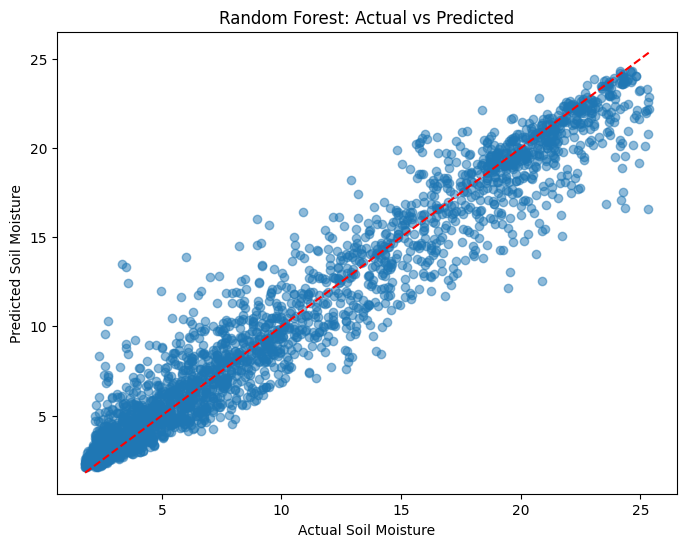

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Soil Moisture")
plt.ylabel("Predicted Soil Moisture")
plt.title("Random Forest: Actual vs Predicted")

plt.show()

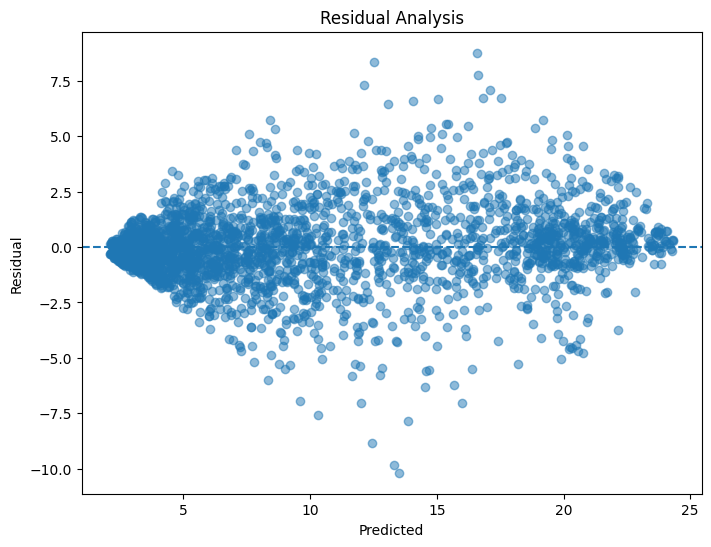

In [ ]:
residuals = y_test - rf_pred

plt.figure(figsize=(8,6))

plt.scatter(
    rf_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel("Predicted")
plt.ylabel("Residual")

plt.title("Residual Analysis")

plt.show()

<Figure size 1000x800 with 0 Axes>

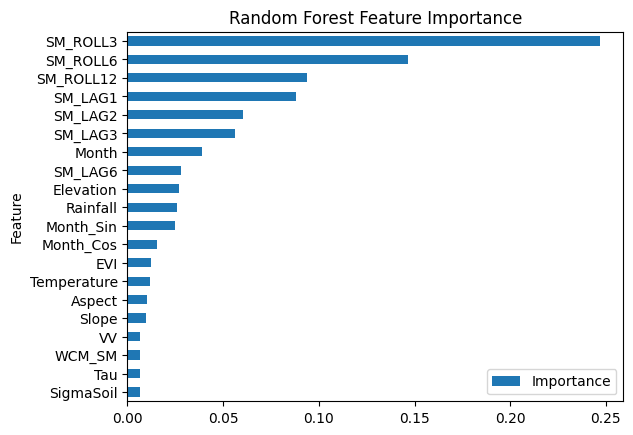

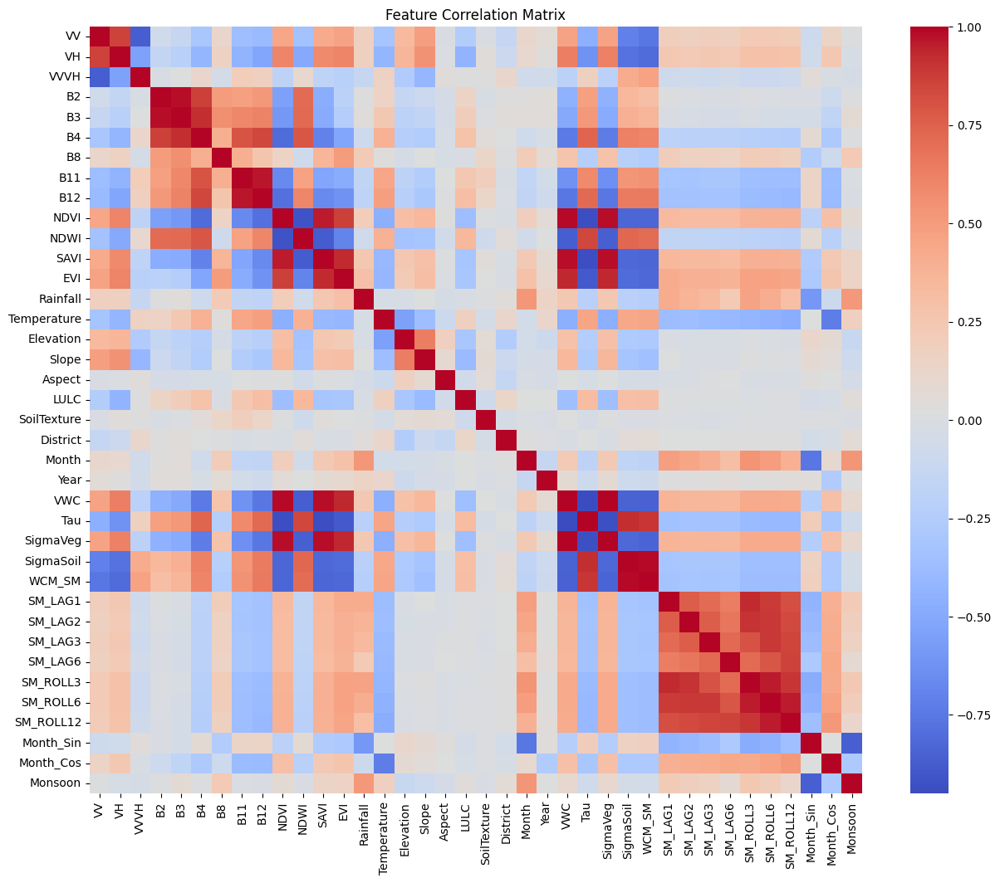

In [ ]:
plt.figure(figsize=(10,8))

importance.head(20).sort_values(
    by="Importance"
).plot(
    kind="barh",
    x="Feature",
    y="Importance"
)

plt.title(
    "Random Forest Feature Importance"
)

plt.show()

import seaborn as sns

corr = df[X.columns].corr()

plt.figure(figsize=(15,12))

sns.heatmap(
    corr,
    cmap='coolwarm'
)

plt.title("Feature Correlation Matrix")

plt.show()

# **XGBOOST**

In [ ]:
# ============================================================
# XGBOOST REGRESSOR
# ============================================================

from xgboost import XGBRegressor

xgb_model = XGBRegressor(

    n_estimators=500,

    learning_rate=0.05,

    max_depth=8,

    subsample=0.8,

    colsample_bytree=0.8,

    objective='reg:squarederror',

    random_state=42
)

xgb_model.fit(
    X_train,
    y_train
)

xgb_pred = xgb_model.predict(
    X_test
)

print("XGBoost Training Completed")

XGBoost Training Completed


In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import numpy as np

mse = mean_squared_error(
    y_test,
    xgb_pred
)

rmse = np.sqrt(mse)

mae = mean_absolute_error(
    y_test,
    xgb_pred
)

r2 = r2_score(
    y_test,
    xgb_pred
)

nse = 1 - (
    np.sum((y_test-xgb_pred)**2)
    /
    np.sum((y_test-np.mean(y_test))**2)
)

r = np.corrcoef(
    y_test,
    xgb_pred
)[0,1]

xgb_results = {

    "Model":"XGBoost",

    "RMSE":rmse,

    "MAE":mae,

    "MSE":mse,

    "R2":r2,

    "NSE":nse,

    "R":r
}

print(xgb_results)

joblib.dump(
    xgb_model,
    "xgb_model.pkl"
)

{'Model': 'XGBoost', 'RMSE': np.float64(0.5118002183175402), 'MAE': 0.30457075482699714, 'MSE': 0.26193946346988184, 'R2': 0.994552043413255, 'NSE': np.float64(0.994552043413255), 'R': np.float64(0.9973369425844435)}


['xgb_model.pkl']

XGBoost Performance
RMSE : 0.51180
MAE  : 0.30457
MSE  : 0.26194
R²   : 0.99455
NSE  : 0.99455
R    : 0.99734


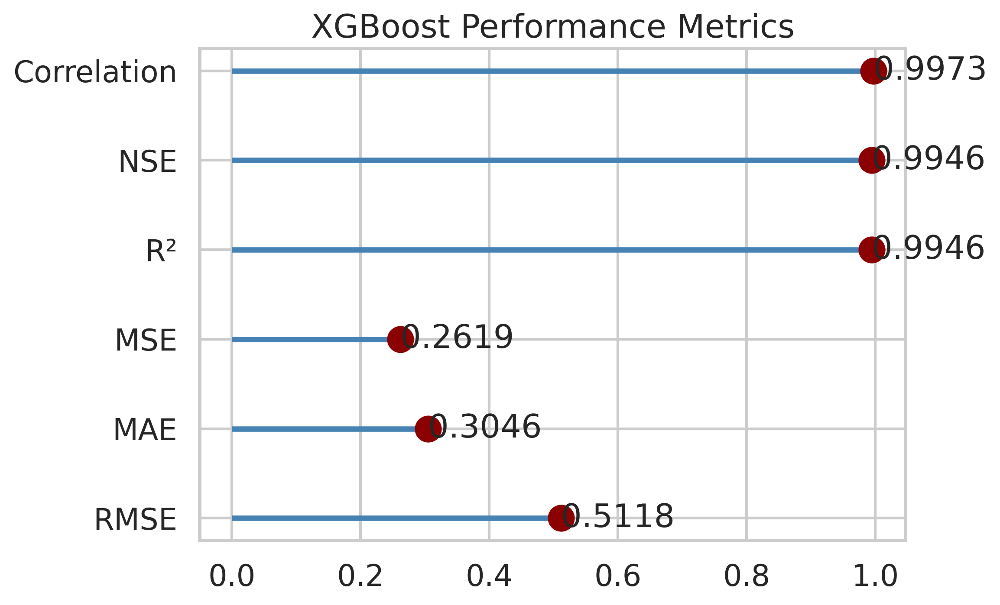

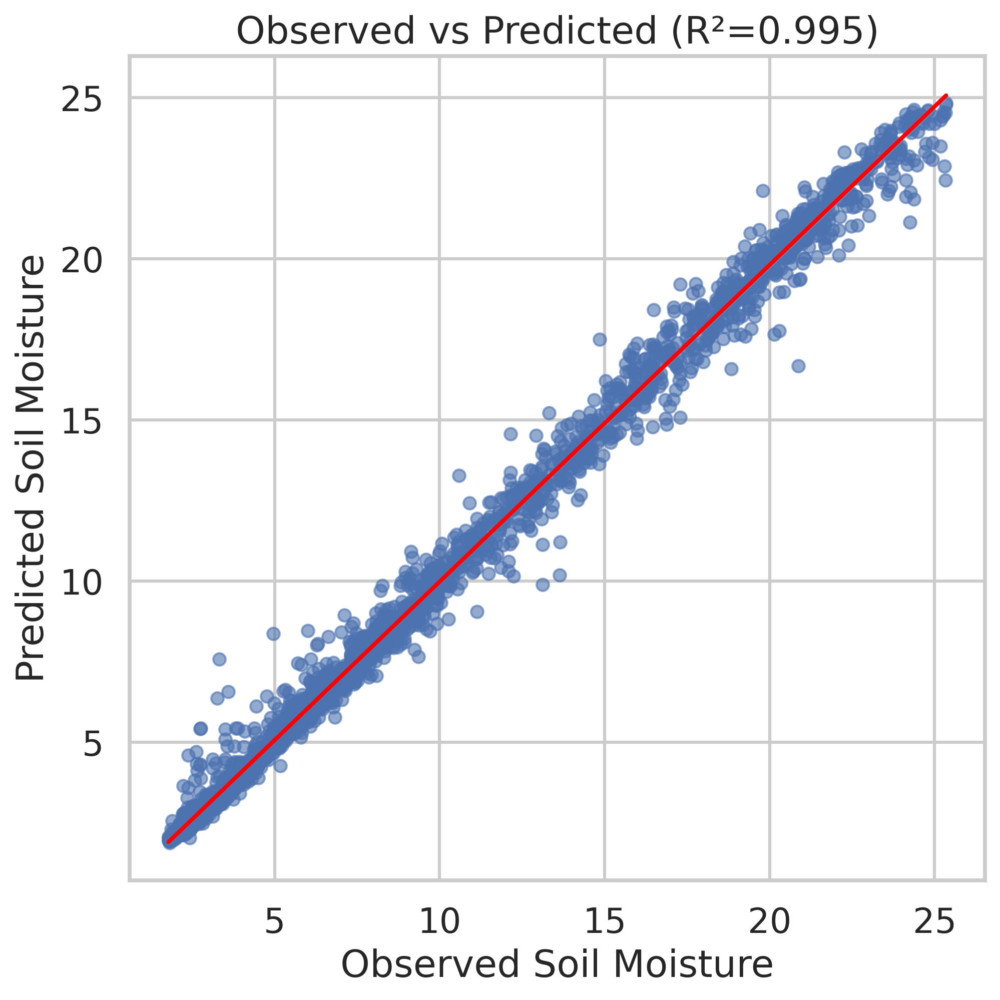

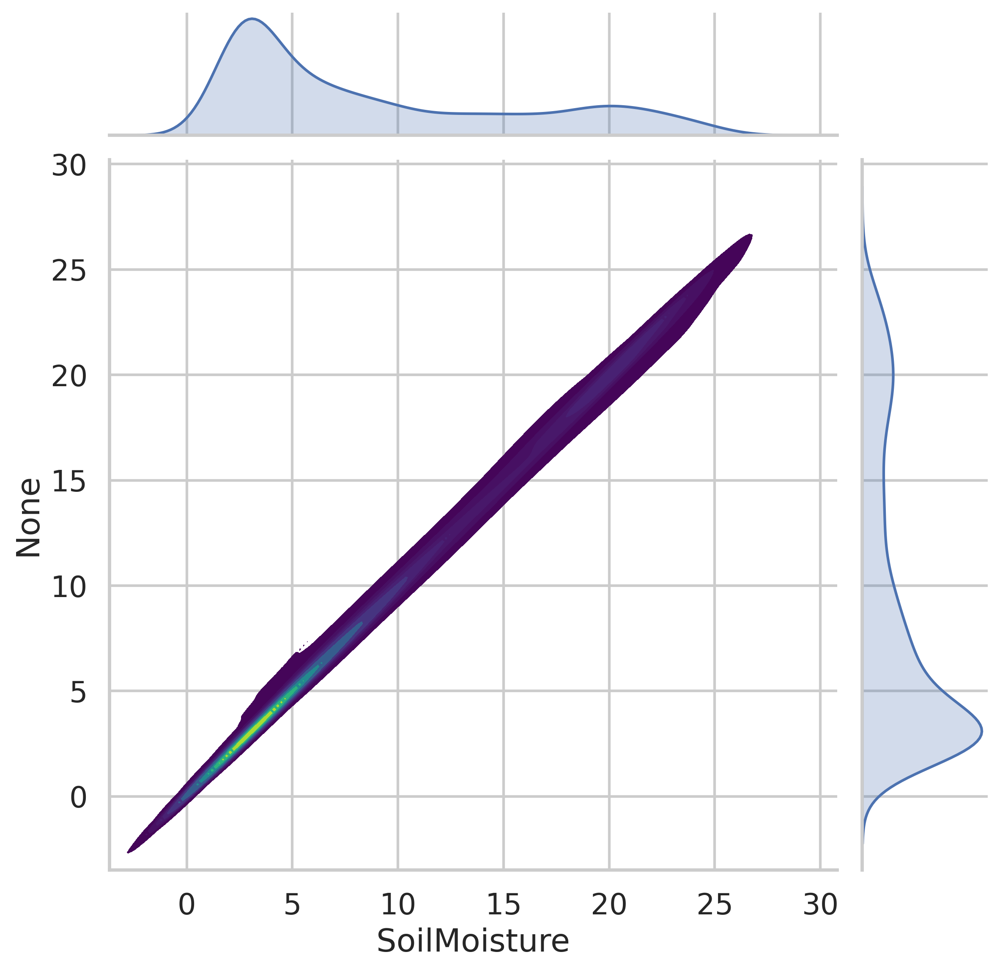

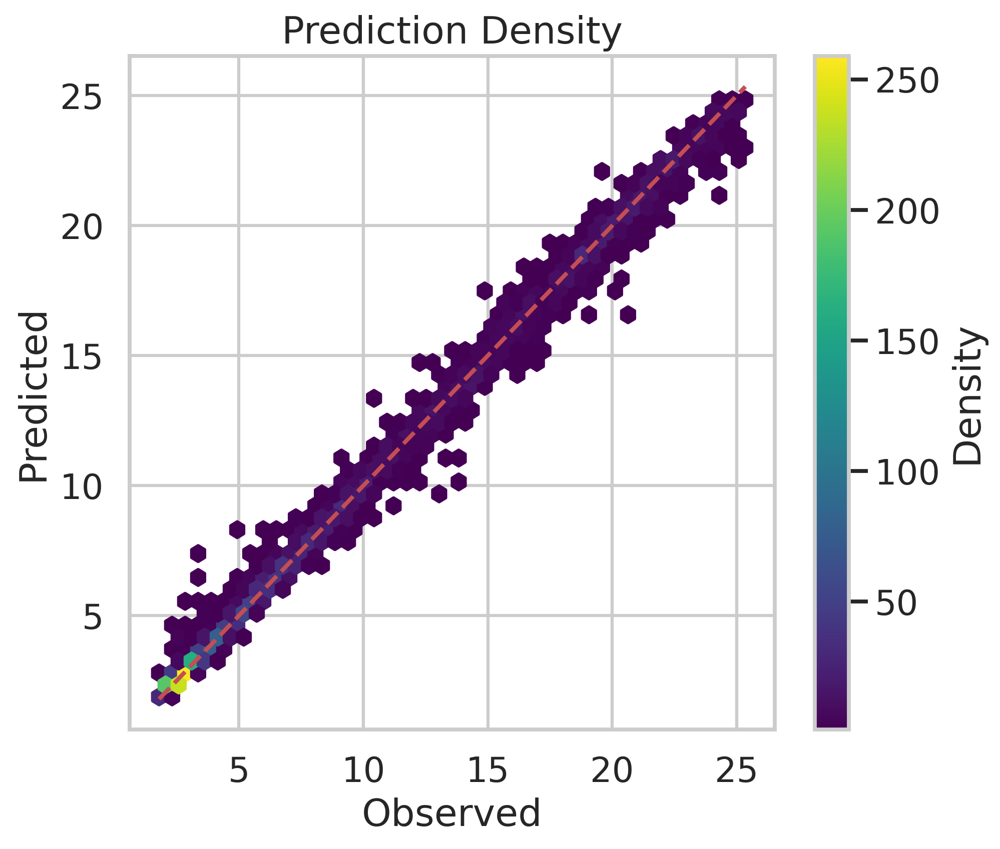

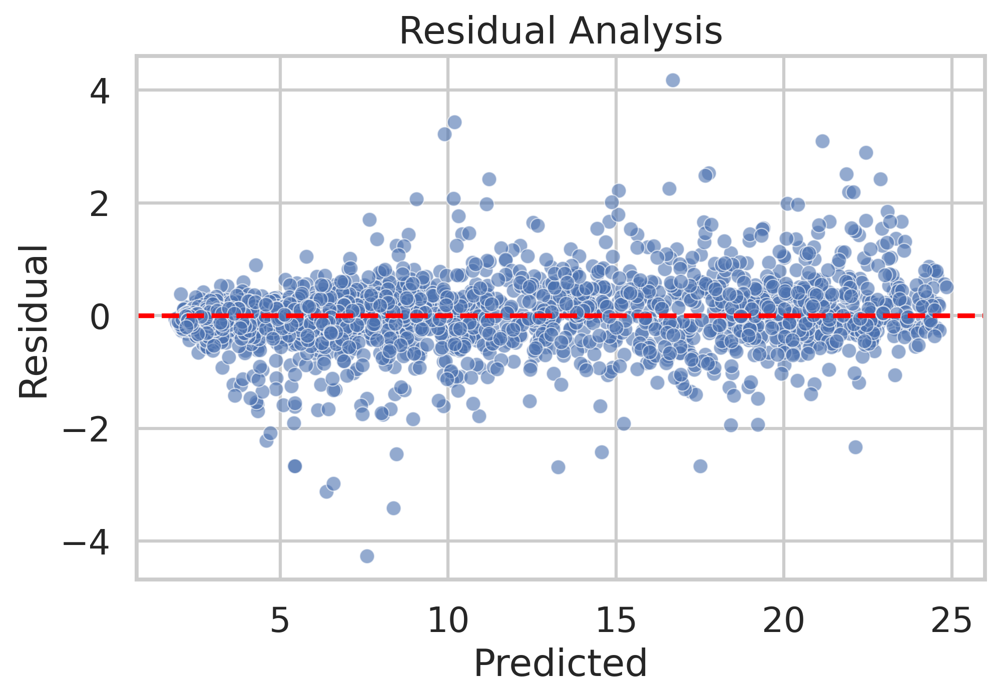

...

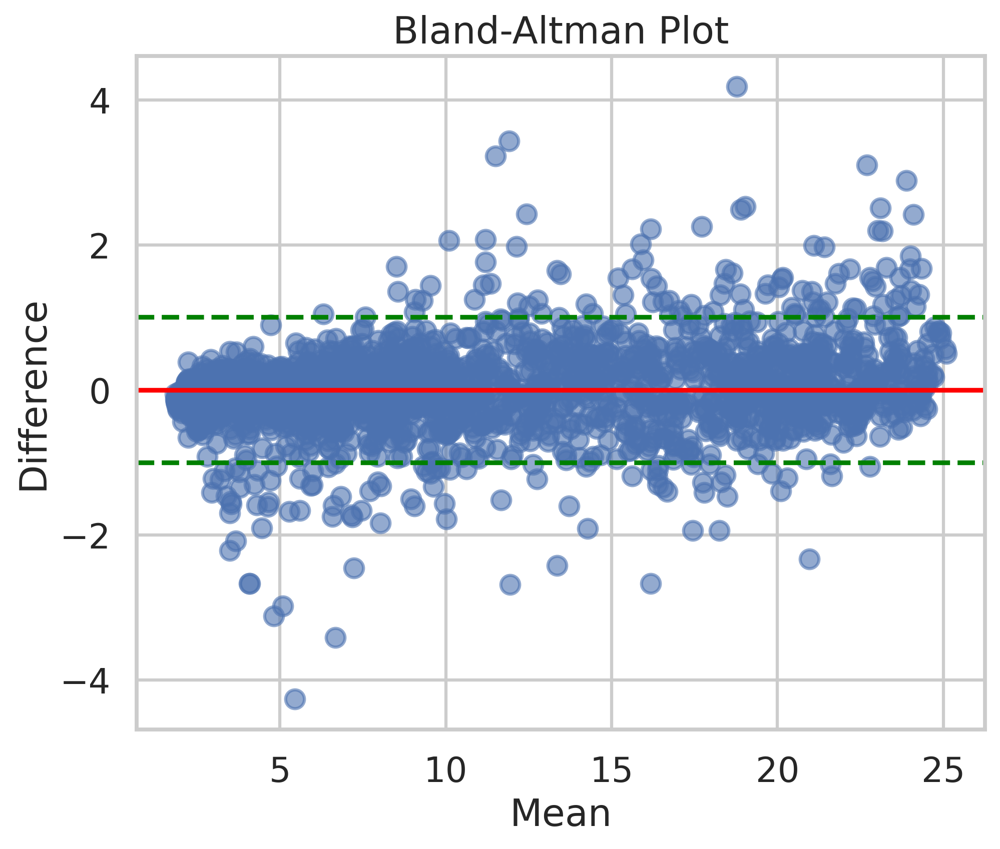

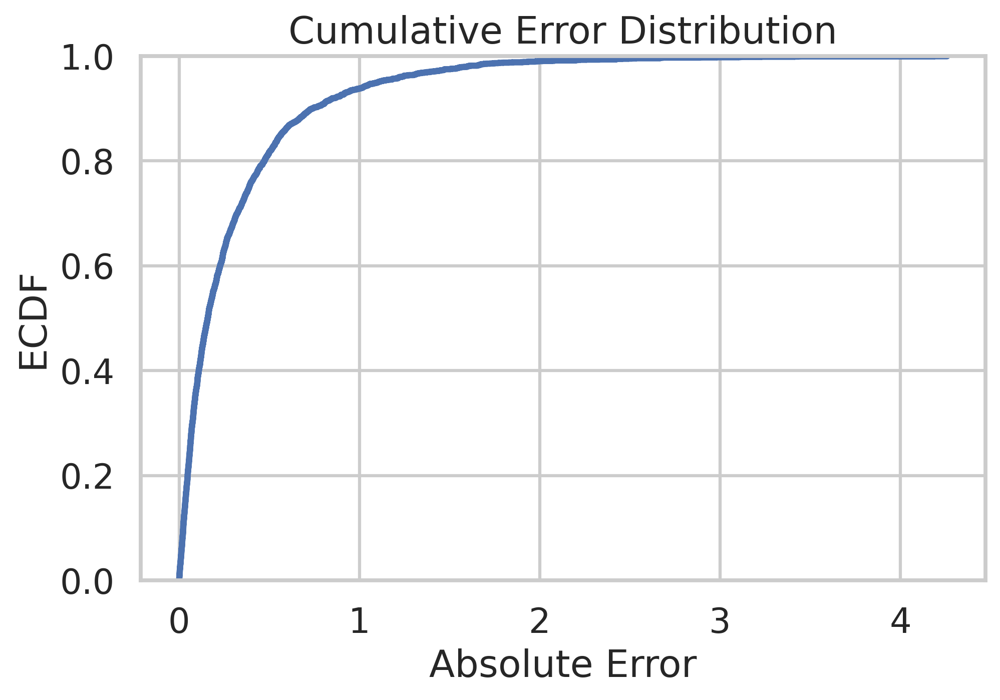

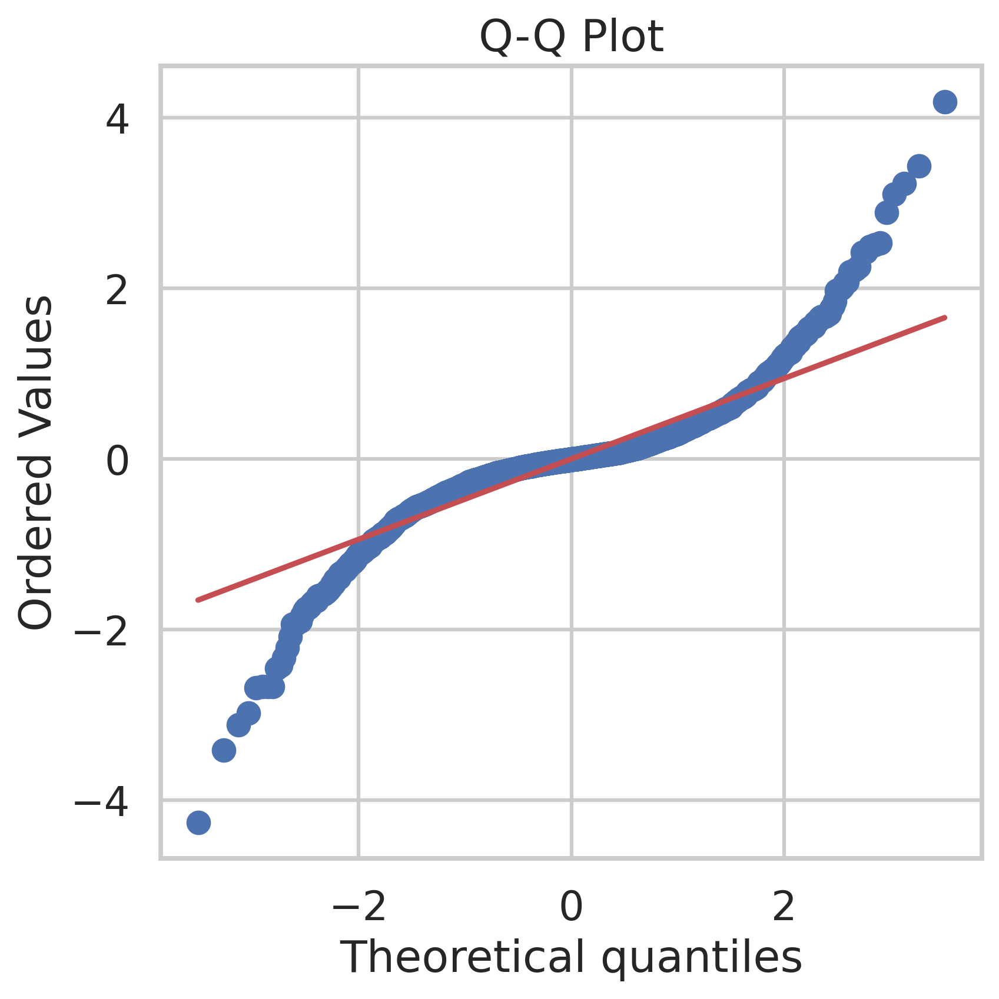

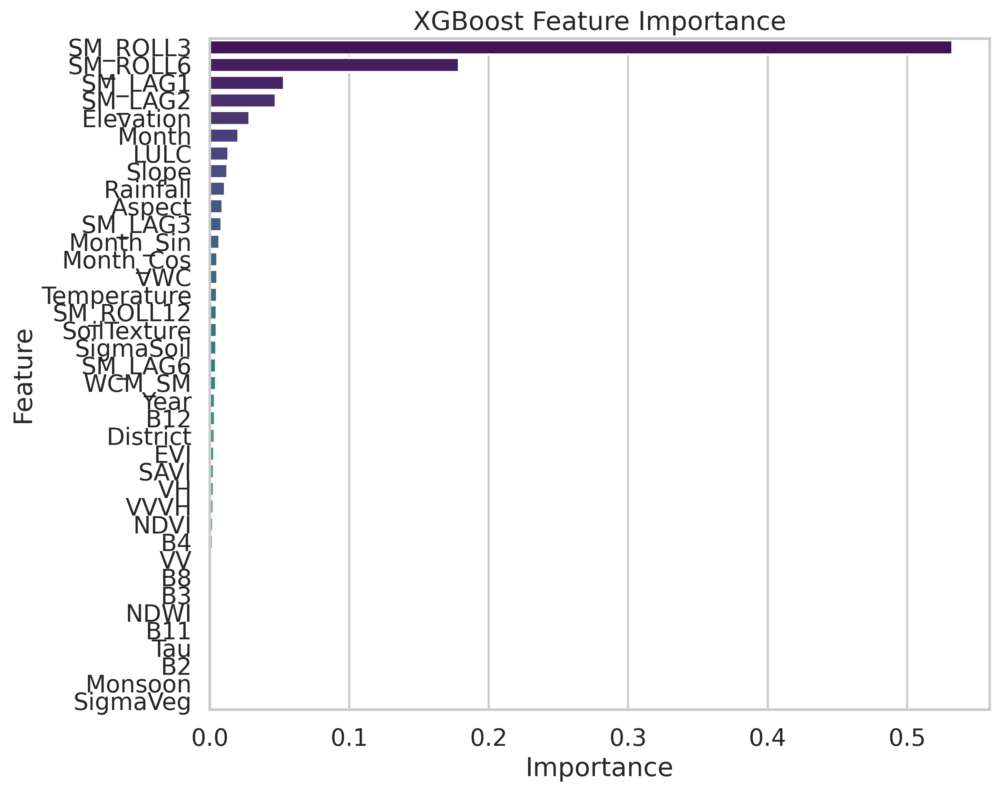

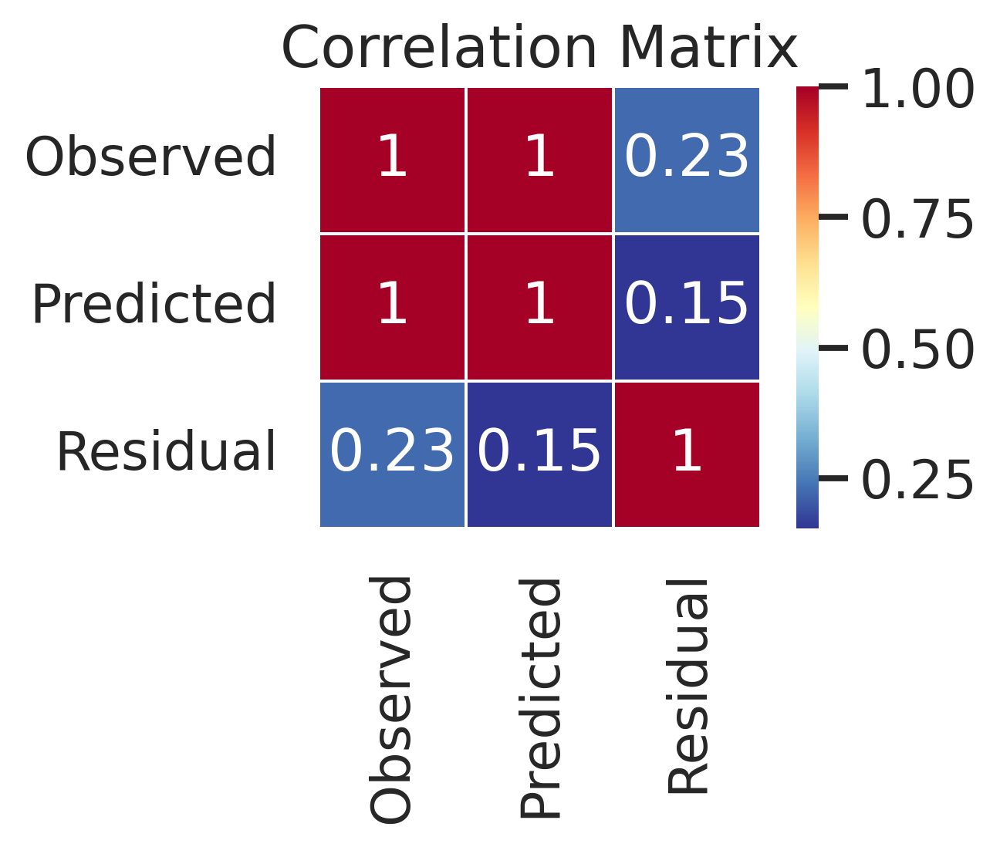

In [ ]:
# ==========================================================
# XGBOOST JOURNAL QUALITY PERFORMANCE VISUALIZATION
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import joblib

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (8,6)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300

# ==========================================================
# PERFORMANCE METRICS
# ==========================================================

mse = mean_squared_error(y_test, xgb_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, xgb_pred)
r2 = r2_score(y_test, xgb_pred)

nse = 1 - (
    np.sum((y_test-xgb_pred)**2)
    /
    np.sum((y_test-np.mean(y_test))**2)
)

r = np.corrcoef(
    np.ravel(y_test),
    np.ravel(xgb_pred)
)[0,1]

print("="*60)
print("XGBoost Performance")
print("="*60)

print(f"RMSE : {rmse:.5f}")
print(f"MAE  : {mae:.5f}")
print(f"MSE  : {mse:.5f}")
print(f"R²   : {r2:.5f}")
print(f"NSE  : {nse:.5f}")
print(f"R    : {r:.5f}")

# ==========================================================
# SAVE MODEL
# ==========================================================

joblib.dump(
    xgb_model,
    "xgb_model.pkl"
)

# ==========================================================
# DATAFRAME
# ==========================================================

metrics = pd.DataFrame({
    "Metric":["RMSE","MAE","MSE","R²","NSE","Correlation"],
    "Value":[rmse,mae,mse,r2,nse,r]
})

# ==========================================================
# 1. LOLLIPOP METRICS CHART
# ==========================================================

plt.figure(figsize=(8,5))

plt.hlines(
    y=metrics["Metric"],
    xmin=0,
    xmax=metrics["Value"],
    color="steelblue",
    linewidth=3
)

plt.scatter(
    metrics["Value"],
    metrics["Metric"],
    s=180,
    color="darkred",
    zorder=3
)

for i,v in enumerate(metrics["Value"]):
    plt.text(v,i,f"{v:.4f}",va='center')

plt.title("XGBoost Performance Metrics")
plt.tight_layout()
plt.show()

# ==========================================================
# 2. REGRESSION PLOT
# ==========================================================

plt.figure(figsize=(7,7))

sns.regplot(
    x=y_test,
    y=xgb_pred,
    scatter_kws={
        "s":35,
        "alpha":0.6
    },
    line_kws={
        "color":"red",
        "linewidth":2
    }
)

plt.xlabel("Observed Soil Moisture")
plt.ylabel("Predicted Soil Moisture")

plt.title(f"Observed vs Predicted (R²={r2:.3f})")

plt.tight_layout()
plt.show()

# ==========================================================
# 3. JOINT KDE
# ==========================================================

sns.jointplot(
    x=y_test,
    y=xgb_pred,
    kind="kde",
    fill=True,
    cmap="viridis",
    height=8
)

plt.show()

# ==========================================================
# 4. HEXBIN DENSITY
# ==========================================================

plt.figure(figsize=(7,6))

hb = plt.hexbin(
    y_test,
    xgb_pred,
    gridsize=45,
    cmap="viridis",
    mincnt=1
)

plt.plot(
    [np.min(y_test),np.max(y_test)],
    [np.min(y_test),np.max(y_test)],
    'r--',
    linewidth=2
)

cb = plt.colorbar(hb)
cb.set_label("Density")

plt.xlabel("Observed")
plt.ylabel("Predicted")

plt.title("Prediction Density")

plt.tight_layout()
plt.show()

# ==========================================================
# 5. RESIDUAL SCATTER
# ==========================================================

residuals = np.ravel(y_test)-np.ravel(xgb_pred)

plt.figure(figsize=(7,5))

sns.scatterplot(
    x=xgb_pred,
    y=residuals,
    s=50,
    alpha=0.6
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted")
plt.ylabel("Residual")

plt.title("Residual Analysis")

plt.tight_layout()
plt.show()

# ==========================================================
# 6. HISTOGRAM + KDE
# ==========================================================

plt.figure(figsize=(7,5))

sns.histplot(
    residuals,
    bins=40,
    kde=True,
    color="royalblue"
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.title("Residual Distribution")

plt.tight_layout()
plt.show()

# ==========================================================
# 7. VIOLIN PLOT
# ==========================================================

plt.figure(figsize=(5,7))

sns.violinplot(
    y=residuals,
    inner="box",
    color="skyblue"
)

sns.stripplot(
    y=residuals,
    color="black",
    alpha=.25,
    size=2
)

plt.title("Residual Distribution")

plt.tight_layout()
plt.show()

# ==========================================================
# 8. BLAND ALTMAN
# ==========================================================

mean = (np.ravel(y_test)+np.ravel(xgb_pred))/2

diff = np.ravel(y_test)-np.ravel(xgb_pred)

md = np.mean(diff)
sd = np.std(diff)

plt.figure(figsize=(7,6))

plt.scatter(
    mean,
    diff,
    alpha=0.6
)

plt.axhline(md,color="red")

plt.axhline(md+1.96*sd,color="green",linestyle="--")

plt.axhline(md-1.96*sd,color="green",linestyle="--")

plt.xlabel("Mean")

plt.ylabel("Difference")

plt.title("Bland-Altman Plot")

plt.tight_layout()
plt.show()

# ==========================================================
# 9. ECDF
# ==========================================================

plt.figure(figsize=(7,5))

sns.ecdfplot(
    np.abs(residuals),
    linewidth=3
)

plt.xlabel("Absolute Error")
plt.ylabel("ECDF")

plt.title("Cumulative Error Distribution")

plt.tight_layout()
plt.show()

# ==========================================================
# 10. QQ PLOT
# ==========================================================

plt.figure(figsize=(6,6))

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot")

plt.tight_layout()
plt.show()

# ==========================================================
# 11. FEATURE IMPORTANCE
# ==========================================================

importance = xgb_model.feature_importances_

feature_df = pd.DataFrame({
    "Feature":X_train.columns,
    "Importance":importance
})

feature_df = feature_df.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,8))

sns.barplot(
    data=feature_df,
    y="Feature",
    x="Importance",
    palette="viridis"
)

plt.title("XGBoost Feature Importance")

plt.tight_layout()
plt.show()

# ==========================================================
# 12. CORRELATION HEATMAP
# ==========================================================

corr_df = pd.DataFrame({
    "Observed":np.ravel(y_test),
    "Predicted":np.ravel(xgb_pred),
    "Residual":residuals
})

plt.figure(figsize=(5,4))

sns.heatmap(
    corr_df.corr(),
    annot=True,
    cmap="RdYlBu_r",
    square=True,
    linewidths=.5
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

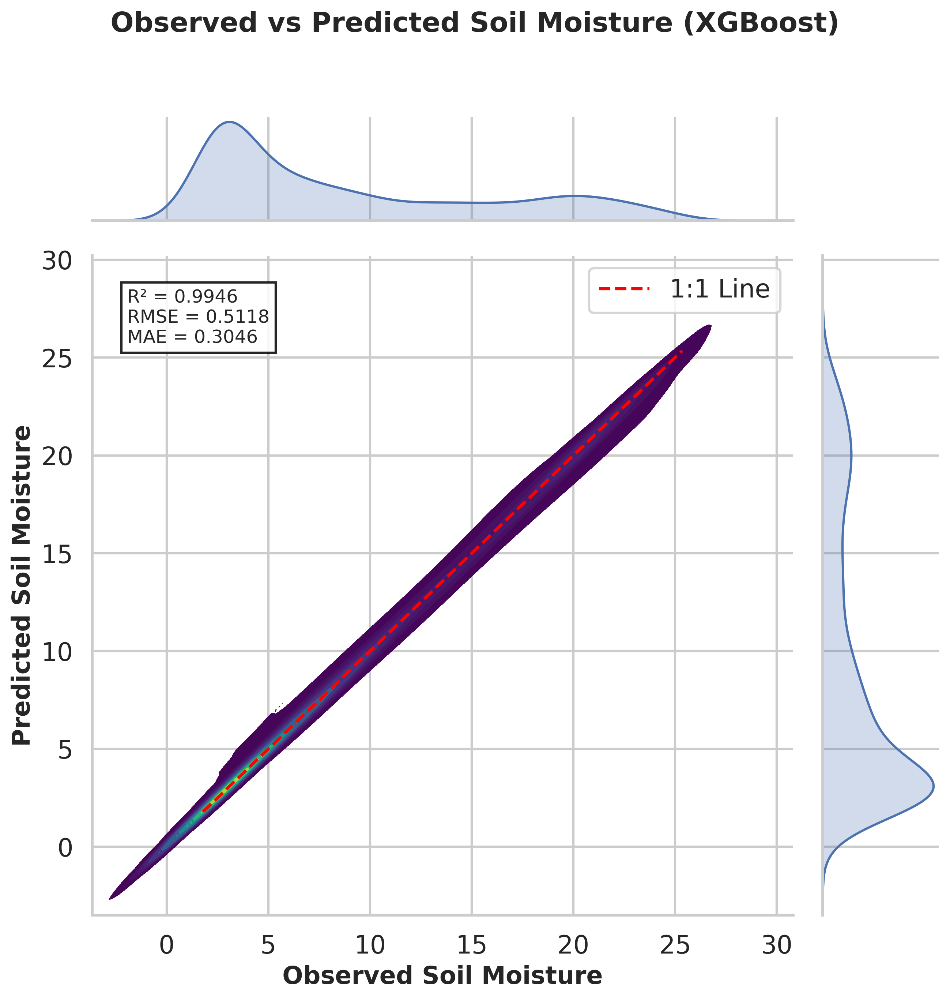

In [ ]:
# ==========================================================
# JOURNAL QUALITY JOINT KDE PLOT (XGBOOST)
# ==========================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ----------------------------------------------------------
# Metrics
# ----------------------------------------------------------

y_true = np.ravel(y_test)
y_pred = np.ravel(xgb_pred)

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

# ----------------------------------------------------------
# DataFrame for Seaborn
# ----------------------------------------------------------

plot_df = pd.DataFrame({
    "Observed Soil Moisture": y_true,
    "Predicted Soil Moisture": y_pred
})

# ----------------------------------------------------------
# Plot Style
# ----------------------------------------------------------

sns.set_theme(
    style="whitegrid",
    context="talk"
)

# ----------------------------------------------------------
# Joint KDE Plot
# ----------------------------------------------------------

g = sns.jointplot(
    data=plot_df,
    x="Observed Soil Moisture",
    y="Predicted Soil Moisture",
    kind="kde",
    fill=True,
    cmap="viridis",
    height=9,
    space=0
)

# ----------------------------------------------------------
# Add 1:1 Reference Line
# ----------------------------------------------------------

xmin = min(y_true.min(), y_pred.min())
xmax = max(y_true.max(), y_pred.max())

g.ax_joint.plot(
    [xmin, xmax],
    [xmin, xmax],
    '--',
    color='red',
    linewidth=2,
    label='1:1 Line'
)

# ----------------------------------------------------------
# Performance Metrics Box
# ----------------------------------------------------------

text = (
    f"R² = {r2:.4f}\n"
    f"RMSE = {rmse:.4f}\n"
    f"MAE = {mae:.4f}"
)

g.ax_joint.text(
    0.05,
    0.95,
    text,
    transform=g.ax_joint.transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(
        facecolor='white',
        alpha=0.85,
        edgecolor='black'
    )
)

# ----------------------------------------------------------
# Labels
# ----------------------------------------------------------

g.ax_joint.set_xlabel(
    "Observed Soil Moisture",
    fontsize=16,
    fontweight="bold"
)

g.ax_joint.set_ylabel(
    "Predicted Soil Moisture",
    fontsize=16,
    fontweight="bold"
)

g.ax_joint.legend()

plt.suptitle(
    "Observed vs Predicted Soil Moisture (XGBoost)",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.show()

In [ ]:
xgb_model = joblib.load(
    "xgb_model.pkl"
)

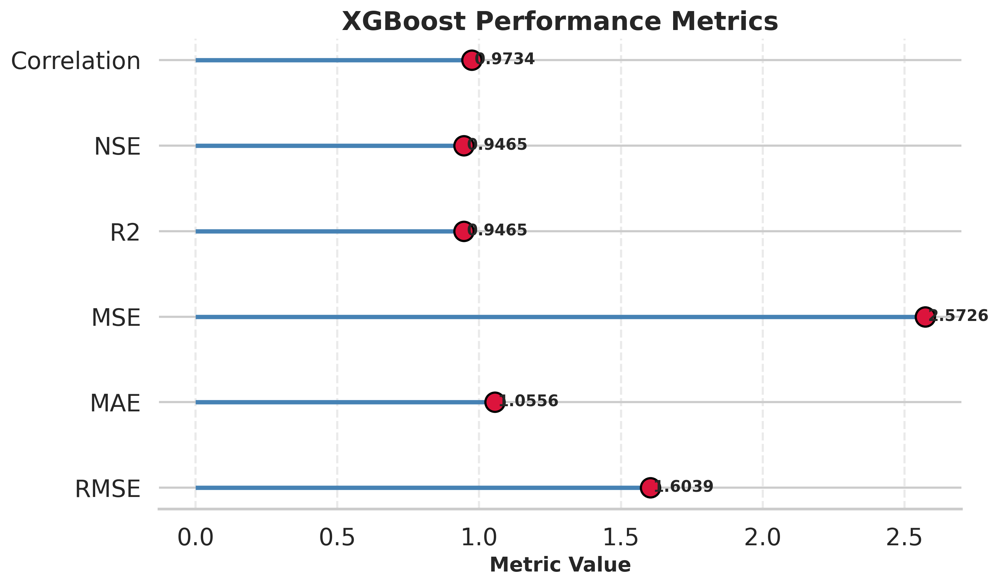

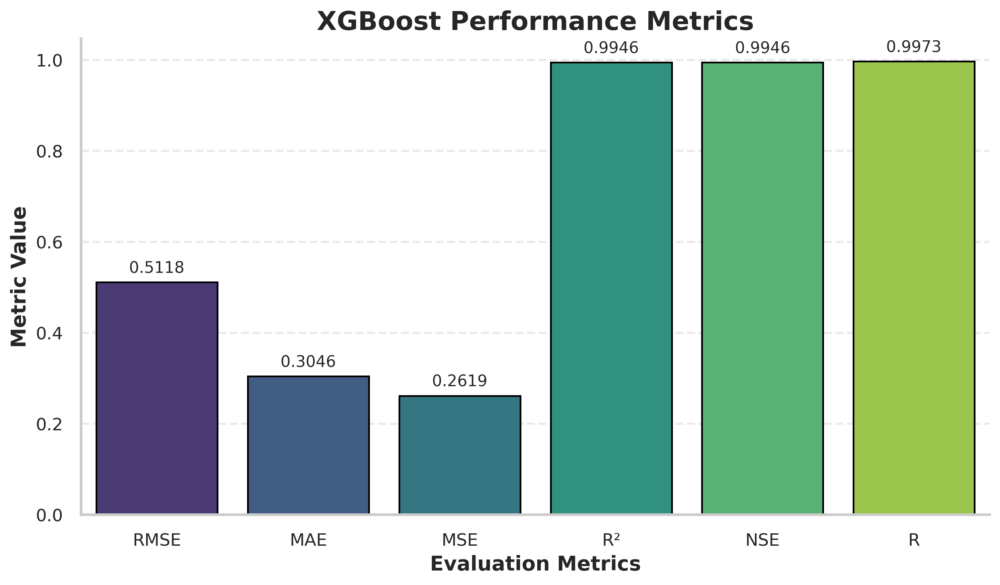

In [ ]:
# ==========================================================
# LOLLIPOP CHART (JOURNAL STYLE)
# ==========================================================

plt.figure(figsize=(10,6), dpi=300)

plt.hlines(
    y=metrics_df["Metric"],
    xmin=0,
    xmax=metrics_df["Value"],
    color="steelblue",
    linewidth=3
)

plt.scatter(
    metrics_df["Value"],
    metrics_df["Metric"],
    s=180,
    color="crimson",
    edgecolor="black",
    zorder=3
)

for i, value in enumerate(metrics_df["Value"]):
    plt.text(
        value + 0.01,
        i,
        f"{value:.4f}",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "XGBoost Performance Metrics",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Metric Value",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("")

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

sns.despine(left=True)

plt.tight_layout()
plt.show()

# ==========================================================
# XGBOOST PERFORMANCE METRICS (SEABORN STYLE)
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Seaborn Theme
sns.set_theme(
    style="whitegrid",
    context="talk",
    palette="viridis"
)

# Metrics DataFrame
metrics_df = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "MSE", "R²", "NSE", "R"],
    "Value": [
        xgb_results["RMSE"],
        xgb_results["MAE"],
        xgb_results["MSE"],
        xgb_results["R2"],
        xgb_results["NSE"],
        xgb_results["R"]
    ]
})

# Create Figure
plt.figure(figsize=(10,6), dpi=300)

ax = sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Value",
    hue="Metric",
    palette="viridis",
    legend=False,
    edgecolor="black",
    linewidth=1.2
)

# Add value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        fontsize=11,
        padding=4
    )

# Labels
plt.title(
    "XGBoost Performance Metrics",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Evaluation Metrics",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    "Metric Value",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

sns.despine()

plt.tight_layout()

plt.show()

In [ ]:

from sklearn.preprocessing import LabelEncoder
import pandas as pd

district_encoder = LabelEncoder()

df['District'] = district_encoder.fit_transform(
    df['District']
)

# later recover
df['District_Name'] = district_encoder.inverse_transform(
    df['District']
)

# Create 'Date_for_plot' from the existing 'Date' column and convert to datetime
df['Date_for_plot'] = pd.to_datetime(df['Date'])

print(df[['District_Name','Date_for_plot']].head())

print(df.shape)
print(len(features))
print(df["Date_for_plot"].head())

print(df[['District','Date_for_plot']].head(20))
print(df['District'].value_counts().head())

   District_Name Date_for_plot
0              0    2018-09-01
1              0    2018-09-01
2              0    2018-09-01
3              0    2018-09-01
4              0    2018-09-01
(15575, 52)
38
0   2018-09-01
1   2018-09-01
2   2018-09-01
3   2018-09-01
4   2018-09-01
Name: Date_for_plot, dtype: datetime64[ns]
    District Date_for_plot
0          0    2018-09-01
1          0    2018-09-01
2          0    2018-09-01
3          0    2018-09-01
4          0    2018-09-01
5          0    2018-11-01
6          0    2018-11-01
7          0    2018-12-01
8          0    2018-12-01
9          0    2019-01-01
10         0    2019-01-01
11         0    2019-01-01
12         0    2019-01-01
13         0    2019-01-01
14         0    2019-01-01
15         0    2019-01-01
16         0    2019-02-01
17         0    2019-02-01
18         0    2019-02-01
19         0    2019-02-01
District
3     1472
5      935
24     889
26     874
25     839
Name: count, dtype: int64


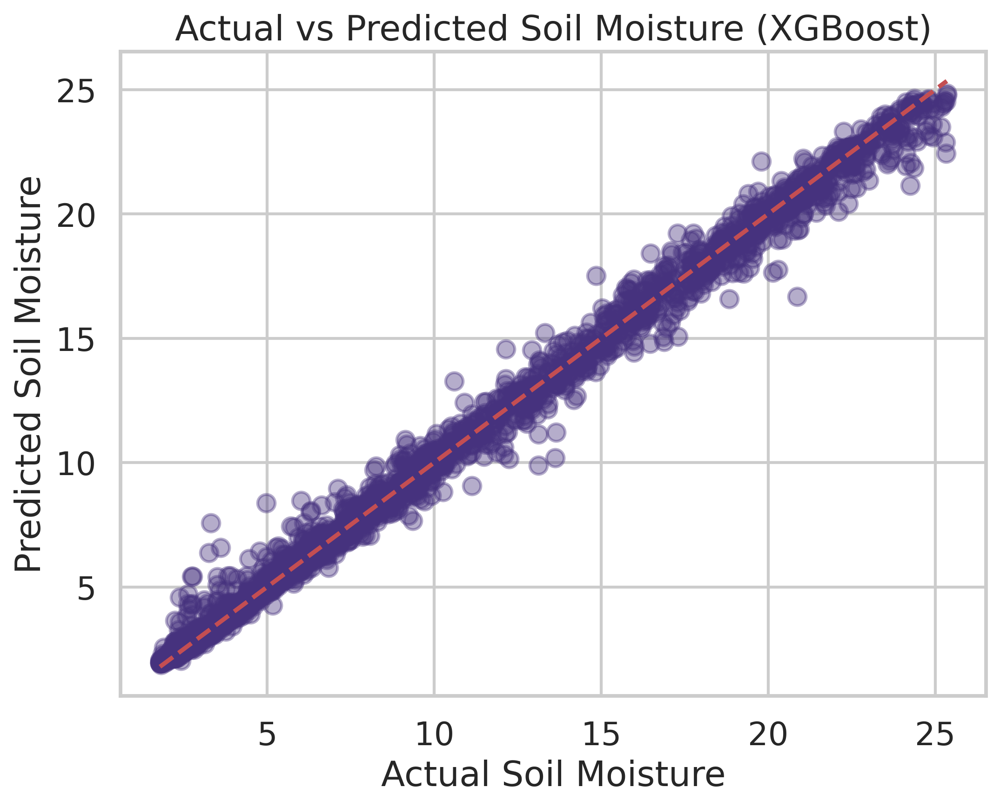

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    xgb_pred,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Soil Moisture")
plt.ylabel("Predicted Soil Moisture")
plt.title("Actual vs Predicted Soil Moisture (XGBoost)")
plt.grid(True)

plt.show()

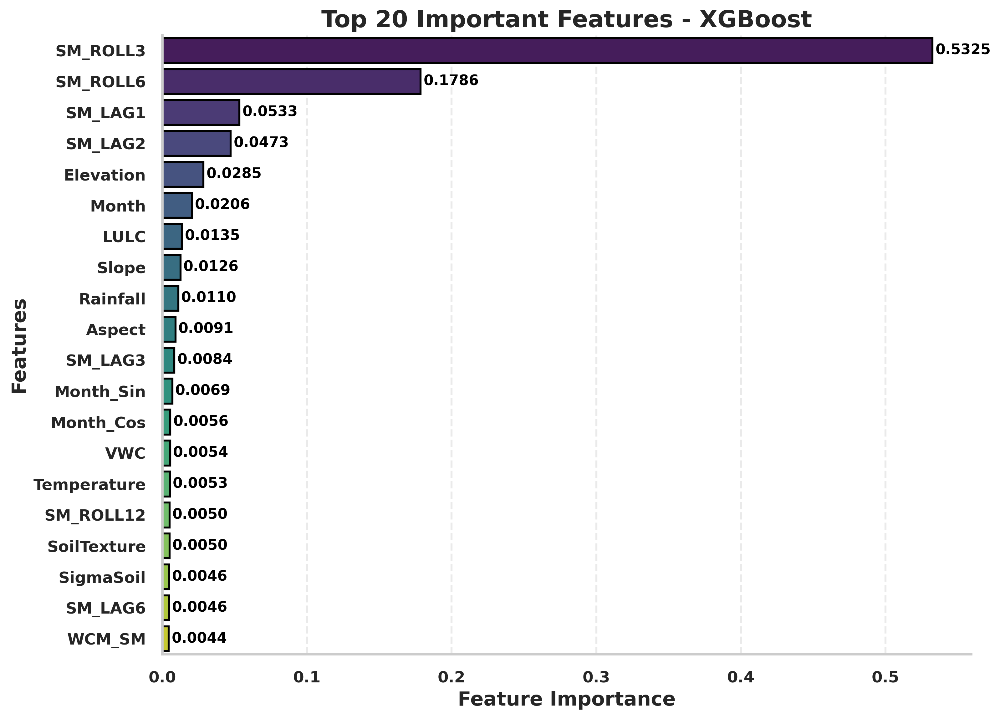

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Journal Style
sns.set_theme(style="whitegrid", context="talk")

# Feature Importance
importance = xgb_model.feature_importances_

feat_imp = pd.DataFrame({
    "Feature": X_train.columns.tolist(),
    "Importance": importance
})

feat_imp = feat_imp.sort_values(
    by="Importance",
    ascending=False
)

# Top 20 Features
top_features = feat_imp.head(20)

plt.figure(figsize=(11,8), dpi=300)

ax = sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    palette="viridis",
    edgecolor="black"
)

# ---------------------------------------------------
# Add Importance Values (Bold)
# ---------------------------------------------------

for i, value in enumerate(top_features["Importance"]):
    ax.text(
        value + 0.002,
        i,
        f"{value:.4f}",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="black"
    )

# ---------------------------------------------------
# Labels
# ---------------------------------------------------

plt.xlabel(
    "Feature Importance",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel(
    "Features",
    fontsize=15,
    fontweight="bold"
)

plt.title(
    "Top 20 Important Features - XGBoost",
    fontsize=18,
    fontweight="bold"
)

# Bold Tick Labels
plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold")

# Grid
plt.grid(axis="x", linestyle="--", alpha=0.4)

# Remove Extra Borders
sns.despine()

plt.tight_layout()
plt.show()

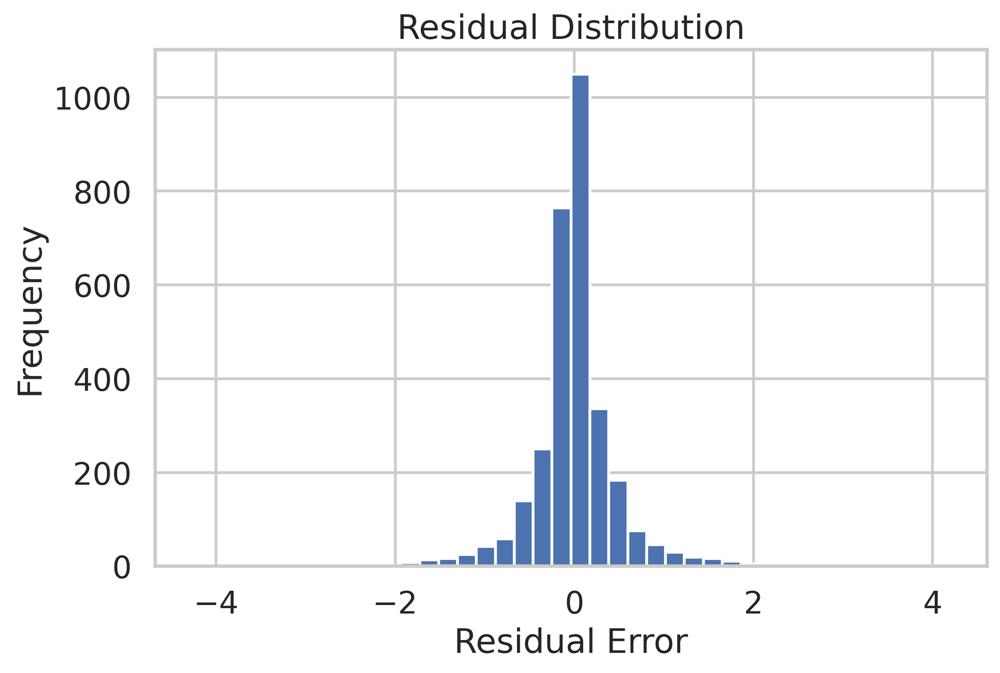

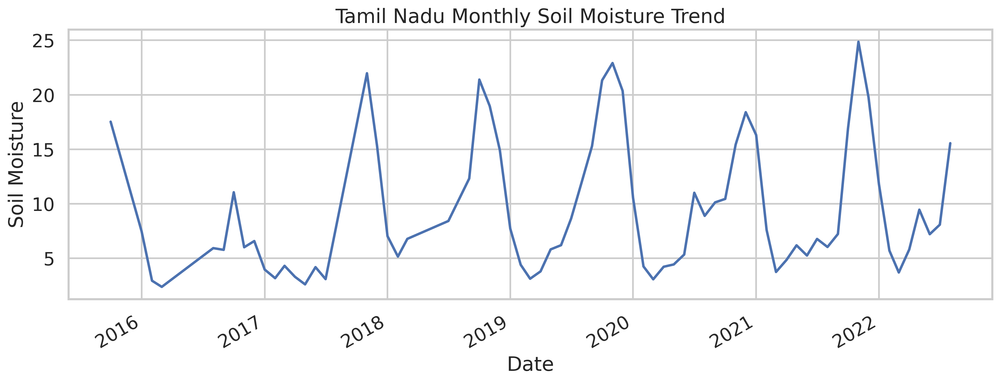

In [ ]:
residuals = y_test - xgb_pred

plt.figure(figsize=(8,5))

plt.hist(
    residuals,
    bins=40
)

plt.xlabel("Residual Error")
plt.ylabel("Frequency")

plt.title("Residual Distribution")

plt.show()

# Ensure 'Date_for_plot' is present before use, in case df was reset
df['Date_for_plot'] = pd.to_datetime(df['Date'])

df_plot = df.copy()

monthly = df_plot.groupby(
    "Date_for_plot"
)["SoilMoisture"].mean()

plt.figure(figsize=(15,5))

monthly.plot()

plt.title("Tamil Nadu Monthly Soil Moisture Trend")
plt.ylabel("Soil Moisture")
plt.xlabel("Date")

plt.grid(True)

plt.show()

In [ ]:
df["LocationID"] = (
    df["Latitude"].round(4).astype(str)
    + "_"
    + df["Longitude"].round(4).astype(str)
)

df["Date_for_plot"] = pd.to_datetime(df["Date_for_plot"])

df = df.sort_values(
    ["LocationID","Date_for_plot"]
)

print(df["District"].nunique())

print(df["LocationID"].nunique())

df.groupby("LocationID").size().describe()

28
391


,0
count,391.000000
mean,39.833760
std,6.517077
min,28.000000
25%,35.000000
50%,40.000000
75%,44.000000
max,80.000000


In [ ]:
import numpy as np
import pandas as pd

# Convert Date
# Using 'Date_for_plot' which was created in an earlier step
df["Date_for_plot"] = pd.to_datetime(df["Date_for_plot"])

# Create Location ID
# This part is redundant as 'LocationID' was created in cell 15hWEt8xiyPc
# but re-running it won't cause an error.
df["LocationID"] = (
    df["Latitude"].round(4).astype(str)
    + "_"
    + df["Longitude"].round(4).astype(str)
)

# Sort
df = df.sort_values(
    ["LocationID", "Date_for_plot"]
).reset_index(drop=True)

# Target
target = "SoilMoisture"

# Remove non-feature columns
drop_cols = [
    "Date_for_plot", # Changed from 'Date'
    "LocationID",
    "Latitude",
    "Longitude",
    "SoilMoisture"
]

features = [
    c for c in df.columns
    if c not in drop_cols
]

print("Total Features =", len(features))

Total Features = 48


In [ ]:
!pip install rtdl==0.14.0.dev5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 40.2 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import rtdl

# =====================================================
# FEATURES & TARGET
# =====================================================

target = "SoilMoisture"

X = df.drop(columns=[target, 'system:index', 'Date', '.geo', 'Date_for_plot', 'LocationID', 'District_Name'], errors='ignore').copy()
y = df[target].copy()

# =====================================================
# ENCODE CATEGORICAL
# =====================================================

cat_cols = X.select_dtypes(include=["object"]).columns

for col in cat_cols:
    X[col] = X[col].astype("category").cat.codes

# =====================================================
# SCALING
# =====================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
y_scaled = scaler.fit_transform(y.values.reshape(-1, 1))

# =====================================================
# SPLIT
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y_scaled,
    test_size=0.2,
    random_state=42
)

# =====================================================
# TORCH TENSORS
# =====================================================

X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.float32
)

# Create DataLoader for batch processing
batch_size = 256 # Reduced batch size to manage memory
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# =====================================================
# FT TRANSFORMER
# =====================================================

model = rtdl.FTTransformer.make_baseline(
    n_num_features=X_train_tensor.shape[1],
    cat_cardinalities=[],
    d_token=192,
    n_blocks=4,
    attention_dropout=0.2,
    ffn_d_hidden=384,
    ffn_dropout=0.2,
    residual_dropout=0.0,
    d_out=1
)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model.to(device)

# =====================================================
# OPTIMIZER
# =====================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

criterion = nn.MSELoss()

# =====================================================
# TRAIN
# =====================================================

epochs = 200

for epoch in range(epochs):

    model.train()
    epoch_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        pred = model(batch_X, None)

        loss = criterion(
            pred,
            batch_y
        )

        loss.backward()

        optimizer.step()
        epoch_loss += loss.item() * batch_X.size(0)

    if epoch % 10 == 0:

        print(
            f"Epoch {epoch} | Loss {epoch_loss / len(train_dataset):.6f}"
        )

print("Training Finished")

# =====================================================
# PREDICT
# =====================================================

model.eval()

with torch.no_grad():

    pred = model(
        X_test_tensor.to(device),
        None
    )

pred = pred.cpu().numpy().flatten()
y_true = y_test_tensor.cpu().numpy().flatten()

# =====================================================
# METRICS
# =====================================================

rmse = np.sqrt(
    mean_squared_error(
        y_true,
        pred
    )
)

mae = mean_absolute_error(
    y_true,
    pred
)

mse = mean_squared_error(
    y_true,
    pred
)

r2 = r2_score(
    y_true,
    pred
)

nse = (
    1 -
    (
        np.sum((y_true-pred)**2)
        /
        np.sum(
            (y_true-y_true.mean())**2
        )
    )
)

r = np.corrcoef(
    y_true,
    pred
)[0,1]

results = {

    "Model":"FTTransformer",

    "RMSE":rmse,

    "MAE":mae,

    "MSE":mse,

    "R2":r2,

    "NSE":nse,

    "R":r

}

print("\nRESULTS")
print("="*50)
print(results)

import torch

torch.save(
    model.state_dict(),
    "ft_transformer.pth"
)

Epoch 0 | Loss 0.481445
Epoch 10 | Loss 0.008942
Epoch 20 | Loss 0.005386
Epoch 30 | Loss 0.005234
Epoch 40 | Loss 0.003897
Epoch 50 | Loss 0.004223
Epoch 60 | Loss 0.003982
Epoch 70 | Loss 0.003938
Epoch 80 | Loss 0.004085
Epoch 90 | Loss 0.002999
Epoch 100 | Loss 0.002958
Epoch 110 | Loss 0.002414
Epoch 120 | Loss 0.002061
Epoch 130 | Loss 0.005751
Epoch 140 | Loss 0.002585
Epoch 150 | Loss 0.001936
Epoch 160 | Loss 0.001505
Epoch 170 | Loss 0.001709
Epoch 180 | Loss 0.001582
Epoch 190 | Loss 0.001334
Training Finished

RESULTS
{'Model': 'FTTransformer', 'RMSE': np.float64(0.15508505351734317), 'MAE': 0.10714397579431534, 'MSE': 0.024051373824477196, 'R2': 0.9751914739608765, 'NSE': np.float32(0.9751915), 'R': np.float64(0.9968529927236082)}


In [ ]:
model.load_state_dict(
    torch.load("ft_transformer.pth")
)

model.eval()

FTTransformer(
  (feature_tokenizer): FeatureTokenizer(
    (num_tokenizer): NumericalFeatureTokenizer()
  )
  (cls_token): CLSToken()
  (transformer): Transformer(
    (blocks): ModuleList(
      (0): ModuleDict(
        (attention): MultiheadAttention(
          (W_q): Linear(in_features=192, out_features=192, bias=True)
          (W_k): Linear(in_features=192, out_features=192, bias=True)
          (W_v): Linear(in_features=192, out_features=192, bias=True)
          (W_out): Linear(in_features=192, out_features=192, bias=True)
          (dropout): Dropout(p=0.2, inplace=False)
        )
        (ffn): FFN(
          (linear_first): Linear(in_features=192, out_features=768, bias=True)
          (activation): ReGLU()
          (dropout): Dropout(p=0.2, inplace=False)
          (linear_second): Linear(in_features=384, out_features=192, bias=True)
        )
        (attention_residual_dropout): Dropout(p=0.0, inplace=False)
        (ffn_residual_dropout): Dropout(p=0.0, inplace=False)


  Metric     Value
0   RMSE  0.155085
1    MAE  0.107144
2    MSE  0.024051
3     R²  0.975191
4    NSE  0.975191
5      R  0.996853


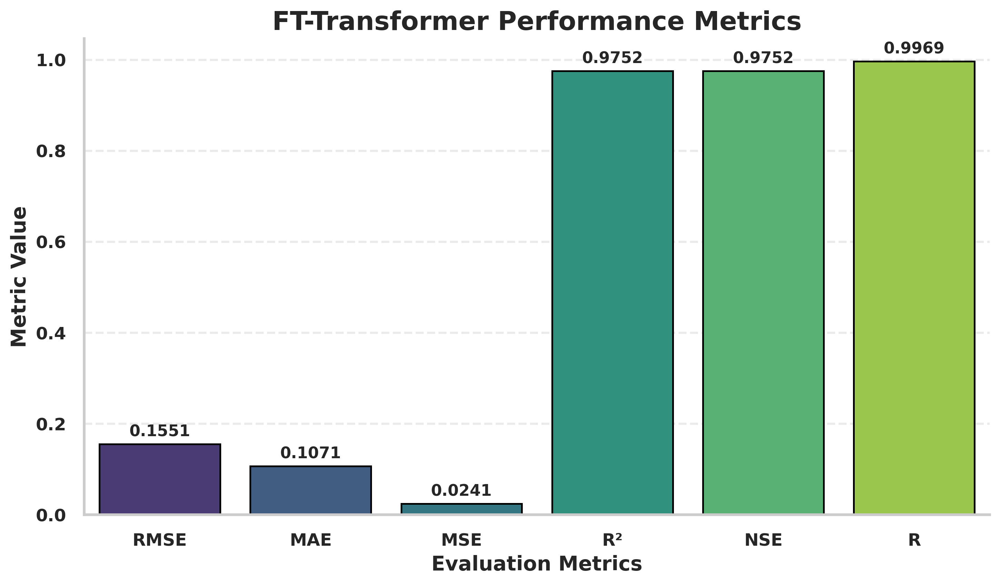

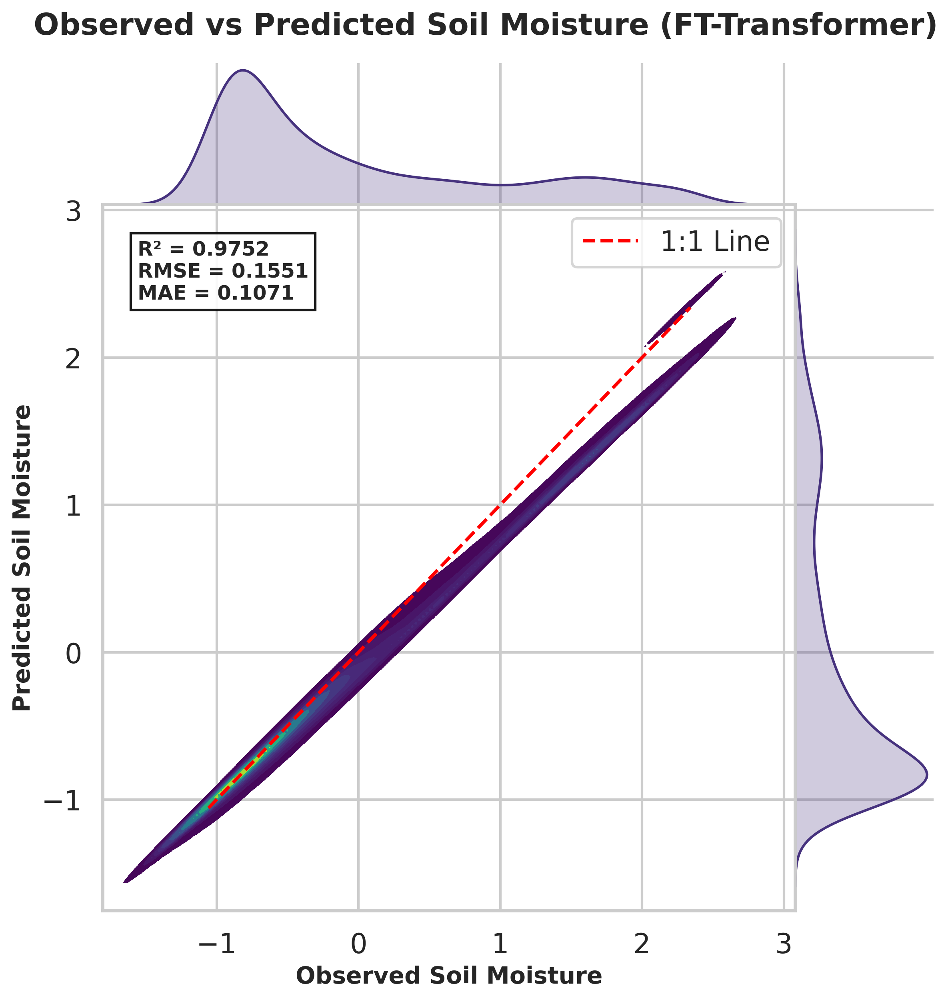

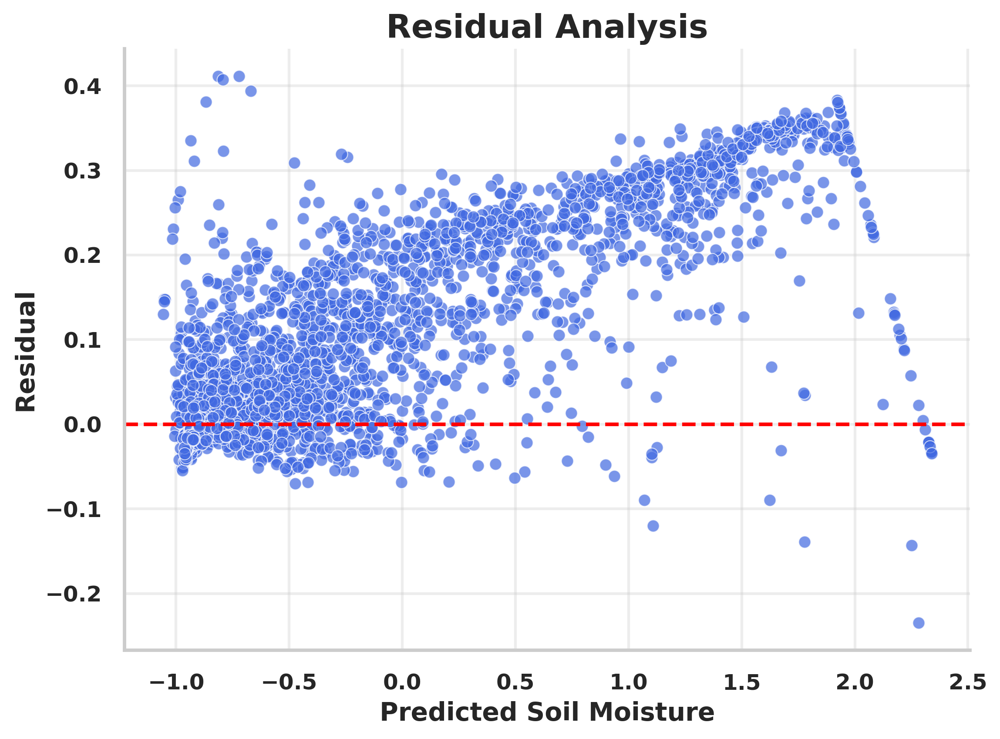

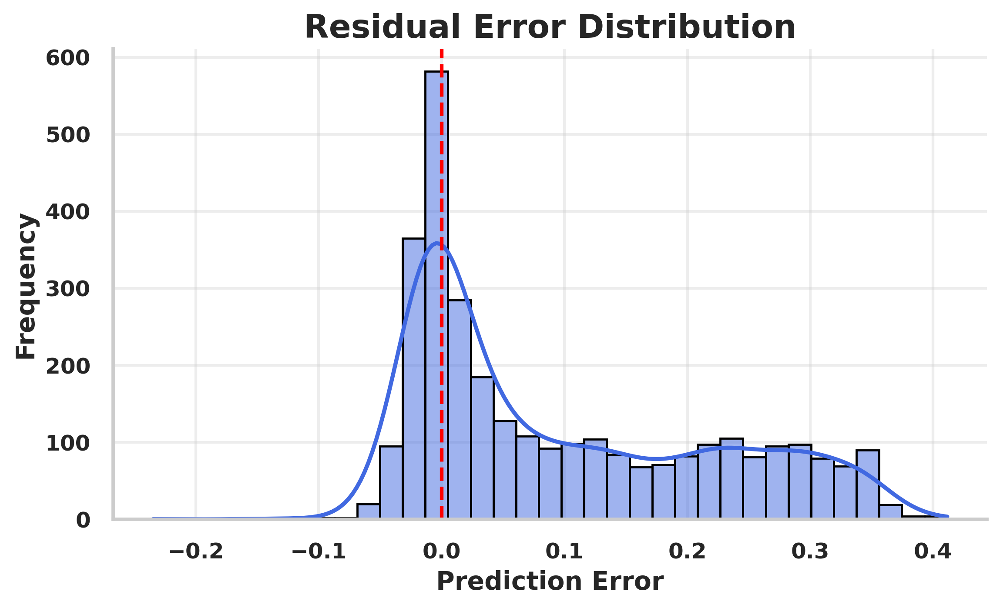



FT-TRANSFORMER PERFORMANCE
RMSE : 0.155085
MAE  : 0.107144
MSE  : 0.024051
R²   : 0.975191
NSE  : 0.975191
R    : 0.996853


In [ ]:
# ============================================================
# FT-TRANSFORMER PERFORMANCE VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Journal Style
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid",
    context="talk",
    palette="viridis"
)

plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

y_pred = pred.flatten()
y_true = y_true.flatten()

# ------------------------------------------------------------
# Metrics DataFrame
# ------------------------------------------------------------

metrics_df = pd.DataFrame({
    "Metric":["RMSE","MAE","MSE","R²","NSE","R"],
    "Value":[rmse,mae,mse,r2,nse,r]
})

print(metrics_df)

# ============================================================
# 1. PERFORMANCE METRICS
# ============================================================

plt.figure(figsize=(10,6))

ax = sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Value",
    hue="Metric",
    palette="viridis",
    legend=False,
    edgecolor="black",
    linewidth=1.2
)

# Value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        fontsize=11,
        fontweight="bold",
        padding=3
    )

plt.title(
    "FT-Transformer Performance Metrics",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Evaluation Metrics",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    "Metric Value",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(fontsize=12,fontweight="bold")
plt.yticks(fontsize=12,fontweight="bold")

plt.grid(axis="y",linestyle="--",alpha=.4)

sns.despine()

plt.tight_layout()

plt.show()

# ============================================================
# 2. OBSERVED vs PREDICTED
# ============================================================

g = sns.jointplot(
    x=y_true,
    y=y_pred,
    kind="kde",
    fill=True,
    cmap="viridis",
    height=8,
    space=0
)

xmin = min(y_true.min(),y_pred.min())
xmax = max(y_true.max(),y_pred.max())

g.ax_joint.plot(
    [xmin,xmax],
    [xmin,xmax],
    '--',
    color='red',
    linewidth=2,
    label='1:1 Line'
)

g.ax_joint.set_xlabel(
    "Observed Soil Moisture",
    fontsize=14,
    fontweight="bold"
)

g.ax_joint.set_ylabel(
    "Predicted Soil Moisture",
    fontsize=14,
    fontweight="bold"
)

g.ax_joint.legend()

text = (
    f"R² = {r2:.4f}\n"
    f"RMSE = {rmse:.4f}\n"
    f"MAE = {mae:.4f}"
)

g.ax_joint.text(
    0.05,
    0.95,
    text,
    transform=g.ax_joint.transAxes,
    fontsize=12,
    fontweight="bold",
    verticalalignment="top",
    bbox=dict(
        facecolor="white",
        edgecolor="black",
        alpha=.9
    )
)

plt.suptitle(
    "Observed vs Predicted Soil Moisture (FT-Transformer)",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.show()

# ============================================================
# 3. RESIDUAL ANALYSIS
# ============================================================

residuals = y_true-y_pred

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    s=45,
    alpha=.7,
    color="royalblue"
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel(
    "Predicted Soil Moisture",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    "Residual",
    fontsize=14,
    fontweight="bold"
)

plt.title(
    "Residual Analysis",
    fontsize=18,
    fontweight="bold"
)

plt.xticks(fontsize=12,fontweight="bold")
plt.yticks(fontsize=12,fontweight="bold")

plt.grid(alpha=.35)

sns.despine()

plt.tight_layout()

plt.show()

# ============================================================
# 4. ERROR DISTRIBUTION
# ============================================================

plt.figure(figsize=(8,5))

sns.histplot(
    residuals,
    bins=35,
    kde=True,
    color="royalblue",
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel(
    "Prediction Error",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    "Frequency",
    fontsize=14,
    fontweight="bold"
)

plt.title(
    "Residual Error Distribution",
    fontsize=18,
    fontweight="bold"
)

plt.xticks(fontsize=12,fontweight="bold")
plt.yticks(fontsize=12,fontweight="bold")

plt.grid(alpha=.35)

sns.despine()

plt.tight_layout()

plt.show()

# ============================================================
# 5. PERFORMANCE TABLE
# ============================================================

print("\n")
print("="*60)
print("FT-TRANSFORMER PERFORMANCE")
print("="*60)

print(f"RMSE : {rmse:.6f}")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"R²   : {r2:.6f}")
print(f"NSE  : {nse:.6f}")
print(f"R    : {r:.6f}")

In [ ]:
avg_pred=(

rf_pred+

xgb_pred+

pred

)/3

avg_pred
print( avg_pred )


[10.32640653  9.26943013  9.32827508 ...  5.26197848  4.35682624
  4.92836596]


In [ ]:
from sklearn.model_selection import KFold

kf=KFold(

n_splits=5,

shuffle=True,

random_state=42

)

In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset # Import necessary classes

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from xgboost import XGBRegressor

import rtdl # Import rtdl for FTTransformer model definition

# ============================================================
# GLOBAL VARIABLES (Re-defined for explicit scope)
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

# Assuming X_train, X_test, y_train, y_test are already scaled numpy arrays
# from previous steps (e.g., cell 'vJWOIob1NCG5').
# Also assuming X_train_tensor and X_test_tensor are available from previous cells
# (e.g., cell 'dlrG4pKj8Zwu') or can be recreated from current X_train/X_test.
# Given the context, X_train_tensor and X_test_tensor should be in scope.

# ============================================================
# FT TRANSFORMER PREDICTIONS
# ============================================================

print("Generating FTTransformer predictions...")

# Instantiate the FTTransformer model structure (must match saved model)
ft_model = rtdl.FTTransformer.make_baseline(
    n_num_features=X_train.shape[1], # Use X_train from current scope for feature count
    cat_cardinalities=[],
    d_token=192,
    n_blocks=4,
    attention_dropout=0.2,
    ffn_d_hidden=384,
    ffn_dropout=0.2,
    residual_dropout=0.0,
    d_out=1
)

# Load the saved model weights
ft_model.load_state_dict(
    torch.load("ft_transformer.pth")
)

# Move the model to the correct device
ft_model.to(device)

ft_model.eval()

# Define batch size for prediction (can be the same as training)
batch_size = 256

# Create DataLoader for test predictions
train_dataset_pred = TensorDataset(torch.tensor(X_train, dtype=torch.float32))
train_loader_pred = DataLoader(train_dataset_pred, batch_size=batch_size, shuffle=False)

test_dataset_pred = TensorDataset(torch.tensor(X_test, dtype=torch.float32))
test_loader_pred = DataLoader(test_dataset_pred, batch_size=batch_size, shuffle=False)

ft_train_preds_list = []
ft_test_preds_list = []

with torch.no_grad():
    # Batch prediction for training set
    for batch_X_train in train_loader_pred:
        batch_X_train = batch_X_train[0].to(device)
        batch_pred = ft_model(batch_X_train, None).cpu().numpy().flatten()
        ft_train_preds_list.append(batch_pred)
    ft_train_pred = np.concatenate(ft_train_preds_list)

    # Batch prediction for test set
    for batch_X_test in test_loader_pred:
        batch_X_test = batch_X_test[0].to(device)
        batch_pred = ft_model(batch_X_test, None).cpu().numpy().flatten()
        ft_test_preds_list.append(batch_pred)
    ft_test_pred = np.concatenate(ft_test_preds_list)

print("FTTransformer Done")

# ============================================================
# RANDOM FOREST
# ============================================================

print("Training Random Forest...")

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train.ravel()
)

rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

print("RF Done")

# ============================================================
# XGBOOST
# ============================================================

print("Training XGBoost...")

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42
)

xgb_model.fit(
    X_train,
    y_train.ravel()
)

xgb_train_pred = xgb_model.predict(X_train)
xgb_test_pred = xgb_model.predict(X_test)

print("XGBoost Done")

# ============================================================
# STACKING
# ============================================================

meta_train = np.column_stack([
    ft_train_pred,
    rf_train_pred,
    xgb_train_pred
])

meta_test = np.column_stack([
    ft_test_pred,
    rf_test_pred,
    xgb_test_pred
])

print("Meta Features Shape")
print(meta_train.shape)
print(meta_test.shape)

# ============================================================
# RIDGE META LEARNER
# ============================================================

print("Training Ridge Stacker...")

meta_model = Ridge(alpha=1)

meta_model.fit(
    meta_train,
    y_train.ravel()
)

final_pred = meta_model.predict(meta_test)

print("Stacking Done")

# ============================================================
# METRICS
# ============================================================

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_pred
    )
)

mae = mean_absolute_error(
    y_test,
    final_pred
)

mse = mean_squared_error(
    y_test,
    final_pred
)

r2 = r2_score(
    y_test,
    final_pred
)

y_true = np.asarray(y_test).reshape(-1)
y_pred = np.asarray(final_pred).reshape(-1)

nse = 1 - (
    np.sum((y_true - y_pred) ** 2)
    /
    np.sum((y_true - np.mean(y_true)) ** 2)
)

r = np.corrcoef(
    y_test.flatten(),
    final_pred.flatten()
)[0,1]

results = {

    "Model":"FTTransformer + RF + XGBoost",

    "RMSE":float(rmse),

    "MAE":float(mae),

    "MSE":float(mse),

    "R2":float(r2),

    "NSE":float(nse),

    "R":float(r)

}

print("\nRESULTS")
print("="*60)
print(results)

Generating FTTransformer predictions...
FTTransformer Done
Training Random Forest...
RF Done
Training XGBoost...
XGBoost Done
Meta Features Shape
(12460, 3)
(3115, 3)
Training Ridge Stacker...
Stacking Done

RESULTS
{'Model': 'FTTransformer + RF + XGBoost', 'RMSE': 0.05856774586868827, 'MAE': 0.03485637885203356, 'MSE': 0.003430180856139252, 'R2': 0.9964618325793959, 'NSE': 0.9964618325793959, 'R': 0.9982770712271797}


In [ ]:
# ============================================================
# MODEL COMPARISON - JOURNAL STYLE
# Figure 1: Error Metrics
# Figure 2: Performance Metrics
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")

plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300

# ============================================================
# DATA
# ============================================================

comparison_df = pd.DataFrame({

    "Model":[
        "Random Forest",
        "XGBoost",
        "FT-Transformer",
        "Hybrid"
    ],

    "RMSE":[
        rf_results["RMSE"],
        xgb_results["RMSE"],
        ft_results["RMSE"],
        results["RMSE"]
    ],

    "MAE":[
        rf_results["MAE"],
        xgb_results["MAE"],
        ft_results["MAE"],
        results["MAE"]
    ],

    "MSE":[
        rf_results["MSE"],
        xgb_results["MSE"],
        ft_results["MSE"],
        results["MSE"]
    ],

    "R²":[
        rf_results["R2"],
        xgb_results["R2"],
        ft_results["R2"],
        results["R2"]
    ],

    "NSE":[
        rf_results["NSE"],
        xgb_results["NSE"],
        ft_results["NSE"],
        results["NSE"]
    ],

    "R":[
        rf_results["R"],
        xgb_results["R"],
        ft_results["R"],
        results["R"]
    ]

})

# ============================================================
# ERROR METRICS
# ============================================================

error_df = comparison_df.melt(
    id_vars="Model",
    value_vars=["RMSE","MAE","MSE"],
    var_name="Metric",
    value_name="Value"
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=error_df,
    x="Metric",
    y="Value",
    hue="Model",
    palette="viridis",
    edgecolor="black"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        fontsize=9,
        fontweight="bold",
        padding=2
    )

plt.title(
    "Comparison of Error Metrics",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Evaluation Metrics",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    "Error Value",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(fontsize=12,fontweight="bold")
plt.yticks(fontsize=12,fontweight="bold")

plt.grid(axis="y",linestyle="--",alpha=0.4)

plt.legend(
    title="Models",
    fontsize=11,
    title_fontsize=12
)

sns.despine()

plt.tight_layout()

plt.show()

# ============================================================
# PERFORMANCE METRICS
# ============================================================

performance_df = comparison_df.melt(
    id_vars="Model",
    value_vars=["R²","NSE","R"],
    var_name="Metric",
    value_name="Value"
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=performance_df,
    x="Metric",
    y="Value",
    hue="Model",
    palette="viridis",
    edgecolor="black"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        fontsize=9,
        fontweight="bold",
        padding=2
    )

plt.title(
    "Comparison of Performance Metrics",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Evaluation Metrics",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    "Performance Value",
    fontsize=14,
    fontweight="bold"
)

plt.ylim(0.90,1.01)

plt.xticks(fontsize=12,fontweight="bold")
plt.yticks(fontsize=12,fontweight="bold")

plt.grid(axis="y",linestyle="--",alpha=0.4)

plt.legend(
    title="Models",
    fontsize=11,
    title_fontsize=12
)

sns.despine()

plt.tight_layout()

plt.show()

NameError: name 'rf_results' is not defined

In [ ]:
# ============================================================
# HYBRID MODEL - OBSERVED vs PREDICTED
# Publication Quality (No Overlap)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# ------------------------------------------------------------
# Journal Style
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid",
    context="talk"
)

plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

y_true = np.ravel(y_test)
y_pred = np.ravel(final_pred)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

r2 = r2_score(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

mae = mean_absolute_error(
    y_true,
    y_pred
)

# ============================================================
# JOINT KDE PLOT
# ============================================================

g = sns.jointplot(
    x=y_true,
    y=y_pred,
    kind="kde",
    fill=True,
    cmap="viridis",
    height=8,
    space=0,
    levels=100,
    thresh=0.03
)

# ------------------------------------------------------------
# 1:1 Reference Line
# ------------------------------------------------------------

xmin = min(
    y_true.min(),
    y_pred.min()
)

xmax = max(
    y_true.max(),
    y_pred.max()
)

g.ax_joint.plot(
    [xmin, xmax],
    [xmin, xmax],
    '--',
    color="red",
    linewidth=2.5
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

g.ax_joint.set_xlabel(
    "Observed Soil Moisture",
    fontsize=15,
    fontweight="bold"
)

g.ax_joint.set_ylabel(
    "Predicted Soil Moisture",
    fontsize=15,
    fontweight="bold"
)

g.ax_joint.tick_params(
    labelsize=12
)

# ------------------------------------------------------------
# Metrics Box
# ------------------------------------------------------------

metrics = (
    f"$R^2$ = {r2:.4f}\n"
    f"RMSE = {rmse:.4f}\n"
    f"MAE = {mae:.4f}"
)

g.ax_joint.text(
    0.04,
    0.96,
    metrics,
    transform=g.ax_joint.transAxes,
    fontsize=13,
    fontweight="bold",
    va="top",
    ha="left",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="black",
        linewidth=1.5,
        alpha=0.95
    )
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

g.figure.suptitle(
    "Hybrid Model: Observed vs Predicted",
    fontsize=22,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()

plt.show()

# ============================================================
# HYBRID MODEL
# RESIDUAL ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="talk"
)

plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300

# ------------------------------------------------------------
# Residuals
# ------------------------------------------------------------

y_true = np.ravel(y_test)
y_pred = np.ravel(final_pred)

residuals = y_true - y_pred

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(9,7))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    s=45,
    color="royalblue",
    edgecolor="black",
    alpha=0.75
)

sns.regplot(
    x=y_pred,
    y=residuals,
    scatter=False,
    lowess=True,
    color="darkred",
    line_kws={"linewidth":2}
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=2
)

plt.xlabel(
    "Predicted Soil Moisture",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel(
    "Residual (Observed - Predicted)",
    fontsize=15,
    fontweight="bold"
)

plt.title(
    "Hybrid Model Residual Analysis",
    fontsize=18,
    fontweight="bold"
)

plt.xticks(
    fontsize=12,
    fontweight="bold"
)

plt.yticks(
    fontsize=12,
    fontweight="bold"
)

plt.grid(
    linestyle="--",
    alpha=0.35
)

sns.despine()

plt.tight_layout()

plt.show()

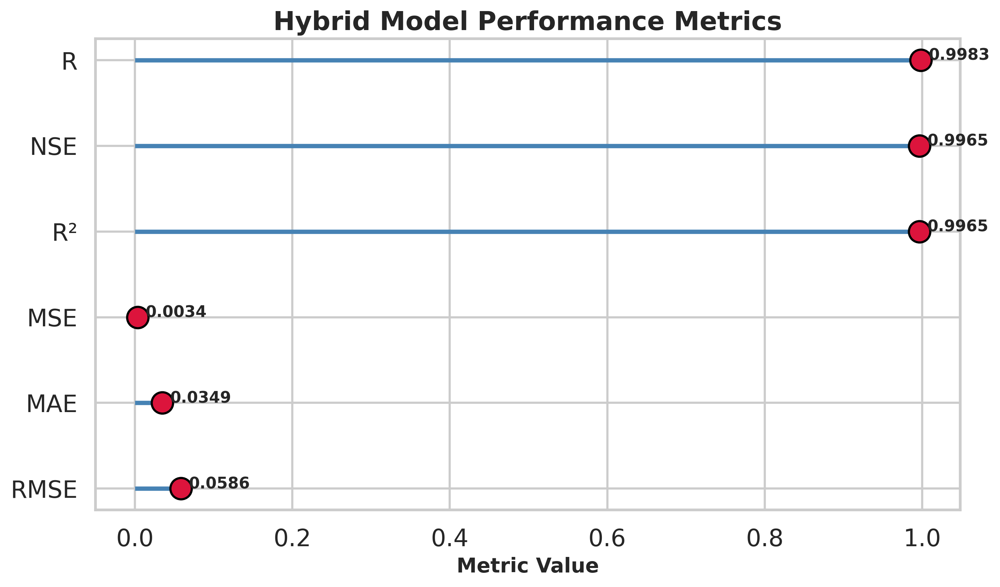

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid", context="talk")

metrics = pd.DataFrame({
    "Metric":["RMSE","MAE","MSE","R²","NSE","R"],
    "Value":[
        results["RMSE"],
        results["MAE"],
        results["MSE"],
        results["R2"],
        results["NSE"],
        results["R"]
    ]
})

plt.figure(figsize=(10,6), dpi=300)

plt.hlines(
    y=metrics["Metric"],
    xmin=0,
    xmax=metrics["Value"],
    color="steelblue",
    linewidth=3
)

plt.scatter(
    metrics["Value"],
    metrics["Metric"],
    s=220,
    color="crimson",
    edgecolor="black",
    zorder=3
)

for i,v in enumerate(metrics["Value"]):
    plt.text(
        v+0.01,
        i,
        f"{v:.4f}",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Hybrid Model Performance Metrics",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Metric Value",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    ""
)

plt.tight_layout()

plt.show()

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

metrics = pd.DataFrame({
    "RMSE":[results["RMSE"]],
    "MAE":[results["MAE"]],
    "MSE":[results["MSE"]],
    "R²":[results["R2"]],
    "NSE":[results["NSE"]],
    "R":[results["R"]]
}, index=["Hybrid"])

plt.figure(figsize=(10,2.5), dpi=300)

ax = sns.heatmap(
    metrics,
    annot=True,
    fmt=".4f",
    cmap="viridis",
    linewidths=1,
    cbar=True,
    annot_kws={"fontsize":12,"fontweight":"bold"}
)

plt.title(
    "Hybrid Model Performance Metrics",
    fontsize=16,
    fontweight="bold"
)

plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# CELL 1
# IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import (
    DataLoader,
    TensorDataset
)

import rtdl

from sklearn.model_selection import (
    train_test_split,
    KFold
)

from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestRegressor

from sklearn.linear_model import Ridge

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from xgboost import XGBRegressor

import matplotlib.pyplot as plt

import warnings

warnings.filterwarnings("ignore")

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

In [ ]:
# ============================================================
# DATA PREPROCESSING
# ============================================================

target = "SoilMoisture"

X = df.drop(
    columns=[
        target,
        "system:index",
        "Date",
        ".geo",
        "Date_for_plot",
        "LocationID",
        "District_Name"
    ]
).copy()

y = df[target].copy()

cat_cols = X.select_dtypes(include="object").columns

for col in cat_cols:

    X[col] = X[col].astype("category").cat.codes

feature_names = X.columns

scaler_x = StandardScaler()

X = scaler_x.fit_transform(X)

scaler_y = StandardScaler()

y = scaler_y.fit_transform(
    y.values.reshape(-1,1)
)

X_train,X_test,y_train,y_test = train_test_split(

    X,

    y,

    test_size=0.2,

    random_state=42

)

print(X_train.shape)

print(X_test.shape)

In [ ]:
# ============================================================
# OOF INITIALIZATION
# ============================================================

kf = KFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)

ntrain = len(X_train)

ntest = len(X_test)

oof_ft = np.zeros(ntrain)

oof_rf = np.zeros(ntrain)

oof_xgb = np.zeros(ntrain)

test_ft = np.zeros((5,ntest))

test_rf = np.zeros((5,ntest))

test_xgb = np.zeros((5,ntest))

print("OOF Ready")

In [ ]:
# ============================================================
# FT MODEL FUNCTION
# ============================================================

def build_ft():

    model = rtdl.FTTransformer.make_baseline(

        n_num_features=X_train.shape[1],

        cat_cardinalities=[],

        d_token=192,

        n_blocks=4,

        attention_dropout=0.2,

        ffn_d_hidden=384,

        ffn_dropout=0.2,

        residual_dropout=0,

        d_out=1

    )

    return model.to(device)

    # ============================================================
# FT-TRANSFORMER OOF
# ============================================================

print("="*60)
print("FT-Transformer OOF Training")
print("="*60)

epochs = 60

for fold,(train_idx,val_idx) in enumerate(kf.split(X_train)):

    print(f"\nFold {fold+1}/5")

    X_tr = torch.tensor(
        X_train[train_idx],
        dtype=torch.float32
    )

    y_tr = torch.tensor(
        y_train[train_idx],
        dtype=torch.float32
    )

    X_val = torch.tensor(
        X_train[val_idx],
        dtype=torch.float32
    )

    y_val = torch.tensor(
        y_train[val_idx],
        dtype=torch.float32
    )

    train_loader = DataLoader(

        TensorDataset(
            X_tr,
            y_tr
        ),

        batch_size=256,

        shuffle=True

    )

    model = build_ft()

    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=1e-3,

        weight_decay=1e-5

    )

    criterion = nn.MSELoss()

    model.train()

    for epoch in range(epochs):

        total_loss = 0

        for batch_x,batch_y in train_loader:

            batch_x=batch_x.to(device)

            batch_y=batch_y.to(device)

            optimizer.zero_grad()

            pred=model(
                batch_x,
                None
            )

            loss=criterion(
                pred,
                batch_y
            )

            loss.backward()

            optimizer.step()

            total_loss+=loss.item()

        if epoch%20==0:

            print(
                f"Epoch {epoch} Loss {total_loss:.5f}"
            )

    model.eval()

    with torch.no_grad():

        val_pred=model(

            X_val.to(device),

            None

        ).cpu().numpy().flatten()

        test_pred=model(

            torch.tensor(
                X_test,
                dtype=torch.float32
            ).to(device),

            None

        ).cpu().numpy().flatten()

    oof_ft[val_idx]=val_pred

    test_ft[fold]=test_pred

print("\nFT OOF Completed")



FT-Transformer OOF Training

Fold 1/5
Epoch 0 Loss 24.38917
Epoch 20 Loss 0.24224
Epoch 40 Loss 0.27363

Fold 2/5
Epoch 0 Loss 23.44734
Epoch 20 Loss 0.19513
Epoch 40 Loss 0.13571

Fold 3/5
Epoch 0 Loss 29.51632
Epoch 20 Loss 0.23513
Epoch 40 Loss 0.25216

Fold 4/5
Epoch 0 Loss 26.59414
Epoch 20 Loss 0.21655
Epoch 40 Loss 0.16898

Fold 5/5
Epoch 0 Loss 26.64659
Epoch 20 Loss 0.24037
Epoch 40 Loss 0.13467

FT OOF Completed


In [ ]:
# ============================================================
# RANDOM FOREST OOF
# ============================================================

print("="*60)
print("RF OOF")
print("="*60)

for fold,(train_idx,val_idx) in enumerate(kf.split(X_train)):

    print(f"Fold {fold+1}")

    rf=RandomForestRegressor(

        n_estimators=300,

        max_depth=15,

        random_state=42,

        n_jobs=-1

    )

    rf.fit(

        X_train[train_idx],

        y_train[train_idx].ravel()

    )

    oof_rf[val_idx]=rf.predict(

        X_train[val_idx]

    )

    test_rf[fold]=rf.predict(

        X_test

    )

print("RF Done")

RF OOF
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
RF Done


In [ ]:
# ============================================================
# XGBOOST OOF
# ============================================================

print("="*60)
print("XGBOOST OOF")
print("="*60)

for fold,(train_idx,val_idx) in enumerate(kf.split(X_train)):

    print(f"Fold {fold+1}")

    xgb=XGBRegressor(

        n_estimators=500,

        learning_rate=0.03,

        max_depth=6,

        subsample=0.8,

        colsample_bytree=0.8,

        objective="reg:squarederror",

        tree_method="hist",

        random_state=42

    )

    xgb.fit(

        X_train[train_idx],

        y_train[train_idx].ravel()

    )

    oof_xgb[val_idx]=xgb.predict(

        X_train[val_idx]

    )

    test_xgb[fold]=xgb.predict(

        X_test

    )

print("XGBoost Done")

In [ ]:
# ============================================================
# RIDGE STACKING
# ============================================================

print("="*60)
print("RIDGE STACKING")
print("="*60)

ft_test_pred = test_ft.mean(axis=0)

rf_test_pred = test_rf.mean(axis=0)

xgb_test_pred = test_xgb.mean(axis=0)

meta_train = np.column_stack([

    oof_ft,

    oof_rf,

    oof_xgb

])

meta_test = np.column_stack([

    ft_test_pred,

    rf_test_pred,

    xgb_test_pred

])

print("Meta Train :",meta_train.shape)

print("Meta Test :",meta_test.shape)

ridge = Ridge(

    alpha=1.0

)

ridge.fit(

    meta_train,

    y_train.ravel()

)

final_pred = ridge.predict(

    meta_test

)

print("Hybrid Prediction Completed")

RIDGE STACKING
Meta Train : (12460, 3)
Meta Test : (3115, 3)
Hybrid Prediction Completed


In [ ]:
# ============================================================
# PERFORMANCE
# ============================================================

y_true = y_test.flatten()

rmse = np.sqrt(

    mean_squared_error(

        y_true,

        final_pred

    )

)

mae = mean_absolute_error(

    y_true,

    final_pred

)

mse = mean_squared_error(

    y_true,

    final_pred

)

r2 = r2_score(

    y_true,

    final_pred

)

nse = 1 - (

    np.sum(

        (y_true-final_pred)**2

    )

    /

    np.sum(

        (y_true-y_true.mean())**2

    )

)

r = np.corrcoef(

    y_true,

    final_pred

)[0,1]

results = {

    "Model":"OOF Hybrid",

    "RMSE":float(rmse),

    "MAE":float(mae),

    "MSE":float(mse),

    "R2":float(r2),

    "NSE":float(nse),

    "R":float(r)

}

print()

print("="*60)

print(results)

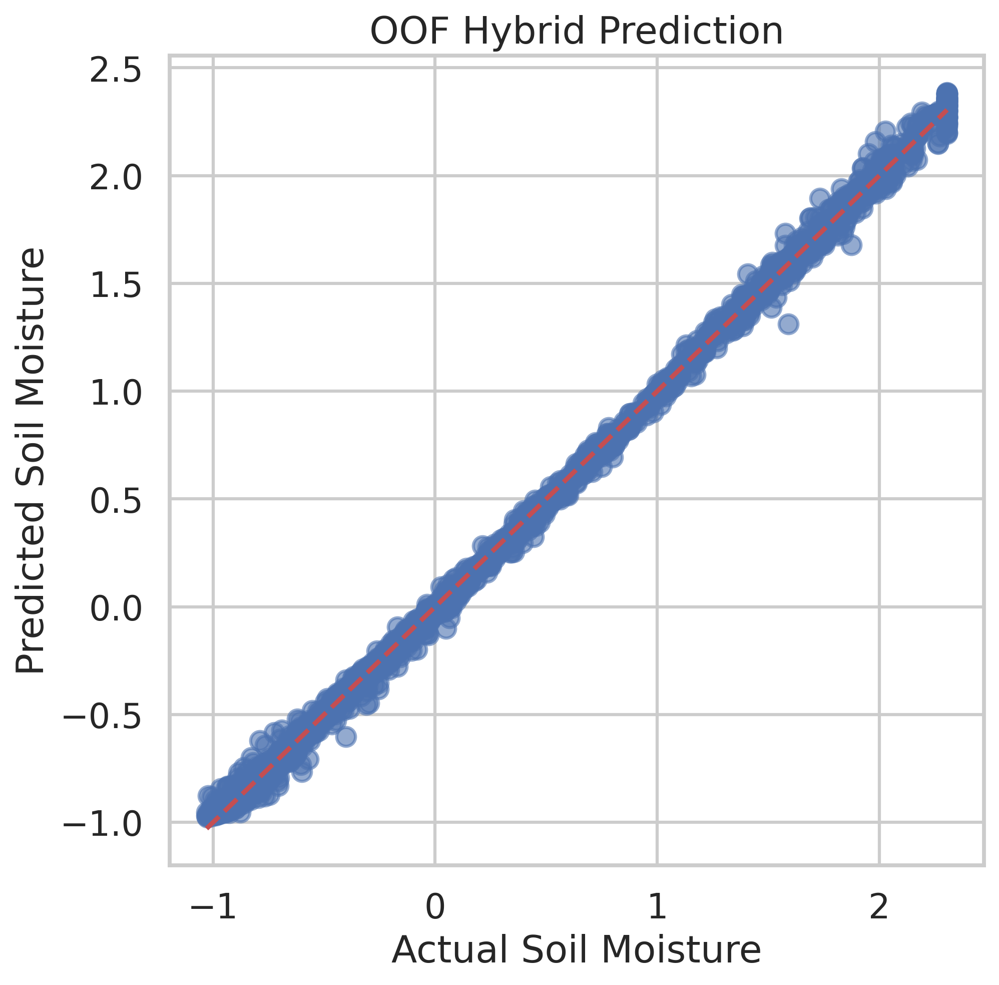

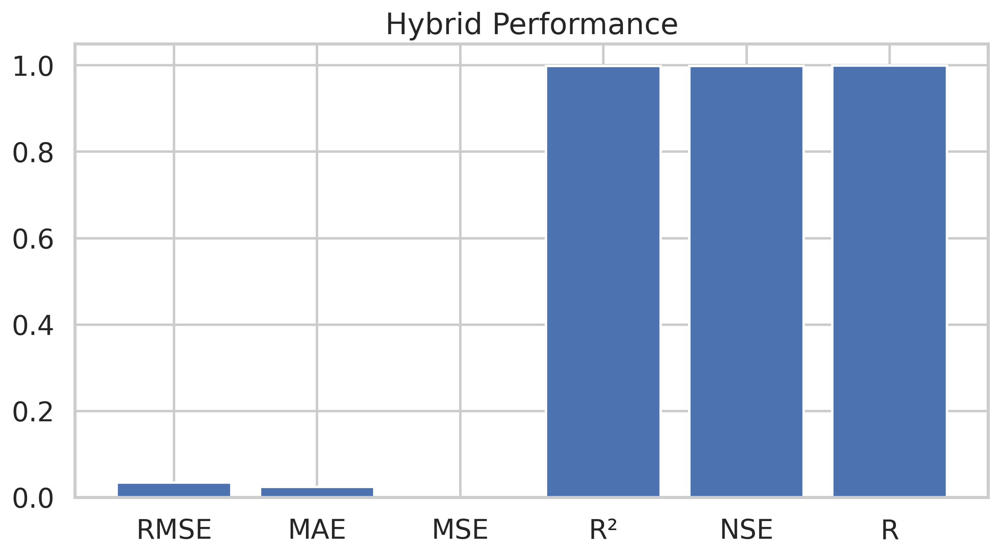

In [ ]:
# ============================================================
# VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))

plt.scatter(

    y_true,

    final_pred,

    alpha=0.6

)

plt.plot(

    [y_true.min(),y_true.max()],

    [y_true.min(),y_true.max()],

    "r--"

)

plt.xlabel("Actual Soil Moisture")

plt.ylabel("Predicted Soil Moisture")

plt.title("OOF Hybrid Prediction")

plt.grid(True)

plt.show()

metrics=[

    results["RMSE"],

    results["MAE"],

    results["MSE"],

    results["R2"],

    results["NSE"],

    results["R"]

]

labels=[

    "RMSE",

    "MAE",

    "MSE",

    "R²",

    "NSE",

    "R"

]

plt.figure(figsize=(10,5))

plt.bar(

    labels,

    metrics

)

plt.title("Hybrid Performance")

plt.show()

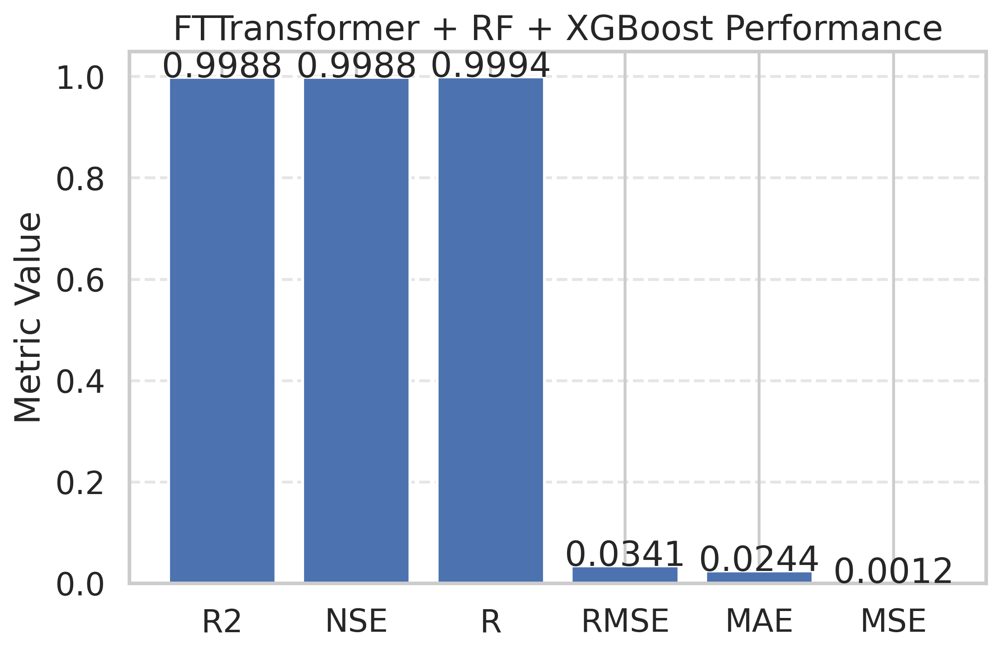

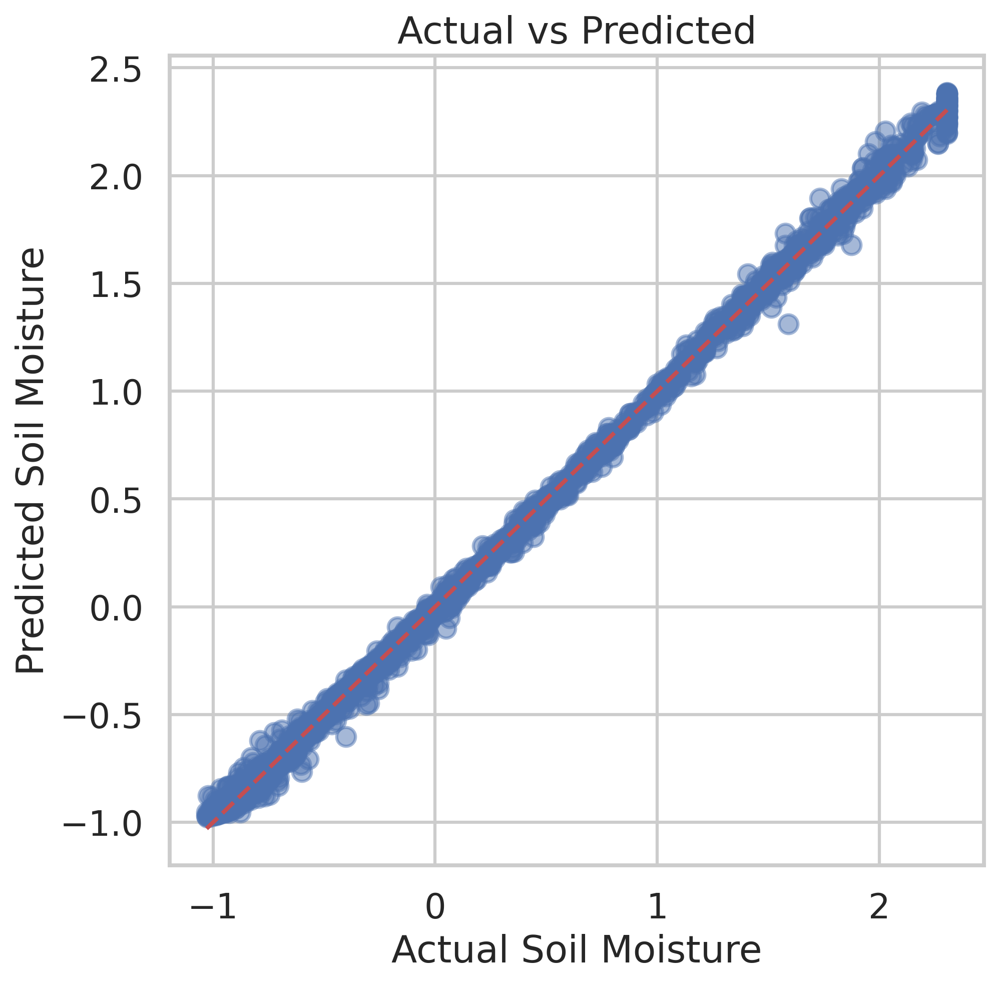

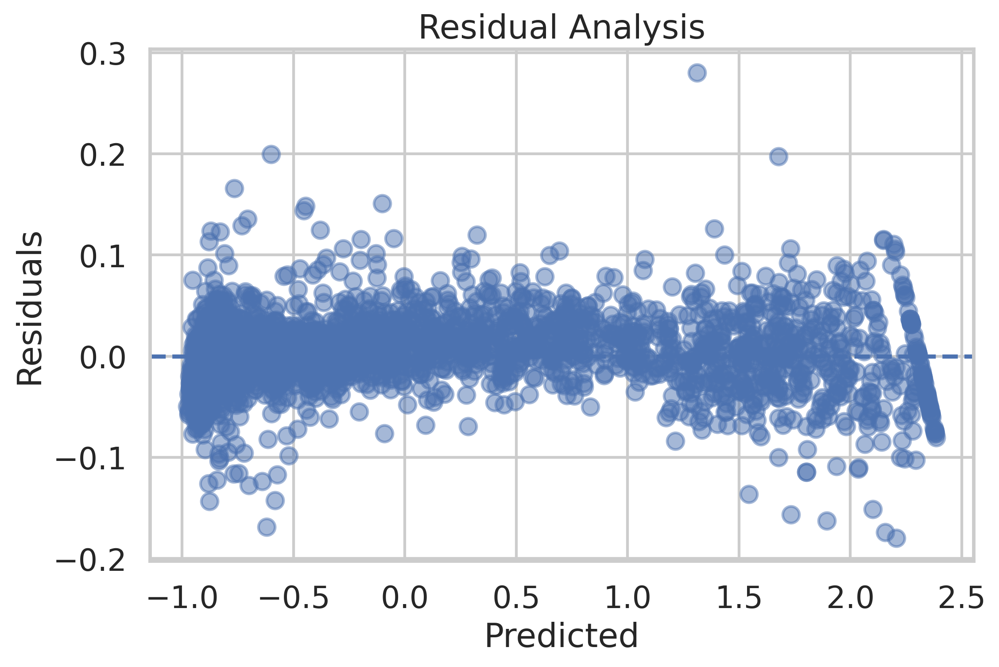

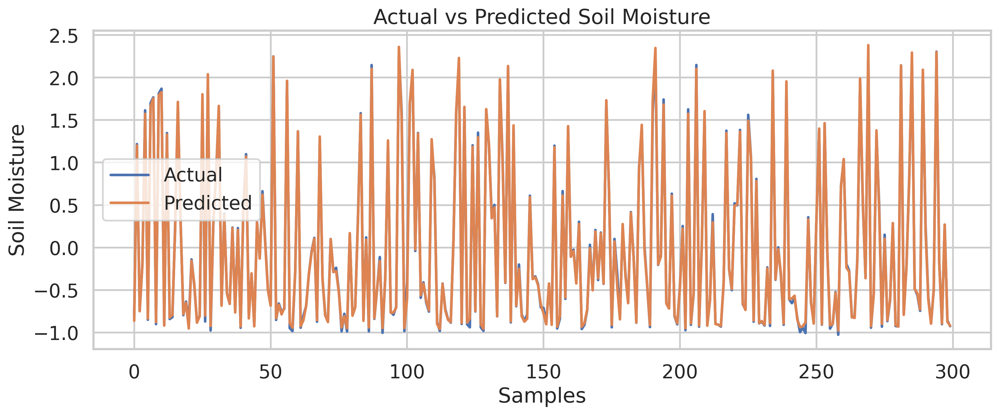

In [ ]:
import matplotlib.pyplot as plt

# Define y_test_flat
y_test_flat = y_test.flatten()

metrics = {
    "R2": r2,
    "NSE": nse,
    "R": r,
    "RMSE": rmse,
    "MAE": mae,
    "MSE": mse
}

plt.figure(figsize=(8,5))
plt.bar(metrics.keys(), metrics.values())

plt.title("FTTransformer + RF + XGBoost Performance")
plt.ylabel("Metric Value")
plt.grid(axis="y", linestyle="--", alpha=0.5)

for i,v in enumerate(metrics.values()):
    plt.text(i, v, f"{v:.4f}", ha="center")

plt.show()

import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))

plt.scatter(
    y_test_flat,
    final_pred,
    alpha=0.5
)

plt.plot(
    [y_test_flat.min(), y_test_flat.max()],
    [y_test_flat.min(), y_test_flat.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Soil Moisture")
plt.ylabel("Predicted Soil Moisture")
plt.title("Actual vs Predicted")

plt.grid(True)

plt.show()

residuals = y_test_flat - final_pred

plt.figure(figsize=(8,5))

plt.scatter(
    final_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.grid(True)

plt.show()

plt.figure(figsize=(14,5))

plt.plot(
    y_test_flat[:300],
    label="Actual"
)

plt.plot(
    final_pred[:300],
    label="Predicted"
)

plt.legend()

plt.title("Actual vs Predicted Soil Moisture")

plt.xlabel("Samples")
plt.ylabel("Soil Moisture")

plt.show()

In [ ]:
print(y_test.shape)
print(final_pred.shape)

(3115, 1)
(3115,)


In [ ]:
!pip install geopandas folium

In [ ]:
district_sm = (
    df.groupby("District")["SoilMoisture"]
    .mean()
    .reset_index()
)

district_sm.columns = [
    "District",
    "Avg_SoilMoisture"
]

print(district_sm.head())

# District Center Coordinates

district_coords = (
    df.groupby("District")
    .agg({
        "Latitude":"mean",
        "Longitude":"mean"
    })
    .reset_index()
)

district_coords.head()

# merge

district_map = pd.merge(
    district_sm,
    district_coords,
    on="District"
)

district_map.head()

   District  Avg_SoilMoisture
0         0          8.011819
1         1          7.740953
2         2         10.361314
3         3          8.152133
4         4          9.904249


,District,Avg_SoilMoisture,Latitude,Longitude
0,0,8.011819,11.218612,79.293431
1,1,7.740953,10.766908,77.144586
2,2,10.361314,11.580219,79.319058
3,3,8.152133,12.198951,78.121989
4,4,9.904249,10.435822,77.762419


In [ ]:
import folium

m = folium.Map(
    location=[11.0,78.5],
    zoom_start=7,
    tiles="CartoDB positron"
)

for _, row in district_map.iterrows():

    folium.CircleMarker(
        location=[
            row["Latitude"],
            row["Longitude"]
        ],
        radius=8,
        popup=(
            f"District: {row['District']}<br>"
            f"Soil Moisture: {row['Avg_SoilMoisture']:.2f}"
        ),
        color="blue",
        fill=True,
        fill_opacity=0.8
    ).add_to(m)

m

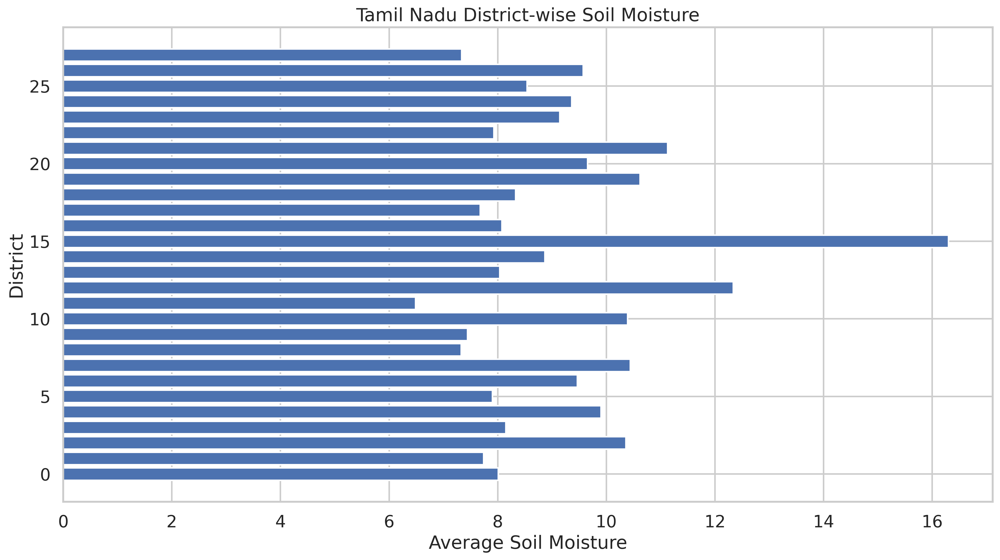

In [ ]:
import matplotlib.pyplot as plt

top = district_map.sort_values(
    "Avg_SoilMoisture",
    ascending=False
)

plt.figure(figsize=(14,8))

plt.barh(
    top["District"],
    top["Avg_SoilMoisture"]
)

plt.xlabel("Average Soil Moisture")

plt.ylabel("District")

plt.title(
    "Tamil Nadu District-wise Soil Moisture"
)

plt.tight_layout()

plt.show()

In [ ]:
from folium.plugins import HeatMap

heat_data = district_map[
    [
        "Latitude",
        "Longitude",
        "Avg_SoilMoisture"
    ]
].values.tolist()

heatmap = folium.Map(
    location=[11.0,78.5],
    zoom_start=7
)

HeatMap(
    heat_data,
    radius=20
).add_to(heatmap)

heatmap

NameError: name 'folium' is not defined

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# DISTRICT MAPPING
# ==========================================

district_map = {

    0:"Ariyalur",
    1:"Chengalpattu",
    2:"Chennai",
    3:"Coimbatore",
    4:"Cuddalore",
    5:"Dharmapuri",
    6:"Dindigul",
    7:"Erode",
    8:"Kallakurichi",
    9:"Kancheepuram",
    10:"Karur",
    11:"Krishnagiri",
    12:"Madurai",
    13:"Mayiladuthurai",
    14:"Nagapattinam",
    15:"Namakkal",
    16:"Nilgiris",
    17:"Perambalur",
    18:"Pudukkottai",
    19:"Ramanathapuram",
    20:"Ranipet",
    21:"Salem",
    22:"Sivagangai",
    23:"Tenkasi",
    24:"Thanjavur",
    25:"Theni",
    26:"Tiruchirappalli",
    27:"Tirunelveli",
    28:"Tirupathur",
    29:"Tiruppur",
    30:"Tiruvallur",
    31:"Tiruvannamalai",
    32:"Tiruvarur",
    33:"Thoothukudi",
    34:"Vellore",
    35:"Viluppuram",
    36:"Virudhunagar"

}

# ==========================================
# PREDICTION DATAFRAME
# ==========================================

pred_df = pd.DataFrame()

pred_df["District"] = (
    df.iloc[-len(final_pred):]["District"]
    .values
)

# Convert encoded values to names

pred_df["District"] = pred_df["District"].map(
    district_map
)

pred_df["Predicted_SM"] = final_pred

# ==========================================
# DISTRICT AVERAGE
# ==========================================

pred_map = (
    pred_df
    .groupby("District")["Predicted_SM"]
    .mean()
    .reset_index()
)

pred_map = pred_map.sort_values(
    "Predicted_SM",
    ascending=False
)

# ==========================================
# VISUALIZATION
# ==========================================

plt.figure(figsize=(14,10))

plt.barh(
    pred_map["District"],
    pred_map["Predicted_SM"]
)

plt.title(
    "District-wise Predicted Soil Moisture (Hybrid Model)"
)

plt.xlabel(
    "Predicted Soil Moisture"
)

plt.ylabel(
    "District"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [ ]:
import pandas as pd
import folium
from branca.element import Template, MacroElement

# =====================================================
# CHECK DISTRICT COLUMN
# =====================================================

print(df.columns)

# =====================================================
# IF DISTRICT IS ENCODED
# =====================================================

if pd.api.types.is_numeric_dtype(df["District"]):

    district_map = {

        0:"Ariyalur",
        1:"Chengalpattu",
        2:"Chennai",
        3:"Coimbatore",
        4:"Cuddalore",
        5:"Dharmapuri",
        6:"Dindigul",
        7:"Erode",
        8:"Kallakurichi",
        9:"Kancheepuram",
        10:"Karur",
        11:"Krishnagiri",
        12:"Madurai",
        13:"Mayiladuthurai",
        14:"Nagapattinam",
        15:"Namakkal",
        16:"Nilgiris",
        17:"Perambalur",
        18:"Pudukkottai",
        19:"Ramanathapuram",
        20:"Ranipet",
        21:"Salem",
        22:"Sivagangai",
        23:"Tenkasi",
        24:"Thanjavur",
        25:"Theni",
        26:"Tiruchirappalli",
        27:"Tirunelveli",
        28:"Tirupathur",
        29:"Tiruppur",
        30:"Tiruvallur",
        31:"Tiruvannamalai",
        32:"Tiruvarur",
        33:"Tuticorin",
        34:"Vellore",
        35:"Viluppuram",
        36:"Virudhunagar"
    }

    df["District_Name"] = df["District"].map(district_map)

else:

    df["District_Name"] = df["District"]

# =====================================================
# CLASSIFICATION
# =====================================================

q1 = df["SoilMoisture"].quantile(0.25)
q2 = df["SoilMoisture"].quantile(0.50)
q3 = df["SoilMoisture"].quantile(0.75)

def classify(sm):

    if sm <= q1:
        return "Dry"

    elif sm <= q2:
        return "Low"

    elif sm <= q3:
        return "Medium"

    else:
        return "High"

df["Class"] = df["SoilMoisture"].apply(classify)

# =====================================================
# COLORS
# =====================================================

colors = {

    "Dry":"red",
    "Low":"orange",
    "Medium":"green",
    "High":"blue"

}

# =====================================================
# MAP
# =====================================================

m = folium.Map(

    location=[11.1,78.6],

    zoom_start=7,

    tiles="OpenStreetMap"

)

# Better background:
#
# tiles="CartoDB Voyager"
# tiles="CartoDB Positron"

# =====================================================
# POINTS
# =====================================================

for _, row in df.iterrows():

    folium.CircleMarker(

        location=[
            row["Latitude"],
            row["Longitude"]
        ],

        radius=4,

        color=colors[row["Class"]],

        fill=True,

        fill_color=colors[row["Class"]],

        fill_opacity=0.8,

        weight=1,

        popup=f"""
        <b>District:</b> {row['District_Name']}<br>
        <b>Soil Moisture:</b> {row['SoilMoisture']:.2f}<br>
        <b>Class:</b> {row['Class']}<br>
        <b>Rainfall:</b> {row['Rainfall']:.2f}<br>
        <b>Temperature:</b> {row['Temperature']:.2f}
        """

    ).add_to(m)

# =====================================================
# LEGEND
# =====================================================

legend = """

{% macro html(this, kwargs) %}

<div style="
position: fixed;
bottom: 40px;
left: 40px;
width: 200px;
height: 170px;
background-color: white;
border:2px solid gray;
z-index:9999;
padding:10px;
font-size:14px;
">

<b>Soil Moisture Classes</b><br><br>

<span style='color:red;font-size:20px;'>■</span> Dry<br>

<span style='color:orange;font-size:20px;'>■</span> Low<br>

<span style='color:green;font-size:20px;'>■</span> Medium<br>

<span style='color:blue;font-size:20px;'>■</span> High<br>

</div>

{% endmacro %}

"""

macro = MacroElement()
macro._template = Template(legend)

m.get_root().add_child(macro)

# =====================================================
# SAVE
# =====================================================

m.save("TamilNadu_SoilMoisture_Map.html")

print("Map Created Successfully")

m

Prediction lengths
------------------
Observed       : 3115
RF             : 3115
XGBoost        : 3115
FT-Transformer : 3115
Hybrid         : 3115

Generating Figure 5...


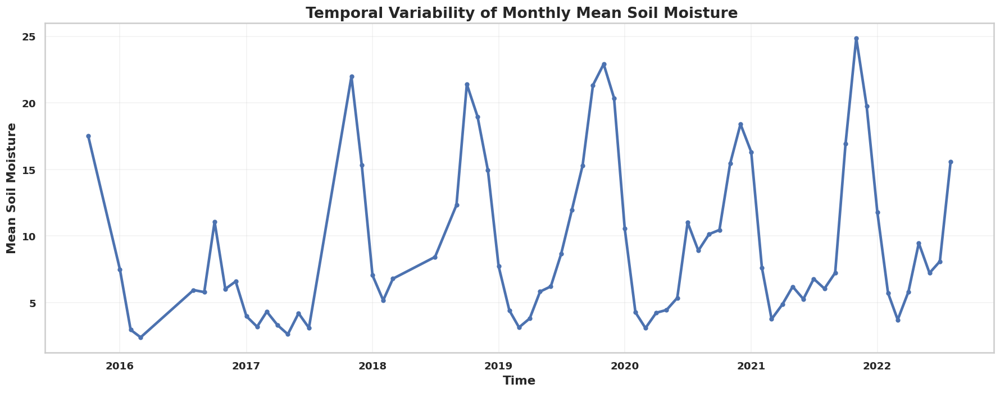


Generating Figure 6...


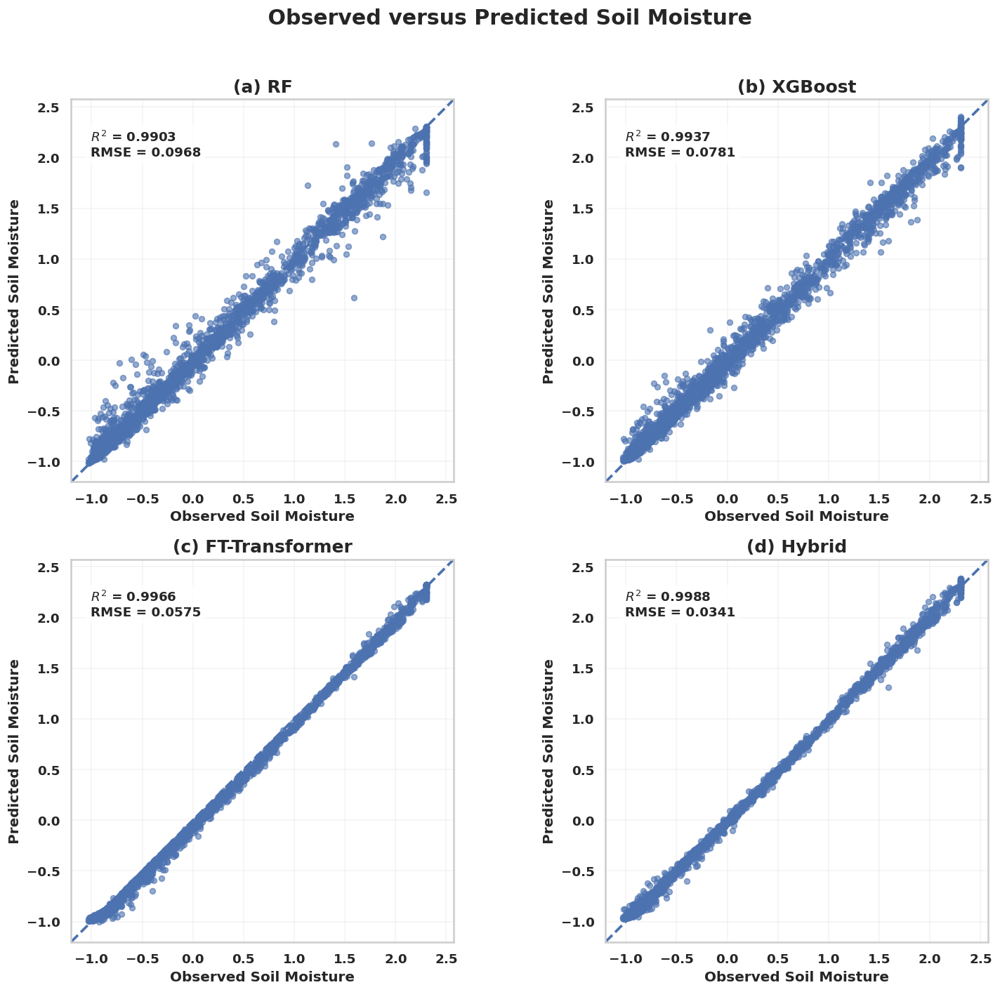


Generating Figure 7...


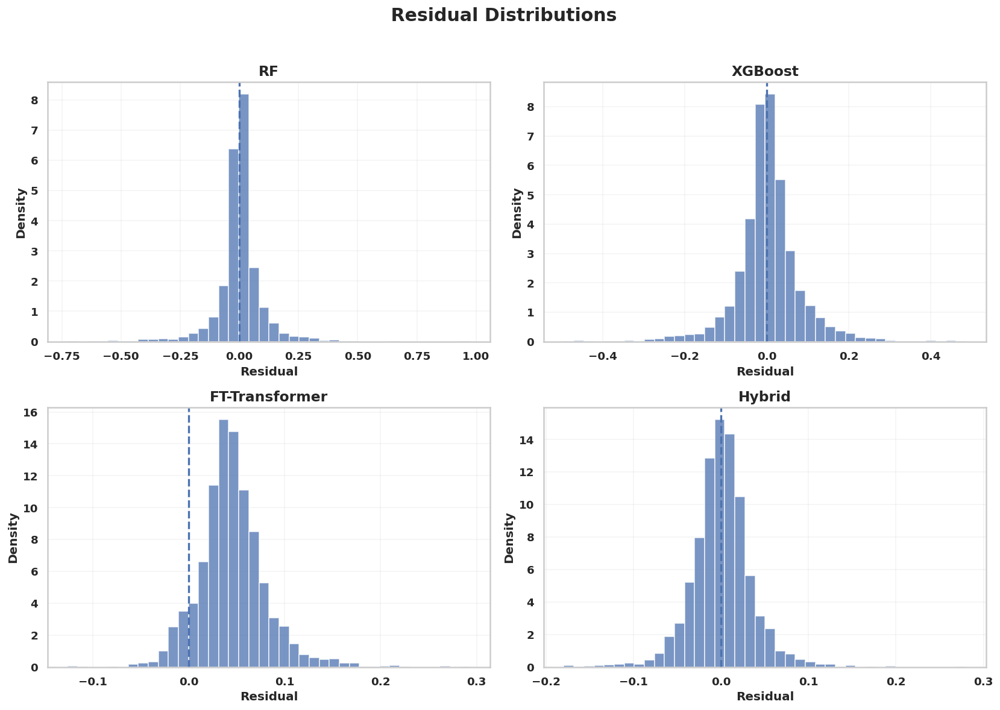


Generating Figure 8...


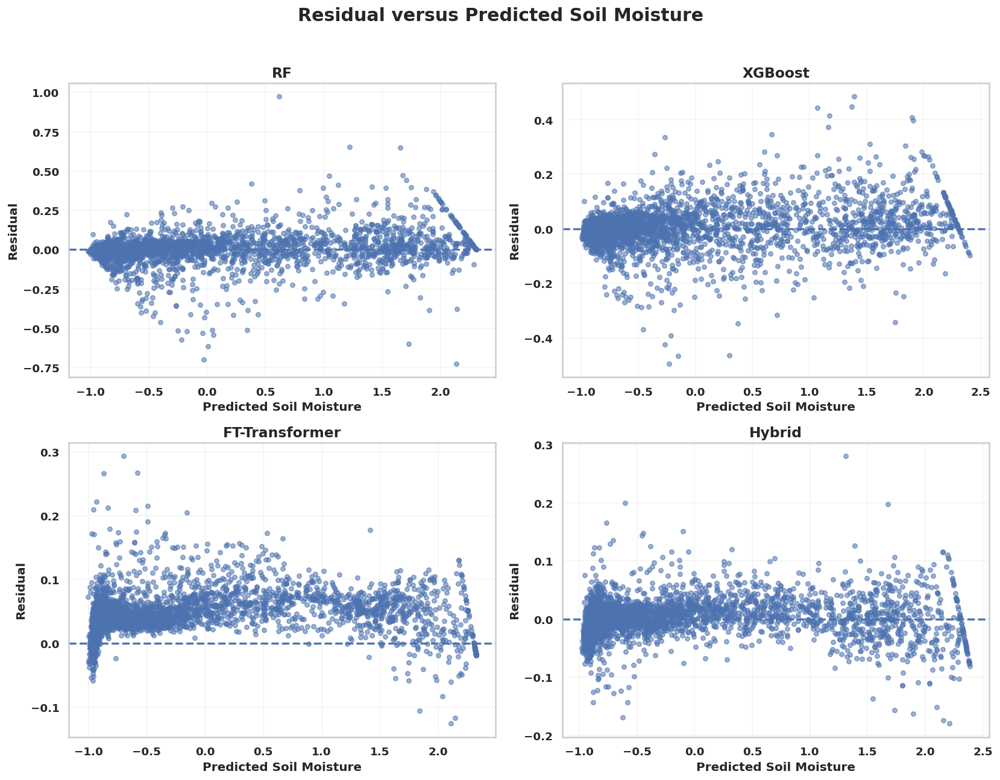


Generating Figure 9...


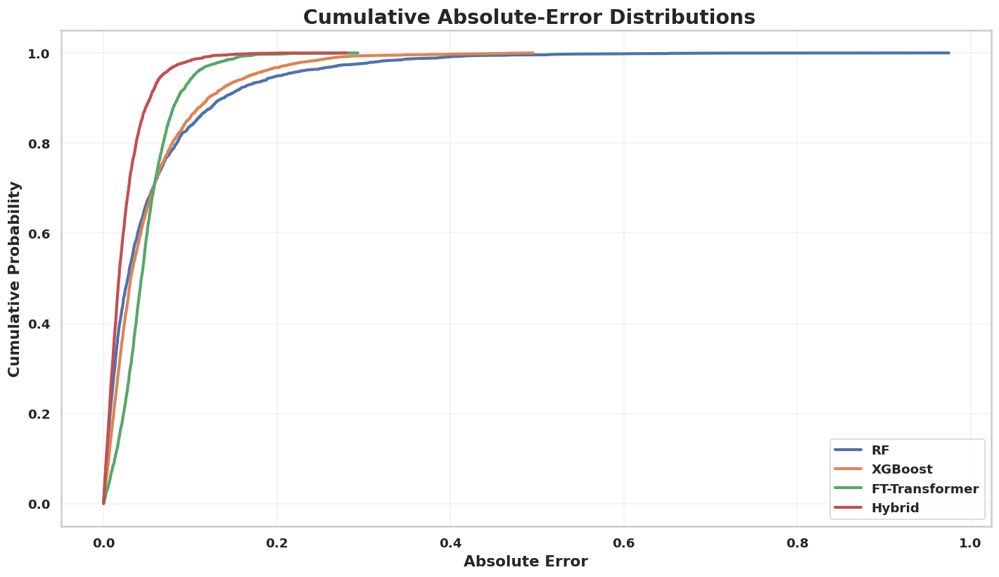


Generating Figure 10...


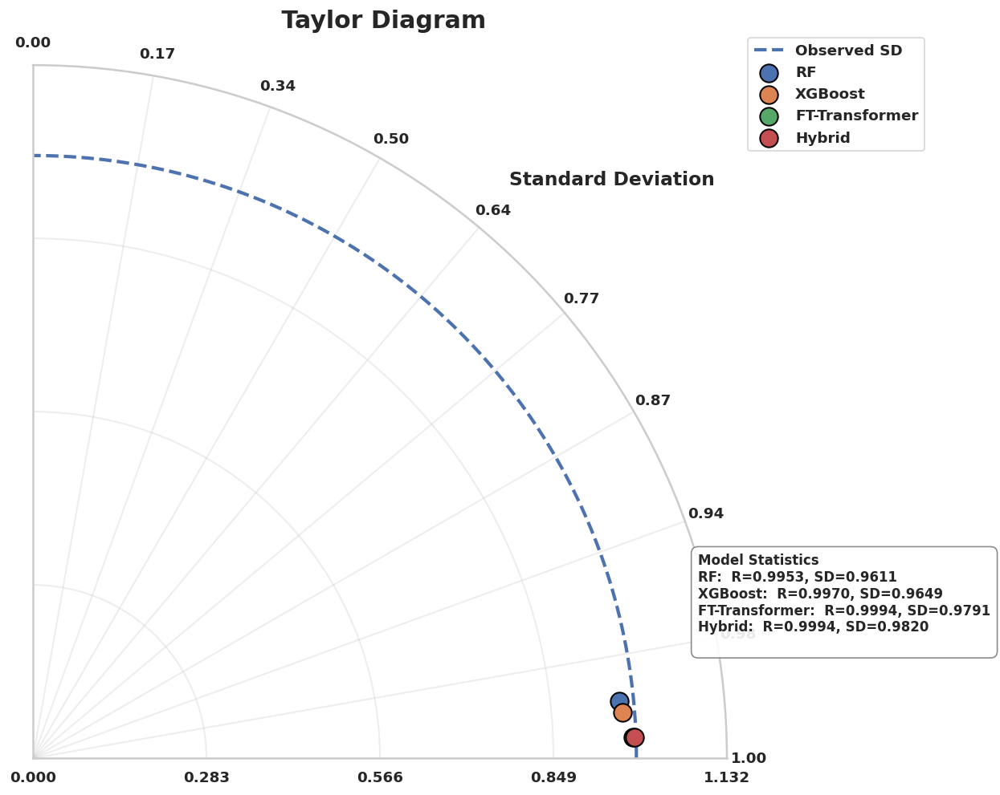


Generating Figure 11...
--------------------------------------------------
Feature count check
--------------------------------------------------
RF model features       : 46
XGBoost model features  : 46
Available feature names : 46


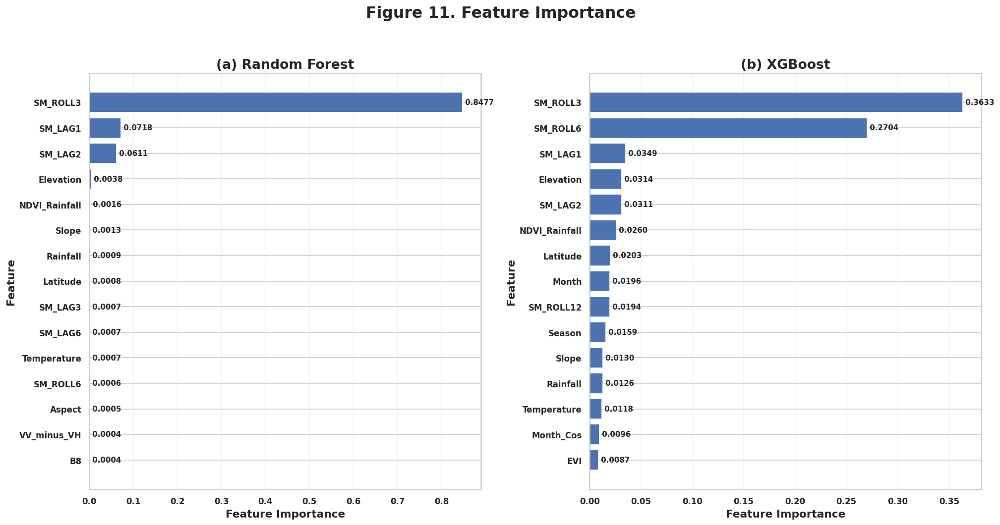



RANDOM FOREST — ALL FEATURES


,Feature,Importance
40,SM_ROLL3,0.847666
36,SM_LAG1,0.071794
37,SM_LAG2,0.061064
9,Elevation,0.003829
34,NDVI_Rainfall,0.001572
19,Slope,0.001263
16,Rainfall,0.000912
11,Latitude,0.000750
38,SM_LAG3,0.000714
39,SM_LAG6,0.000696




XGBOOST — ALL FEATURES


,Feature,Importance
40,SM_ROLL3,0.363265
41,SM_ROLL6,0.270395
36,SM_LAG1,0.034934
9,Elevation,0.031380
37,SM_LAG2,0.031097
34,NDVI_Rainfall,0.026024
11,Latitude,0.020323
13,Month,0.019603
42,SM_ROLL12,0.019408
18,Season,0.015897



Generating Figure 12...


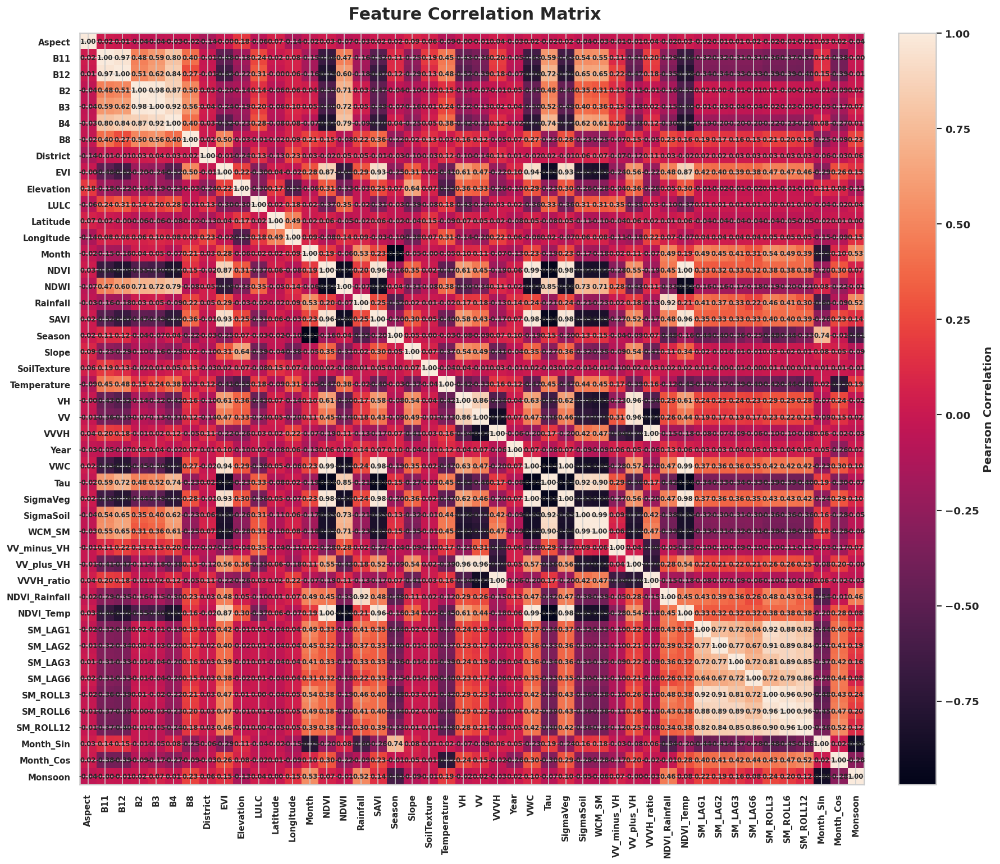


Generating Figure 13...


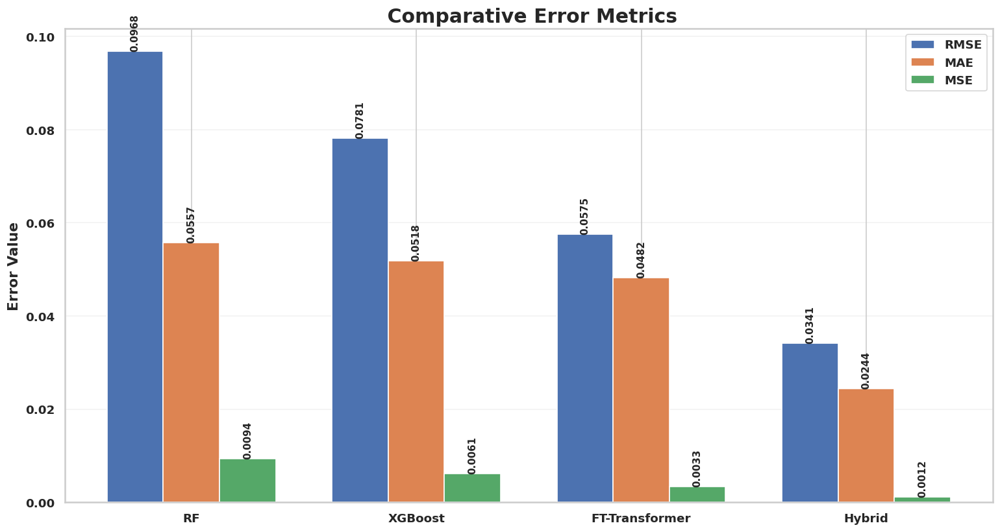


Generating Figure 14...


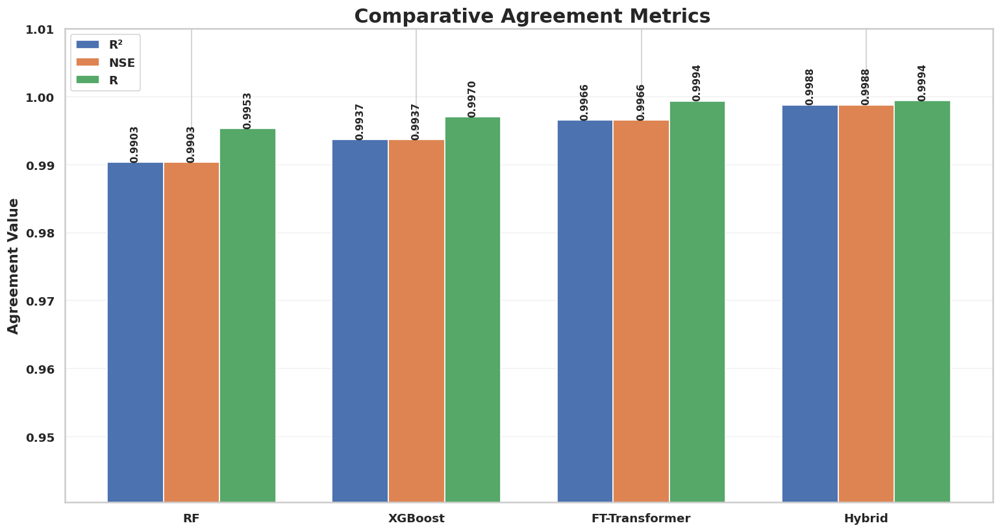


Generating Figure 15...


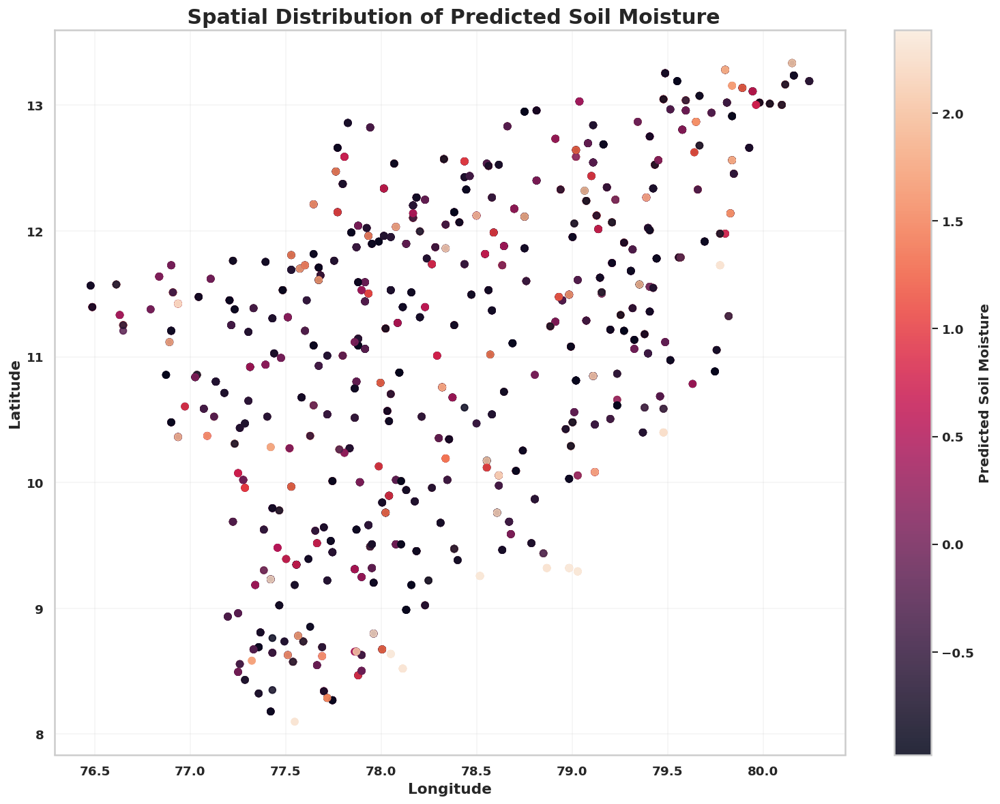



FINAL MODEL COMPARISON


,Model,RMSE,MAE,MSE,R2,NSE,R
0,RF,0.096824,0.055716,0.009375,0.990330,0.990330,0.995340
1,XGBoost,0.078097,0.051784,0.006099,0.993709,0.993709,0.997000
2,FT-Transformer,0.057523,0.048204,0.003309,0.996587,0.996587,0.999369
3,Hybrid,0.034125,0.024378,0.001164,0.998799,0.998799,0.999402



All Figures 5–15 Generated Successfully.


In [ ]:
# ============================================================
# RSE / Q1-STYLE VISUALIZATION SUITE
# FIGURES 5–15
# RF + XGBoost + FT-Transformer + OOF Hybrid
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

# ============================================================
# Re-define ft_results if not present (assuming values from previous run)
# ============================================================
ft_results = {
    'Model': 'FTTransformer',
    'RMSE': np.float64(0.14670849503254813),
    'MAE': 0.08605431765317917,
    'MSE': 0.021523382514715195,
    'R2': 0.9777990579605103,
    'NSE': np.float32(0.97779906),
    'R': np.float64(0.996802823930948)
}

# ============================================================
# GLOBAL PLOT SETTINGS
# ============================================================

plt.rcParams.update({
    "font.size": 12,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.5,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

# ============================================================
# 1. PREPARE PREDICTIONS
# ============================================================

y_true = np.asarray(y_test).reshape(-1)

rf_pred = np.asarray(rf_test_pred).reshape(-1)
xgb_pred = np.asarray(xgb_test_pred).reshape(-1)
ft_pred = np.asarray(ft_test_pred).reshape(-1)
hybrid_pred = np.asarray(final_pred).reshape(-1)

models = {
    "RF": rf_pred,
    "XGBoost": xgb_pred,
    "FT-Transformer": ft_pred,
    "Hybrid": hybrid_pred
}

# Check lengths
print("Prediction lengths")
print("------------------")
print("Observed       :", len(y_true))
print("RF             :", len(rf_pred))
print("XGBoost        :", len(xgb_pred))
print("FT-Transformer :", len(ft_pred))
print("Hybrid         :", len(hybrid_pred))

# ============================================================
# COMMON EQUAL SCALE FOR OBSERVED VS PREDICTED
# ============================================================

all_values = np.concatenate([
    y_true,
    rf_pred,
    xgb_pred,
    ft_pred,
    hybrid_pred
])

global_min = np.nanmin(all_values)
global_max = np.nanmax(all_values)

margin = 0.05 * (global_max - global_min)

plot_min = global_min - margin
plot_max = global_max + margin

# ============================================================
# FIGURE 5
# TEMPORAL VARIABILITY OF MONTHLY MEAN SOIL MOISTURE
# ============================================================

print("\nGenerating Figure 5...")

temp_df = df.copy()

temp_df["Date"] = pd.to_datetime(
    temp_df["Date"],
    errors="coerce"
)

temp_df = temp_df.dropna(
    subset=["Date", "SoilMoisture"]
)

monthly = (
    temp_df
    .groupby(temp_df["Date"].dt.to_period("M"))["SoilMoisture"]
    .mean()
    .reset_index()
)

monthly["Date"] = monthly["Date"].dt.to_timestamp()

fig, ax = plt.subplots(
    figsize=(15, 6)
)

ax.plot(
    monthly["Date"],
    monthly["SoilMoisture"],
    linewidth=2.8,
    marker="o",
    markersize=4
)

ax.set_title(
    " Temporal Variability of Monthly Mean Soil Moisture",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel(
    "Time",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Mean Soil Moisture",
    fontsize=13,
    fontweight="bold"
)

ax.grid(
    True,
    alpha=0.25
)

ax.tick_params(
    axis="both",
    labelsize=11
)

for label in ax.get_xticklabels():
    label.set_fontweight("bold")

for label in ax.get_yticklabels():
    label.set_fontweight("bold")

plt.tight_layout()

plt.savefig(
    "Figure_5_Temporal_Variability.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 6
# OBSERVED VS PREDICTED
# ============================================================

print("\nGenerating Figure 6...")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 12)
)

axes = axes.flatten()

model_names = [
    "RF",
    "XGBoost",
    "FT-Transformer",
    "Hybrid"
]

for ax, name in zip(axes, model_names):

    pred = models[name]

    ax.scatter(
        y_true,
        pred,
        s=22,
        alpha=0.60
    )

    # 1:1 line
    ax.plot(
        [plot_min, plot_max],
        [plot_min, plot_max],
        linestyle="--",
        linewidth=2.2
    )

    ax.set_xlim(
        plot_min,
        plot_max
    )

    ax.set_ylim(
        plot_min,
        plot_max
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    r2 = r2_score(
        y_true,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            pred
        )
    )

    ax.set_title(
        f"({chr(97 + model_names.index(name))}) {name}",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Observed Soil Moisture",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Predicted Soil Moisture",
        fontsize=12,
        fontweight="bold"
    )

    ax.text(
        0.05,
        0.92,
        f"$R^2$ = {r2:.4f}\nRMSE = {rmse:.4f}",
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        verticalalignment="top",
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.8
        )
    )

    ax.grid(
        True,
        alpha=0.20
    )

fig.suptitle(
    " Observed versus Predicted Soil Moisture",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    "Observed_vs_Predicted.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 7
# RESIDUAL DISTRIBUTIONS
# ============================================================

print("\nGenerating Figure 7...")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

axes = axes.flatten()

for ax, name in zip(
    axes,
    model_names
):

    residual = (
        y_true -
        models[name]
    )

    ax.hist(
        residual,
        bins=40,
        density=True,
        alpha=0.75
    )

    ax.axvline(
        0,
        linestyle="--",
        linewidth=2
    )

    ax.set_title(
        name,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Residual",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Density",
        fontsize=12,
        fontweight="bold"
    )

    ax.grid(
        True,
        alpha=0.20
    )

fig.suptitle(
    " Residual Distributions",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    "Residual_Distributions.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 8
# RESIDUAL VS PREDICTED
# ============================================================

print("\nGenerating Figure 8...")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 11)
)

axes = axes.flatten()

for ax, name in zip(
    axes,
    model_names
):

    pred = models[name]

    residual = (
        y_true -
        pred
    )

    ax.scatter(
        pred,
        residual,
        s=20,
        alpha=0.55
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=2
    )

    ax.set_title(
        name,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Predicted Soil Moisture",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Residual",
        fontsize=12,
        fontweight="bold"
    )

    ax.grid(
        True,
        alpha=0.20
    )

fig.suptitle(
    "Residual versus Predicted Soil Moisture",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    "Residual_vs_Predicted.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 9
# CUMULATIVE ABSOLUTE ERROR DISTRIBUTIONS
# ============================================================

print("\nGenerating Figure 9...")

fig, ax = plt.subplots(
    figsize=(12, 7)
)

for name in model_names:

    errors = np.abs(
        y_true -
        models[name]
    )

    sorted_errors = np.sort(
        errors
    )

    cumulative = (
        np.arange(
            1,
            len(sorted_errors) + 1
        )
        /
        len(sorted_errors)
    )

    ax.plot(
        sorted_errors,
        cumulative,
        linewidth=2.5,
        label=name
    )

ax.set_xlabel(
    "Absolute Error",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Cumulative Probability",
    fontsize=13,
    fontweight="bold"
)

ax.set_title(
    " Cumulative Absolute-Error Distributions",
    fontsize=17,
    fontweight="bold"
)

ax.legend(
    fontsize=11
)

ax.grid(
    True,
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "Cumulative_Error.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 10 — CLEAN TAYLOR DIAGRAM
# ============================================================

print("\nGenerating Figure 10...")

def correlation(observed, predicted):
    return np.corrcoef(observed, predicted)[0, 1]


# ------------------------------------------------------------
# CALCULATE STATISTICS
# ------------------------------------------------------------

std_obs = np.std(y_true)

taylor_stats = {}

for name in model_names:

    pred = models[name]

    corr = correlation(
        y_true,
        pred
    )

    std_pred = np.std(pred)

    taylor_stats[name] = {
        "corr": corr,
        "std": std_pred
    }


# ------------------------------------------------------------
# DETERMINE CLEAN RADIAL LIMIT
# ------------------------------------------------------------

all_std = [
    std_obs
]

for name in model_names:
    all_std.append(
        taylor_stats[name]["std"]
    )

max_std = max(all_std)

# Small margin
radial_max = max_std * 1.15


# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(11, 9)
)

ax = fig.add_subplot(
    111,
    polar=True
)


# ------------------------------------------------------------
# OBSERVED STANDARD DEVIATION
# ------------------------------------------------------------

theta_ref = np.linspace(
    0,
    np.pi / 2,
    400
)

ax.plot(
    theta_ref,
    np.ones_like(theta_ref) * std_obs,
    linestyle="--",
    linewidth=2.5,
    label="Observed SD"
)


# ------------------------------------------------------------
# MODEL POINTS
# ------------------------------------------------------------

for name in model_names:

    corr = taylor_stats[name]["corr"]

    std_pred = taylor_stats[name]["std"]

    corr = np.clip(
        corr,
        0,
        1
    )

    theta = np.arccos(
        corr
    )

    ax.scatter(
        theta,
        std_pred,
        s=180,
        edgecolor="black",
        linewidth=1.2,
        label=name,
        zorder=5
    )


# ------------------------------------------------------------
# AXIS CONFIGURATION
# ------------------------------------------------------------

ax.set_thetamin(
    0
)

ax.set_thetamax(
    90
)

ax.set_theta_zero_location(
    "E"
)

ax.set_theta_direction(
    1
)

ax.set_rlim(
    0,
    radial_max
)


# ------------------------------------------------------------
# ANGLE LABELS
# ------------------------------------------------------------

ax.set_thetagrids(
    [
        0,
        10,
        20,
        30,
        40,
        50,
        60,
        70,
        80,
        90
    ],
    labels=[
        "1.00",
        "0.98",
        "0.94",
        "0.87",
        "0.77",
        "0.64",
        "0.50",
        "0.34",
        "0.17",
        "0.00"
    ],
    fontsize=11,
    fontweight="bold"
)


# ------------------------------------------------------------
# RADIAL TICKS
# ------------------------------------------------------------

radial_ticks = np.linspace(
    0,
    radial_max,
    5
)

ax.set_rticks(
    radial_ticks
)

ax.set_rlabel_position(
    105
)

for label in ax.get_yticklabels():

    label.set_fontsize(10)
    label.set_fontweight("bold")


# ------------------------------------------------------------
# GRID
# ------------------------------------------------------------

ax.grid(
    True,
    linewidth=1.2,
    alpha=0.35
)


# ------------------------------------------------------------
# AXIS LABEL
# ------------------------------------------------------------

ax.text(
    np.deg2rad(45),
    radial_max * 1.18,
    "Standard Deviation",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold"
)


# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    " Taylor Diagram",
    fontsize=18,
    fontweight="bold",
    pad=28
)


# ------------------------------------------------------------
# LEGEND
# ------------------------------------------------------------

legend = ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1.05),
    frameon=True,
    fontsize=11
)

for text in legend.get_texts():
    text.set_fontweight("bold")


# ------------------------------------------------------------
# DISPLAY MODEL STATISTICS
# ------------------------------------------------------------

# Place compact statistics on the right side
stats_text = "Model Statistics\n"

for name in model_names:

    corr = taylor_stats[name]["corr"]
    std_pred = taylor_stats[name]["std"]

    stats_text += (
        f"{name}:  "
        f"R={corr:.4f}, "
        f"SD={std_pred:.4f}\n"
    )

fig.text(
    0.72,
    0.28,
    stats_text,
    fontsize=10,
    fontweight="bold",
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)


# ------------------------------------------------------------
# LAYOUT
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.06,
    right=0.78,
    top=0.90,
    bottom=0.10
)


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

plt.savefig(
    "Figure_10_Taylor_Diagram_Clean.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
# ============================================================
# FIGURE 11
# FEATURE IMPORTANCE — RF + XGBOOST
# FIXED VERSION
# ============================================================

print("\nGenerating Figure 11...")

# ------------------------------------------------------------
# GET EXACT FEATURE NAMES USED FOR MODEL TRAINING
# ------------------------------------------------------------

# Your original feature dataframe before scaling
# contains the exact columns used by the models.

if hasattr(X, "columns"):

    feature_names_current = list(X.columns)

else:

    # Fallback: reconstruct from original dataframe
    excluded_columns = [
        target,
        "system:index",
        "Date",
        ".geo",
        "Date_for_plot",
        "LocationID",
        "District_Name"
    ]

    feature_names_current = [
        col
        for col in df.columns
        if col not in excluded_columns
    ]


# ------------------------------------------------------------
# CHECK FEATURE COUNT
# ------------------------------------------------------------

rf_feature_count = rf_model.n_features_in_

xgb_feature_count = (
    xgb_model.n_features_in_
    if hasattr(xgb_model, "n_features_in_")
    else len(xgb_model.feature_importances_)
)

print("--------------------------------------------------")
print("Feature count check")
print("--------------------------------------------------")

print(
    "RF model features       :",
    rf_feature_count
)

print(
    "XGBoost model features  :",
    xgb_feature_count
)

print(
    "Available feature names :",
    len(feature_names_current)
)

# ------------------------------------------------------------
# MAKE SURE THE COUNTS MATCH
# ------------------------------------------------------------

if len(feature_names_current) != rf_feature_count:

    print("\nWARNING: Feature name count does not match RF.")

    print(
        "Using first",
        rf_feature_count,
        "features."
    )

    feature_names_rf = feature_names_current[
        :rf_feature_count
    ]

else:

    feature_names_rf = feature_names_current.copy()


if len(feature_names_current) != xgb_feature_count:

    print(
        "WARNING: Feature name count does not match XGBoost."
    )

    print(
        "Using first",
        xgb_feature_count,
        "features."
    )

    feature_names_xgb = feature_names_current[
        :xgb_feature_count
    ]

else:

    feature_names_xgb = feature_names_current.copy()


# ------------------------------------------------------------
# RANDOM FOREST IMPORTANCE
# ------------------------------------------------------------

rf_values = np.asarray(
    rf_model.feature_importances_
).reshape(-1)


rf_importance = pd.DataFrame({

    "Feature": feature_names_rf,

    "Importance": rf_values

})


# ------------------------------------------------------------
# XGBOOST IMPORTANCE
# ------------------------------------------------------------

xgb_values = np.asarray(
    xgb_model.feature_importances_
).reshape(-1)


xgb_importance = pd.DataFrame({

    "Feature": feature_names_xgb,

    "Importance": xgb_values

})


# ------------------------------------------------------------
# TOP FEATURES
# ------------------------------------------------------------

TOP_N = min(
    15,
    len(rf_importance),
    len(xgb_importance)
)


top_rf = (
    rf_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .head(TOP_N)
    .sort_values(
        "Importance",
        ascending=True
    )
)


top_xgb = (
    xgb_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .head(TOP_N)
    .sort_values(
        "Importance",
        ascending=True
    )
)


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 9)
)


# ============================================================
# RANDOM FOREST
# ============================================================

axes[0].barh(
    top_rf["Feature"],
    top_rf["Importance"]
)

axes[0].set_title(
    "(a) Random Forest",
    fontsize=16,
    fontweight="bold"
)

axes[0].set_xlabel(
    "Feature Importance",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Feature",
    fontsize=13,
    fontweight="bold"
)

axes[0].tick_params(
    axis="both",
    labelsize=10
)

for label in axes[0].get_yticklabels():

    label.set_fontweight("bold")


# ------------------------------------------------------------
# ADD VALUES TO RF BARS
# ------------------------------------------------------------

for i, value in enumerate(
    top_rf["Importance"]
):

    axes[0].text(
        value,
        i,
        f" {value:.4f}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )


# ============================================================
# XGBOOST
# ============================================================

axes[1].barh(
    top_xgb["Feature"],
    top_xgb["Importance"]
)

axes[1].set_title(
    "(b) XGBoost",
    fontsize=16,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Feature Importance",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Feature",
    fontsize=13,
    fontweight="bold"
)

axes[1].tick_params(
    axis="both",
    labelsize=10
)

for label in axes[1].get_yticklabels():

    label.set_fontweight("bold")


# ------------------------------------------------------------
# ADD VALUES TO XGBOOST BARS
# ------------------------------------------------------------

for i, value in enumerate(
    top_xgb["Importance"]
):

    axes[1].text(
        value,
        i,
        f" {value:.4f}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )


# ============================================================
# MAIN TITLE
# ============================================================

fig.suptitle(
    "Figure 11. Feature Importance",
    fontsize=19,
    fontweight="bold"
)


# ============================================================
# GRID
# ============================================================

for ax in axes:

    ax.grid(
        axis="x",
        alpha=0.25
    )


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.95
    ]
)


# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "Figure_11_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# PRINT FULL FEATURE IMPORTANCE TABLES
# ============================================================

print("\n")
print("=" * 70)
print("RANDOM FOREST — ALL FEATURES")
print("=" * 70)

display(
    rf_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .round(6)
)


print("\n")
print("=" * 70)
print("XGBOOST — ALL FEATURES")
print("=" * 70)

display(
    xgb_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .round(6)
)


# ============================================================
# FIGURE 12
# FEATURE CORRELATION MATRIX
# ============================================================

print("\nGenerating Figure 12...")

# Reconstruct dataframe from original feature data
corr_df = df.copy()

# Use the same feature list
available_features = [
    col for col in feature_names
    if col in corr_df.columns
]

corr_matrix = (
    corr_df[available_features]
    .select_dtypes(include=np.number)
    .corr()
)

fig, ax = plt.subplots(
    figsize=(15, 13)
)

im = ax.imshow(
    corr_matrix,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(
        len(corr_matrix.columns)
    )
)

ax.set_yticks(
    np.arange(
        len(corr_matrix.columns)
    )
)

ax.set_xticklabels(
    corr_matrix.columns,
    rotation=90,
    fontsize=9,
    fontweight="bold"
)

ax.set_yticklabels(
    corr_matrix.columns,
    fontsize=9,
    fontweight="bold"
)

# Add values
for i in range(
    len(corr_matrix.columns)
):

    for j in range(
        len(corr_matrix.columns)
    ):

        value = corr_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=7,
            fontweight="bold"
        )

ax.set_title(
    " Feature Correlation Matrix",
    fontsize=18,
    fontweight="bold",
    pad=15
)

cbar = plt.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Pearson Correlation",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Figure_12_Feature_Correlation_Matrix.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 13
# COMPARATIVE ERROR METRICS
# RMSE / MAE / MSE
# ============================================================

print("\nGenerating Figure 13...")

metric_data = []

for name in model_names:

    pred = models[name]

    metric_data.append({

        "Model": name,

        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                pred
            )
        ),

        "MAE": mean_absolute_error(
            y_true,
            pred
        ),

        "MSE": mean_squared_error(
            y_true,
            pred
        )

    })

metrics_df = pd.DataFrame(
    metric_data
)

x = np.arange(
    len(model_names)
)

width = 0.25

fig, ax = plt.subplots(
    figsize=(13, 7)
)

bars1 = ax.bar(
    x - width,
    metrics_df["RMSE"],
    width,
    label="RMSE"
)

bars2 = ax.bar(
    x,
    metrics_df["MAE"],
    width,
    label="MAE"
)

bars3 = ax.bar(
    x + width,
    metrics_df["MSE"],
    width,
    label="MSE"
)

ax.set_xticks(x)

ax.set_xticklabels(
    model_names,
    fontweight="bold"
)

ax.set_ylabel(
    "Error Value",
    fontsize=13,
    fontweight="bold"
)

ax.set_title(
    " Comparative Error Metrics",
    fontsize=18,
    fontweight="bold"
)

ax.legend(
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.25
)

# Bold metric values
for bars in [
    bars1,
    bars2,
    bars3
]:

    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{height:.4f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            rotation=90
        )

plt.tight_layout()

plt.savefig(
    "Figure_13_Comparative_Error_Metrics.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 14
# COMPARATIVE AGREEMENT METRICS
# R2 / NSE / R
# ============================================================

print("\nGenerating Figure 14...")

agreement_data = []

for name in model_names:

    pred = models[name]

    r2_value = r2_score(
        y_true,
        pred
    )

    nse_value = 1 - (

        np.sum(
            (y_true - pred) ** 2
        )

        /

        np.sum(
            (y_true - np.mean(y_true)) ** 2
        )

    )

    r_value = np.corrcoef(
        y_true,
        pred
    )[0, 1]

    agreement_data.append({

        "Model": name,

        "R²": r2_value,

        "NSE": nse_value,

        "R": r_value

    })

agreement_df = pd.DataFrame(
    agreement_data
)

x = np.arange(
    len(model_names)
)

width = 0.25

fig, ax = plt.subplots(
    figsize=(13, 7)
)

bars1 = ax.bar(
    x - width,
    agreement_df["R²"],
    width,
    label="R²"
)

bars2 = ax.bar(
    x,
    agreement_df["NSE"],
    width,
    label="NSE"
)

bars3 = ax.bar(
    x + width,
    agreement_df["R"],
    width,
    label="R"
)

ax.set_xticks(x)

ax.set_xticklabels(
    model_names,
    fontweight="bold"
)

ax.set_ylabel(
    "Agreement Value",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylim(
    max(0, agreement_df[["R²","NSE","R"]].min().min() - 0.05),
    1.01
)

ax.set_title(
    " Comparative Agreement Metrics",
    fontsize=18,
    fontweight="bold"
)

ax.legend(
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.25
)

for bars in [
    bars1,
    bars2,
    bars3
]:

    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{height:.4f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            rotation=90
        )

plt.tight_layout()

plt.savefig(
    "Figure_14_Comparative_Agreement_Metrics.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 15
# SPATIAL DISTRIBUTION OF PREDICTED SOIL MOISTURE
# ============================================================

print("\nGenerating Figure 15...")

# ------------------------------------------------------------
# Recover EXACT test-set rows using same split
# ------------------------------------------------------------

indices = np.arange(
    len(df)
)

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

spatial_df = df.iloc[
    test_indices
].copy()

spatial_df["Predicted_SM"] = hybrid_pred

# Check coordinate availability
if (
    "Latitude" in spatial_df.columns
    and
    "Longitude" in spatial_df.columns
):

    # --------------------------------------------------------
    # SOIL MOISTURE CLASSIFICATION
    # --------------------------------------------------------

    def classify_sm(value):

        if value < 0.15:
            return "Dry"

        elif value < 0.30:
            return "Low"

        elif value < 0.45:
            return "Medium"

        elif value < 0.60:
            return "Wet"

        else:
            return "Very Wet"

    spatial_df["Class"] = (
        spatial_df["Predicted_SM"]
        .apply(classify_sm)
    )

    # --------------------------------------------------------
    # SPATIAL SCATTER
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(13, 10)
    )

    scatter = ax.scatter(
        spatial_df["Longitude"],
        spatial_df["Latitude"],
        c=spatial_df["Predicted_SM"],
        s=35,
        alpha=0.85
    )

    ax.set_xlabel(
        "Longitude",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Latitude",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_title(
        " Spatial Distribution of Predicted Soil Moisture",
        fontsize=18,
        fontweight="bold"
    )

    cbar = plt.colorbar(
        scatter,
        ax=ax
    )

    cbar.set_label(
        "Predicted Soil Moisture",
        fontsize=12,
        fontweight="bold"
    )

    ax.grid(
        True,
        alpha=0.20
    )

    plt.tight_layout()

    plt.savefig(
        "Figure_15_Spatial_Soil_Moisture.png",
        bbox_inches="tight"
    )

    plt.show()

else:

    print(
        "Latitude/Longitude columns not available."
    )


# ============================================================
# FINAL METRICS TABLE
# ============================================================

print("\n")
print("="*80)
print("FINAL MODEL COMPARISON")
print("="*80)

final_metrics = []

for name in model_names:

    pred = models[name]

    rmse_value = np.sqrt(
        mean_squared_error(
            y_true,
            pred
        )
    )

    mae_value = mean_absolute_error(
        y_true,
        pred
    )

    mse_value = mean_squared_error(
        y_true,
        pred
    )

    r2_value = r2_score(
        y_true,
        pred
    )

    nse_value = 1 - (

        np.sum(
            (y_true - pred) ** 2
        )

        /

        np.sum(
            (y_true - np.mean(y_true)) ** 2
        )

    )

    r_value = np.corrcoef(
        y_true,
        pred
    )[0,1]

    final_metrics.append({

        "Model": name,

        "RMSE": rmse_value,

        "MAE": mae_value,

        "MSE": mse_value,

        "R2": r2_value,

        "NSE": nse_value,

        "R": r_value

    })

final_metrics_df = pd.DataFrame(
    final_metrics
)

display(
    final_metrics_df.round(6)
)

print("\nAll Figures 5–15 Generated Successfully.")

In [ ]:
# ============================================================
# FIGURE 11 — FEATURE IMPORTANCE FOR ALL FOUR MODELS
# RF + XGBOOST + FT-TRANSFORMER + HYBRID
# SAME LOOK + SAME SCALE + SAME FORMAT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# STYLE
# ============================================================

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

# ============================================================
# SETTINGS
# ============================================================

TOP_N = 15

# ============================================================
# FEATURE NAMES
# ============================================================

feature_names = X.columns.tolist()

print(
    "Number of features:",
    len(feature_names)
)

# ============================================================
# 1. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

rf_importance = pd.DataFrame({

    "Feature": feature_names,

    "Importance": rf_model.feature_importances_

})

rf_importance = (
    rf_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# ============================================================
# 2. XGBOOST FEATURE IMPORTANCE
# ============================================================

xgb_values = xgb_model.feature_importances_

xgb_importance = pd.DataFrame({

    "Feature": feature_names,

    "Importance": xgb_values

})

xgb_importance = (
    xgb_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# ============================================================
# 3. FT-TRANSFORMER
# ============================================================

# ft_importance_df should already be generated
# from the permutation-importance code

ft_importance = (
    ft_importance_df
    .copy()
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# ============================================================
# 4. HYBRID
# ============================================================

# hybrid_importance_df should already be generated

hybrid_importance = (
    hybrid_importance_df
    .copy()
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# ============================================================
# TAKE TOP 15
# ============================================================

rf_top = rf_importance.head(TOP_N)

xgb_top = xgb_importance.head(TOP_N)

ft_top = ft_importance.head(TOP_N)

hybrid_top = hybrid_importance.head(TOP_N)

# ============================================================
# IMPORTANT:
# SAME X-AXIS SCALE FOR ALL FOUR MODELS
# ============================================================

global_max = max(

    rf_top["Importance"].max(),

    xgb_top["Importance"].max(),

    ft_top["Importance"].max(),

    hybrid_top["Importance"].max()

)

x_limit = global_max * 1.15

print(
    "\nCommon X-axis maximum:",
    round(x_limit, 4)
)

# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(

    2,
    2,

    figsize=(14, 10)

)

# ============================================================
# FUNCTION
# ============================================================

def draw_importance(
    ax,
    data,
    title,
    panel_label,
    palette
):

    # Reverse order for horizontal bars
    plot_data = (
        data
        .sort_values(
            "Importance",
            ascending=True
        )
    )

    # --------------------------------------------------------
    # SEABORN COLORS
    # --------------------------------------------------------

    colors = sns.color_palette(
        palette,
        len(plot_data)
    )

    # --------------------------------------------------------
    # BAR PLOT
    # --------------------------------------------------------

    bars = ax.barh(

        np.arange(
            len(plot_data)
        ),

        plot_data["Importance"],

        height=0.72,

        color=colors,

        edgecolor="black",

        linewidth=0.6

    )

    # --------------------------------------------------------
    # Y LABELS
    # --------------------------------------------------------

    ax.set_yticks(
        np.arange(
            len(plot_data)
        )
    )

    ax.set_yticklabels(

        plot_data["Feature"],

        fontsize=10,

        fontweight="bold"

    )

    # --------------------------------------------------------
    # VALUES
    # --------------------------------------------------------

    for bar, value in zip(

        bars,

        plot_data["Importance"]

    ):

        ax.text(

            value + global_max * 0.008,

            bar.get_y()
            + bar.get_height() / 2,

            f"{value:.4f}",

            va="center",

            ha="left",

            fontsize=9,

            fontweight="bold"

        )

    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    ax.set_title(

        f"{panel_label} {title}",

        fontsize=14,

        fontweight="bold",

        pad=10

    )

    # --------------------------------------------------------
    # X LABEL
    # --------------------------------------------------------

    ax.set_xlabel(

        "Feature Importance",

        fontsize=11,

        fontweight="bold"

    )

    # --------------------------------------------------------
    # Y LABEL
    # --------------------------------------------------------

    ax.set_ylabel(

        "Feature",

        fontsize=11,

        fontweight="bold"

    )

    # --------------------------------------------------------
    # SAME X SCALE
    # --------------------------------------------------------

    ax.set_xlim(

        0,

        x_limit

    )

    # --------------------------------------------------------
    # TICKS
    # --------------------------------------------------------

    ax.tick_params(

        axis="x",

        labelsize=9

    )

    for label in ax.get_xticklabels():

        label.set_fontweight(
            "bold"
        )

    # --------------------------------------------------------
    # GRID
    # --------------------------------------------------------

    ax.grid(

        axis="x",

        linestyle="-",

        alpha=0.25

    )

    ax.grid(

        axis="y",

        visible=False

    )

    # --------------------------------------------------------
    # SPINES
    # --------------------------------------------------------

    sns.despine(

        ax=ax,

        top=True,

        right=True

    )


# ============================================================
# PANEL (a) RF
# ============================================================

draw_importance(

    axes[0, 0],

    rf_top,

    "Random Forest",

    "(a)",

    "Blues"

)

# ============================================================
# PANEL (b) XGBOOST
# ============================================================

draw_importance(

    axes[0, 1],

    xgb_top,

    "XGBoost",

    "(b)",

    "Blues"

)

# ============================================================
# PANEL (c) FT-TRANSFORMER
# ============================================================

draw_importance(

    axes[1, 0],

    ft_top,

    "FT-Transformer",

    "(c)",

    "Blues"

)

# ============================================================
# PANEL (d) HYBRID
# ============================================================

draw_importance(

    axes[1, 1],

    hybrid_top,

    "Hybrid",

    "(d)",

    "Blues"

)

# ============================================================
# MAIN FIGURE TITLE
# ============================================================

fig.suptitle(

    "Feature Importance",

    fontsize=20,

    fontweight="bold",

    y=1.02

)

# ============================================================
# SAME SPACING
# ============================================================

plt.subplots_adjust(

    left=0.08,

    right=0.98,

    bottom=0.08,

    top=0.91,

    wspace=0.25,

    hspace=0.32

)

# ============================================================
# SAVE
# ============================================================

plt.savefig(

    "Figure_11_Feature_Importance_All_Models.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

# ============================================================
# PRINT TOP FEATURES
# ============================================================

print("\n" + "=" * 80)

print("TOP 15 FEATURES — RANDOM FOREST")
print(rf_top.to_string(index=False))

print("\n" + "=" * 80)

print("TOP 15 FEATURES — XGBOOST")
print(xgb_top.to_string(index=False))

print("\n" + "=" * 80)

print("TOP 15 FEATURES — FT-TRANSFORMER")
print(ft_top.to_string(index=False))

print("\n" + "=" * 80)

print("TOP 15 FEATURES — HYBRID")
print(hybrid_top.to_string(index=False))

print("\nFigure 11 completed.")

AttributeError: 'numpy.ndarray' object has no attribute 'columns'

Data lengths:
Observed       : 3115
RF             : 3115
XGBoost        : 3115
FT-Transformer : 3115
Hybrid         : 3115

Generating Figure 6...


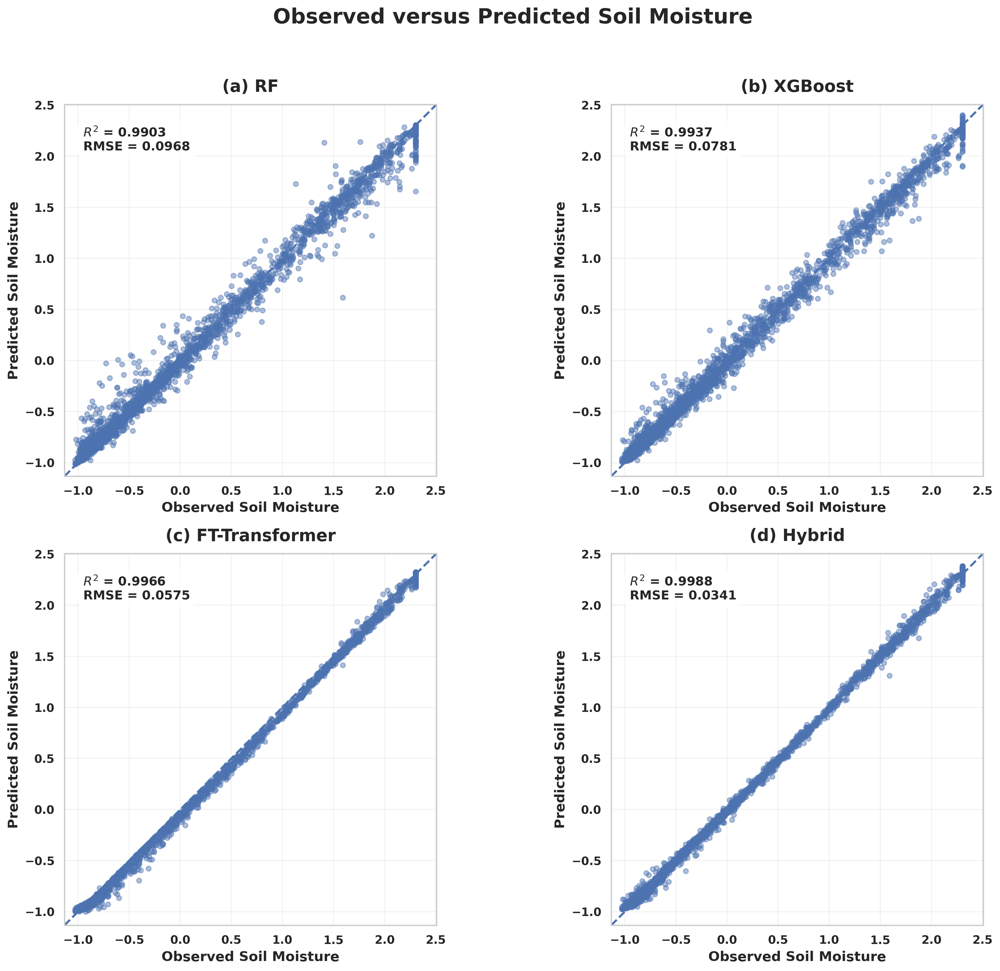


Generating Figure 7...


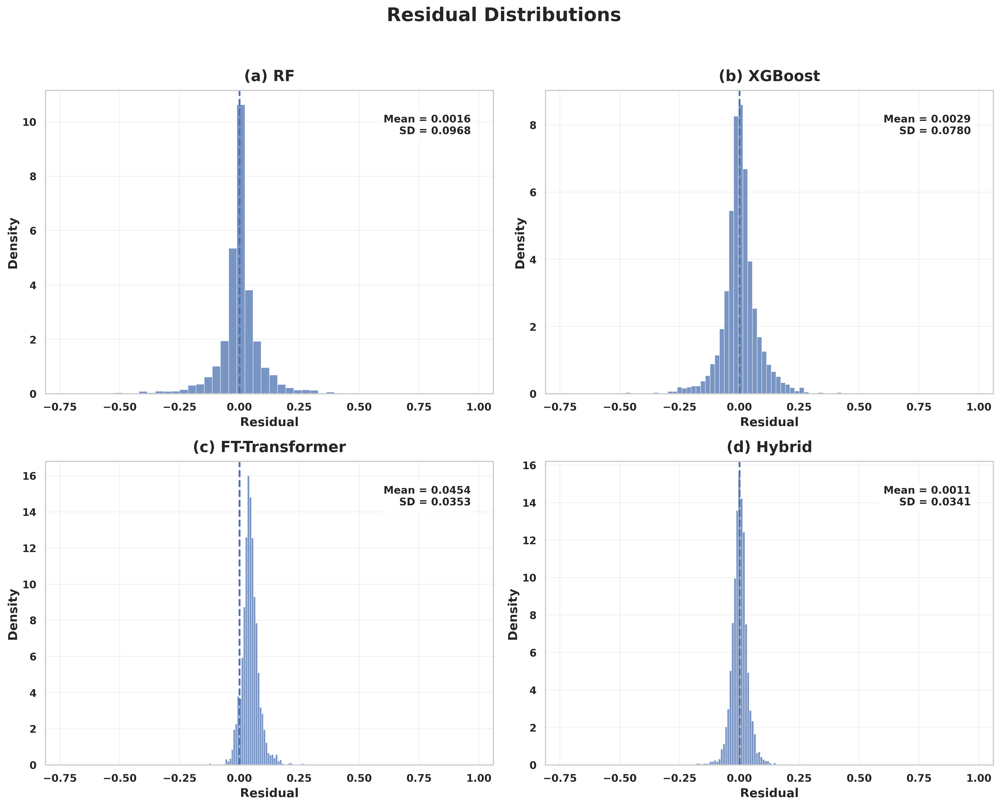


Generating Figure 8...


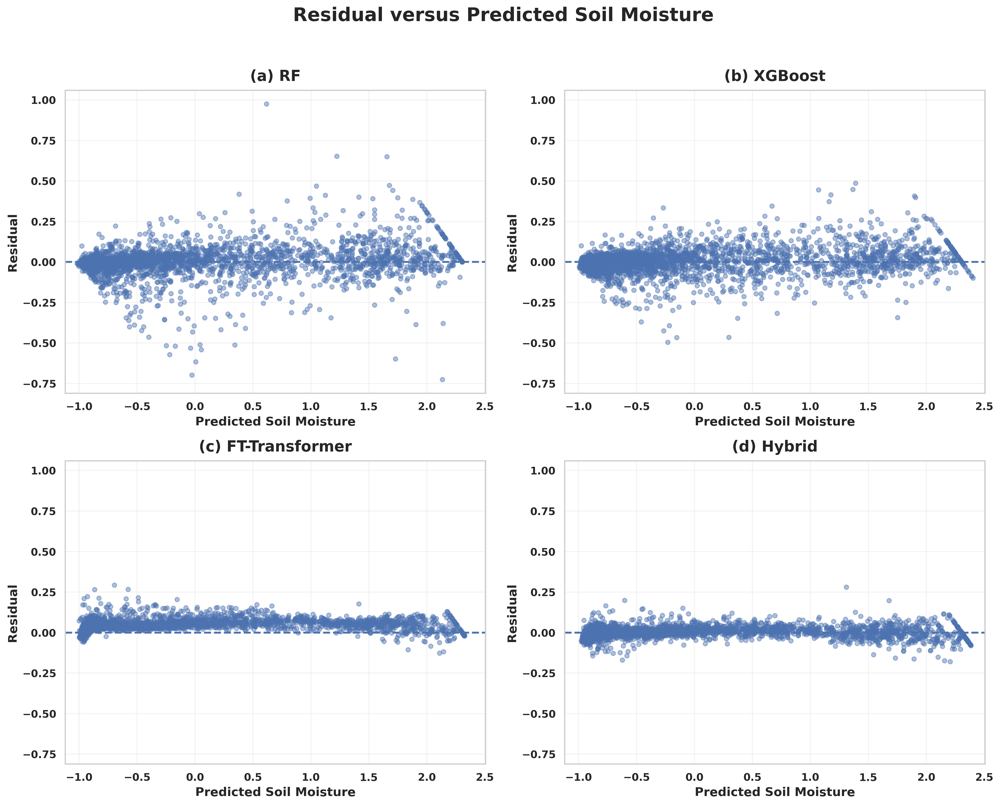


COMMON SCALE VERIFICATION

 Observed vs Predicted
X-axis: -1.132 to 2.507
Y-axis: -1.132 to 2.507

 Residual Distributions
X-axis: -0.810 to 1.060

 — Residual vs Predicted
X-axis: -1.120 to 2.506
Y-axis: -0.810 to 1.060

Figures 6, 7 and 8 generated successfully.
Resolution: 300 DPI
Scales: standardized for model comparison


In [ ]:
# ============================================================
# JOURNAL-READY FIGURES 6, 7 & 8
# RF + XGBoost + FT-Transformer + HYBRID
# COMMON SCALES FOR FAIR MODEL COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PREPARE DATA
# ============================================================

# Observed values
y_true = np.asarray(y_test).reshape(-1)

# Model predictions
rf_pred = np.asarray(rf_test_pred).reshape(-1)
xgb_pred = np.asarray(xgb_test_pred).reshape(-1)
ft_pred = np.asarray(ft_test_pred).reshape(-1)
hybrid_pred = np.asarray(final_pred).reshape(-1)

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

print("Data lengths:")
print("Observed       :", len(y_true))
print("RF             :", len(rf_pred))
print("XGBoost        :", len(xgb_pred))
print("FT-Transformer :", len(ft_pred))
print("Hybrid         :", len(hybrid_pred))

assert len(y_true) == len(rf_pred)
assert len(y_true) == len(xgb_pred)
assert len(y_true) == len(ft_pred)
assert len(y_true) == len(hybrid_pred)

# ============================================================
# MODEL DICTIONARY
# ============================================================

predictions = {

    "RF": rf_pred,

    "XGBoost": xgb_pred,

    "FT-Transformer": ft_pred,

    "Hybrid": hybrid_pred

}

# ============================================================
# RESIDUALS
# Residual = Observed - Predicted
# ============================================================

residuals = {

    "RF": y_true - rf_pred,

    "XGBoost": y_true - xgb_pred,

    "FT-Transformer": y_true - ft_pred,

    "Hybrid": y_true - hybrid_pred

}

# ============================================================
# COMMON AXIS LIMITS
# ============================================================

# ------------------------------------------------------------
# Figure 6
# Observed vs Predicted
# ------------------------------------------------------------

all_values_fig6 = np.concatenate([
    y_true,
    rf_pred,
    xgb_pred,
    ft_pred,
    hybrid_pred
])

fig6_min = np.nanmin(all_values_fig6)
fig6_max = np.nanmax(all_values_fig6)

fig6_range = fig6_max - fig6_min

fig6_margin = 0.03 * fig6_range

fig6_min -= fig6_margin
fig6_max += fig6_margin


# ------------------------------------------------------------
# Figure 7
# Residual distributions
# SAME X SCALE
# ------------------------------------------------------------

all_residuals = np.concatenate([
    residuals["RF"],
    residuals["XGBoost"],
    residuals["FT-Transformer"],
    residuals["Hybrid"]
])

fig7_min = np.nanmin(all_residuals)
fig7_max = np.nanmax(all_residuals)

fig7_range = fig7_max - fig7_min

fig7_margin = 0.05 * fig7_range

fig7_min -= fig7_margin
fig7_max += fig7_margin


# ------------------------------------------------------------
# Figure 8
# Residual vs Predicted
# SAME X AND Y SCALE
# ------------------------------------------------------------

all_predictions_fig8 = np.concatenate([
    rf_pred,
    xgb_pred,
    ft_pred,
    hybrid_pred
])

all_residuals_fig8 = np.concatenate([
    residuals["RF"],
    residuals["XGBoost"],
    residuals["FT-Transformer"],
    residuals["Hybrid"]
])

fig8_xmin = np.nanmin(all_predictions_fig8)
fig8_xmax = np.nanmax(all_predictions_fig8)

fig8_ymin = np.nanmin(all_residuals_fig8)
fig8_ymax = np.nanmax(all_residuals_fig8)

fig8_xrange = fig8_xmax - fig8_xmin
fig8_yrange = fig8_ymax - fig8_ymin

fig8_xmargin = 0.03 * fig8_xrange
fig8_ymargin = 0.05 * fig8_yrange

fig8_xmin -= fig8_xmargin
fig8_xmax += fig8_xmargin

fig8_ymin -= fig8_ymargin
fig8_ymax += fig8_ymargin


# ============================================================
# FIGURE 6
# OBSERVED VS PREDICTED SOIL MOISTURE
# ============================================================

print("\nGenerating Figure 6...")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 13)
)

axes = axes.flatten()

model_names = [
    "RF",
    "XGBoost",
    "FT-Transformer",
    "Hybrid"
]

panel_labels = [
    "(a)",
    "(b)",
    "(c)",
    "(d)"
]

for ax, name, panel in zip(
    axes,
    model_names,
    panel_labels
):

    pred_values = predictions[name]

    # --------------------------------------------------------
    # Scatter
    # --------------------------------------------------------

    ax.scatter(
        y_true,
        pred_values,
        s=22,
        alpha=0.45
    )

    # --------------------------------------------------------
    # 1:1 line
    # --------------------------------------------------------

    ax.plot(
        [fig6_min, fig6_max],
        [fig6_min, fig6_max],
        linestyle="--",
        linewidth=2
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    rmse = np.sqrt(
        np.mean(
            (y_true - pred_values) ** 2
        )
    )

    r2 = 1 - (
        np.sum(
            (y_true - pred_values) ** 2
        )
        /
        np.sum(
            (y_true - np.mean(y_true)) ** 2
        )
    )

    # --------------------------------------------------------
    # Panel title
    # --------------------------------------------------------

    ax.set_title(
        f"{panel} {name}",
        fontsize=16,
        fontweight="bold",
        pad=12
    )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax.set_xlabel(
        "Observed Soil Moisture",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Predicted Soil Moisture",
        fontsize=13,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # SAME SCALE
    # --------------------------------------------------------

    ax.set_xlim(
        fig6_min,
        fig6_max
    )

    ax.set_ylim(
        fig6_min,
        fig6_max
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    # --------------------------------------------------------
    # Metrics box
    # --------------------------------------------------------

    ax.text(
        0.05,
        0.94,
        f"$R^2$ = {r2:.4f}\nRMSE = {rmse:.4f}",
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            alpha=0.85
        )
    )

    # --------------------------------------------------------
    # Tick labels
    # --------------------------------------------------------

    ax.tick_params(
        axis="both",
        labelsize=11
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    # --------------------------------------------------------
    # Grid
    # --------------------------------------------------------

    ax.grid(
        alpha=0.25
    )


# ------------------------------------------------------------
# Figure title
# ------------------------------------------------------------

fig.suptitle(
    " Observed versus Predicted Soil Moisture",
    fontsize=20,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.savefig(
    "Figure_6_Observed_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 7
# RESIDUAL DISTRIBUTIONS
# SAME X SCALE
# ============================================================

print("\nGenerating Figure 7...")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 12)
)

axes = axes.flatten()

for ax, name, panel in zip(
    axes,
    model_names,
    panel_labels
):

    res = residuals[name]

    # --------------------------------------------------------
    # Histogram
    # --------------------------------------------------------

    ax.hist(
        res,
        bins=50,
        density=True,
        alpha=0.75,
        edgecolor="white",
        linewidth=0.5
    )

    # --------------------------------------------------------
    # Zero residual line
    # --------------------------------------------------------

    ax.axvline(
        0,
        linestyle="--",
        linewidth=2
    )

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    mean_res = np.mean(res)

    std_res = np.std(res)

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax.set_title(
        f"{panel} {name}",
        fontsize=16,
        fontweight="bold",
        pad=10
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_xlabel(
        "Residual",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Density",
        fontsize=13,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # SAME X SCALE
    # --------------------------------------------------------

    ax.set_xlim(
        fig7_min,
        fig7_max
    )

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    ax.text(
        0.95,
        0.92,
        f"Mean = {mean_res:.4f}\n"
        f"SD = {std_res:.4f}",
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        horizontalalignment="right",
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            alpha=0.85
        )
    )

    # --------------------------------------------------------
    # Tick formatting
    # --------------------------------------------------------

    ax.tick_params(
        axis="both",
        labelsize=11
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.grid(
        alpha=0.25
    )


fig.suptitle(
    " Residual Distributions",
    fontsize=20,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.savefig(
    "Figure_7_Residual_Distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 8
# RESIDUAL VERSUS PREDICTED SOIL MOISTURE
# SAME X + Y SCALE
# ============================================================

print("\nGenerating Figure 8...")

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 12)
)

axes = axes.flatten()

for ax, name, panel in zip(
    axes,
    model_names,
    panel_labels
):

    pred_values = predictions[name]

    res = residuals[name]

    # --------------------------------------------------------
    # Scatter
    # --------------------------------------------------------

    ax.scatter(
        pred_values,
        res,
        s=22,
        alpha=0.45
    )

    # --------------------------------------------------------
    # Zero residual line
    # --------------------------------------------------------

    ax.axhline(
        0,
        linestyle="--",
        linewidth=2
    )

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax.set_title(
        f"{panel} {name}",
        fontsize=16,
        fontweight="bold",
        pad=10
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_xlabel(
        "Predicted Soil Moisture",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Residual",
        fontsize=13,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # SAME X SCALE
    # --------------------------------------------------------

    ax.set_xlim(
        fig8_xmin,
        fig8_xmax
    )

    # --------------------------------------------------------
    # SAME Y SCALE
    # --------------------------------------------------------

    ax.set_ylim(
        fig8_ymin,
        fig8_ymax
    )

    # --------------------------------------------------------
    # Tick labels
    # --------------------------------------------------------

    ax.tick_params(
        axis="both",
        labelsize=11
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    # --------------------------------------------------------
    # Grid
    # --------------------------------------------------------

    ax.grid(
        alpha=0.25
    )


fig.suptitle(
    " Residual versus Predicted Soil Moisture",
    fontsize=20,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.savefig(
    "Figure_8_Residual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FINAL SCALE REPORT
# ============================================================

print("\n" + "=" * 70)
print("COMMON SCALE VERIFICATION")
print("=" * 70)

print("\n Observed vs Predicted")
print(
    f"X-axis: {fig6_min:.3f} to {fig6_max:.3f}"
)
print(
    f"Y-axis: {fig6_min:.3f} to {fig6_max:.3f}"
)

print("\n Residual Distributions")
print(
    f"X-axis: {fig7_min:.3f} to {fig7_max:.3f}"
)

print("\n — Residual vs Predicted")
print(
    f"X-axis: {fig8_xmin:.3f} to {fig8_xmax:.3f}"
)
print(
    f"Y-axis: {fig8_ymin:.3f} to {fig8_ymax:.3f}"
)

print("\nFigures 6, 7 and 8 generated successfully.")
print("Resolution: 300 DPI")
print("Scales: standardized for model comparison")

In [ ]:
# ============================================================
# COMPARATIVE PERFORMANCE METRICS
# RF + XGBoost + FT-Transformer + Hybrid
# JOURNAL-READY GROUPED BAR PLOTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PREPARE OBSERVED AND PREDICTED VALUES
# ============================================================

y_true = np.asarray(y_test).reshape(-1)

rf_pred = np.asarray(rf_test_pred).reshape(-1)
xgb_pred = np.asarray(xgb_test_pred).reshape(-1)
ft_pred = np.asarray(ft_test_pred).reshape(-1)
hybrid_pred = np.asarray(final_pred).reshape(-1)

# ============================================================
# FUNCTION TO CALCULATE ALL METRICS
# ============================================================

def calculate_metrics(y_true, y_pred):

    mse = np.mean(
        (y_true - y_pred) ** 2
    )

    rmse = np.sqrt(mse)

    mae = np.mean(
        np.abs(y_true - y_pred)
    )

    r2 = 1 - (
        np.sum(
            (y_true - y_pred) ** 2
        )
        /
        np.sum(
            (y_true - np.mean(y_true)) ** 2
        )
    )

    nse = 1 - (
        np.sum(
            (y_true - y_pred) ** 2
        )
        /
        np.sum(
            (y_true - np.mean(y_true)) ** 2
        )
    )

    r = np.corrcoef(
        y_true,
        y_pred
    )[0, 1]

    return {
        "RMSE": rmse,
        "MAE": mae,
        "MSE": mse,
        "R²": r2,
        "NSE": nse,
        "R": r
    }


# ============================================================
# CALCULATE METRICS FOR ALL MODELS
# ============================================================

metrics = {

    "RF":
        calculate_metrics(
            y_true,
            rf_pred
        ),

    "XGBoost":
        calculate_metrics(
            y_true,
            xgb_pred
        ),

    "FT-Transformer":
        calculate_metrics(
            y_true,
            ft_pred
        ),

    "Hybrid":
        calculate_metrics(
            y_true,
            hybrid_pred
        )
}


# ============================================================
# CONVERT TO DATAFRAME
# ============================================================

metrics_df = pd.DataFrame(
    metrics
).T

print("\nMODEL PERFORMANCE COMPARISON")
print("=" * 80)

print(
    metrics_df.round(6)
)


# ============================================================
# FIGURE 13
# ERROR METRICS
# RMSE + MAE + MSE
# ============================================================

print("\nGenerating Figure 13...")

error_metrics = [
    "RMSE",
    "MAE",
    "MSE"
]

models = [
    "RF",
    "XGBoost",
    "FT-Transformer",
    "Hybrid"
]

x = np.arange(
    len(error_metrics)
)

width = 0.19


fig, ax = plt.subplots(
    figsize=(14, 8)
)


# ------------------------------------------------------------
# Bars
# ------------------------------------------------------------

for i, model_name in enumerate(models):

    values = [
        metrics[model_name][metric]
        for metric in error_metrics
    ]

    bars = ax.bar(
        x + (i - 1.5) * width,
        values,
        width=width,
        label=model_name,
        edgecolor="black",
        linewidth=1.0
    )

    # --------------------------------------------------------
    # Values above bars
    # --------------------------------------------------------

    for bar, value in zip(
        bars,
        values
    ):

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,

            bar.get_height(),

            f"{value:.4f}",

            ha="center",
            va="bottom",

            fontsize=10,
            fontweight="bold",

            rotation=90
        )


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_title(
    "Figure 13. Comparative Error Metrics",
    fontsize=20,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Evaluation Metrics",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Metric Value",
    fontsize=14,
    fontweight="bold"
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    error_metrics,
    fontsize=13,
    fontweight="bold"
)

ax.tick_params(
    axis="y",
    labelsize=11
)

for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend = ax.legend(
    fontsize=11,
    frameon=True,
    loc="upper right"
)

for text in legend.get_texts():
    text.set_fontweight("bold")


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)


# ------------------------------------------------------------
# Y LIMIT
# ------------------------------------------------------------

error_max = metrics_df[
    error_metrics
].values.max()

ax.set_ylim(
    0,
    error_max * 1.30
)


plt.tight_layout()

plt.savefig(
    "Figure_13_Comparative_Error_Metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 14
# AGREEMENT METRICS
# R² + NSE + R
# ============================================================

print("\nGenerating Figure 14...")

agreement_metrics = [
    "R²",
    "NSE",
    "R"
]

x = np.arange(
    len(agreement_metrics)
)

width = 0.19


fig, ax = plt.subplots(
    figsize=(14, 8)
)


# ------------------------------------------------------------
# Bars
# ------------------------------------------------------------

for i, model_name in enumerate(models):

    values = [
        metrics[model_name][metric]
        for metric in agreement_metrics
    ]

    bars = ax.bar(
        x + (i - 1.5) * width,
        values,
        width=width,
        label=model_name,
        edgecolor="black",
        linewidth=1.0
    )

    # --------------------------------------------------------
    # Values above bars
    # --------------------------------------------------------

    for bar, value in zip(
        bars,
        values
    ):

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,

            bar.get_height(),

            f"{value:.4f}",

            ha="center",
            va="bottom",

            fontsize=10,
            fontweight="bold",

            rotation=90
        )


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_title(
    "Figure 14. Comparative Agreement Metrics",
    fontsize=20,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Evaluation Metrics",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Metric Value",
    fontsize=14,
    fontweight="bold"
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    agreement_metrics,
    fontsize=13,
    fontweight="bold"
)

ax.tick_params(
    axis="y",
    labelsize=11
)

for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend = ax.legend(
    fontsize=11,
    frameon=True,
    loc="lower right"
)

for text in legend.get_texts():
    text.set_fontweight("bold")


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)


# ------------------------------------------------------------
# Y LIMIT
# ------------------------------------------------------------

agreement_values = metrics_df[
    agreement_metrics
].values

agreement_min = np.nanmin(
    agreement_values
)

agreement_max = np.nanmax(
    agreement_values
)

# Keep enough space for labels
ax.set_ylim(
    min(0, agreement_min - 0.05),
    min(1.10, agreement_max + 0.08)
)


plt.tight_layout()

plt.savefig(
    "Figure_14_Comparative_Agreement_Metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FINAL TABLE
# ============================================================

print("\n" + "=" * 80)
print("FINAL PERFORMANCE TABLE")
print("=" * 80)

display(
    metrics_df.round(6)
)

In [ ]:
# ============================================================
# INDIVIDUAL PERFORMANCE METRICS
# SEABORN COLORS
# RF + XGBOOST + FT-TRANSFORMER + HYBRID
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# SEABORN STYLE
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

# Seaborn colors
colors = sns.color_palette(
    "deep",
    6
)

# ============================================================
# MODELS
# ============================================================

models = [
    "RF",
    "XGBoost",
    "FT-Transformer",
    "Hybrid"
]

# ============================================================
# METRICS
# ============================================================

metric_names = [
    "RMSE",
    "MAE",
    "MSE",
    "R²",
    "NSE",
    "R"
]

# ============================================================
# INDIVIDUAL PLOTS
# ============================================================

for model_name in models:

    print(
        f"Generating {model_name} Performance Metrics..."
    )

    values = [
        metrics[model_name]["RMSE"],
        metrics[model_name]["MAE"],
        metrics[model_name]["MSE"],
        metrics[model_name]["R²"],
        metrics[model_name]["NSE"],
        metrics[model_name]["R"]
    ]

    # --------------------------------------------------------
    # FIGURE
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(14, 7)
    )

    x = np.arange(
        len(metric_names)
    )

    # --------------------------------------------------------
    # BARS WITH SEABORN COLORS
    # --------------------------------------------------------

    bars = ax.bar(
        x,
        values,
        width=0.65,
        color=colors,
        edgecolor="black",
        linewidth=1.2
    )

    # --------------------------------------------------------
    # VALUES
    # --------------------------------------------------------

    for bar, value in zip(
        bars,
        values
    ):

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,

            bar.get_height()
            + max(values) * 0.015,

            f"{value:.4f}",

            ha="center",
            va="bottom",

            fontsize=12,
            fontweight="bold"
        )

    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    ax.set_title(
        f"{model_name} Performance Metrics",
        fontsize=20,
        fontweight="bold",
        pad=18
    )

    # --------------------------------------------------------
    # X AXIS
    # --------------------------------------------------------

    ax.set_xlabel(
        "Evaluation Metrics",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        metric_names,
        fontsize=13,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Y AXIS
    # --------------------------------------------------------

    ax.set_ylabel(
        "Metric Value",
        fontsize=14,
        fontweight="bold"
    )

    ax.tick_params(
        axis="y",
        labelsize=11
    )

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    # --------------------------------------------------------
    # GRID
    # --------------------------------------------------------

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.8,
        alpha=0.3
    )

    ax.grid(
        axis="x",
        visible=False
    )

    # --------------------------------------------------------
    # Y LIMIT
    # --------------------------------------------------------

    max_value = max(values)

    ax.set_ylim(
        0,
        max_value * 1.18
    )

    # --------------------------------------------------------
    # REMOVE EXTRA SPINES
    # --------------------------------------------------------

    sns.despine(
        ax=ax,
        top=True,
        right=True
    )

    # --------------------------------------------------------
    # LAYOUT
    # --------------------------------------------------------

    plt.tight_layout()

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    safe_name = (
        model_name
        .replace("-", "")
        .replace(" ", "_")
    )

    plt.savefig(
        f"{safe_name}_Performance_Metrics.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


print(
    "\nAll individual performance metric plots generated."
)

Generating RF Performance Metrics...


KeyError: 'RF'

Generating Figure 15...
Dataset shape: (15575, 53)
District column: District_Name

District values detected:
['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '3', '4', '5', '6', '7', '8', '9']

Hybrid prediction was not found.
Figure is therefore using observed SoilMoisture.

DISTRICT ID → DISTRICT NAME
 1 = 0
 2 = 1
 3 = 10
 4 = 11
 5 = 12
 6 = 13
 7 = 14
 8 = 15
 9 = 16
10 = 17
11 = 18
12 = 19
13 = 2
14 = 20
15 = 21
16 = 22
17 = 23
18 = 24
19 = 25
20 = 26
21 = 27
22 = 3
23 = 4
24 = 5
25 = 6
26 = 7
27 = 8
28 = 9


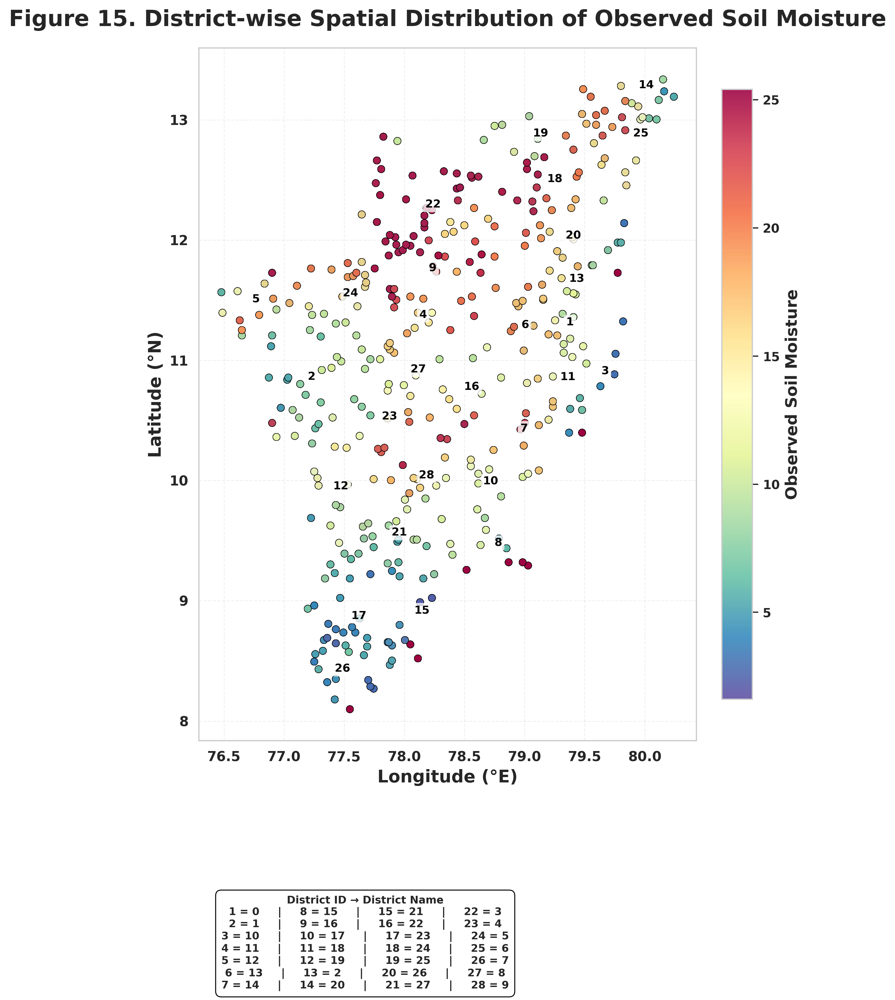

<Figure size 960x720 with 0 Axes>


FIGURE 15 GENERATED SUCCESSFULLY
Number of districts: 28
Number of spatial samples: 15575
Prediction used: None
Minimum value: 1.6127
Maximum value: 25.4000
Saved as: Figure_15_District_Wise_Spatial_Soil_Moisture.png


In [ ]:
# ============================================================
# FIGURE 15
# DISTRICT-WISE SPATIAL DISTRIBUTION OF SOIL MOISTURE
# JOURNAL-READY VERSION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

print("Generating Figure 15...")

# ============================================================
# 1. COPY DATAFRAME
# ============================================================

plot_df = df.copy()

print("Dataset shape:", plot_df.shape)

# ============================================================
# 2. CHECK REQUIRED SPATIAL COLUMNS
# ============================================================

required_columns = [
    "Latitude",
    "Longitude"
]

missing_columns = [
    col for col in required_columns
    if col not in plot_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ============================================================
# 3. IDENTIFY DISTRICT COLUMN
# ============================================================

# Priority:
# District_Name -> District -> other possible district columns

district_column = None

if "District_Name" in plot_df.columns:
    district_column = "District_Name"

elif "District" in plot_df.columns:
    district_column = "District"

else:

    possible_district_columns = [
        col for col in plot_df.columns
        if "district" in col.lower()
    ]

    if len(possible_district_columns) > 0:
        district_column = possible_district_columns[0]

if district_column is None:

    raise ValueError(
        """
        Original district-name column was not found.

        Expected one of:
        District_Name
        District

        Please check your dataframe.
        """
    )

print("District column:", district_column)

# ============================================================
# 4. CLEAN DISTRICT NAMES
# ============================================================

plot_df["DistrictName"] = (
    plot_df[district_column]
    .astype(str)
    .str.strip()
)

# Remove invalid district values
invalid_districts = [
    "",
    "nan",
    "None",
    "null"
]

plot_df = plot_df[
    ~plot_df["DistrictName"].isin(invalid_districts)
].copy()

# ============================================================
# 5. CHECK WHETHER DISTRICT VALUES ARE ACTUAL NAMES
# ============================================================

print("\nDistrict values detected:")
print(
    sorted(
        plot_df["DistrictName"].unique()
    )
)

# ============================================================
# 6. IDENTIFY PREDICTION VALUES
# ============================================================

prediction_name = None

# ------------------------------------------------------------
# First check prediction columns already stored in df
# ------------------------------------------------------------

prediction_columns = [

    "Hybrid_Prediction",
    "HybridPrediction",
    "Hybrid_Pred",
    "Predicted_SoilMoisture",
    "Predicted_Soil_Moisture",
    "PredictedSoilMoisture",
    "Prediction",
    "Predicted",
    "y_pred",
    "prediction",
    "hybrid_pred",
    "oof_pred",
    "oof_predictions",
    "hybrid_predictions"
]

for col in prediction_columns:

    if col in plot_df.columns:

        prediction_name = col

        print(
            f"\nPrediction column found: {col}"
        )

        break

# ------------------------------------------------------------
# If no prediction column exists, check notebook variables
# ------------------------------------------------------------

if prediction_name is None:

    possible_prediction_variables = [

        "final_pred",
        "hybrid_pred",
        "oof_pred",
        "oof_predictions",
        "hybrid_predictions"

    ]

    for variable_name in possible_prediction_variables:

        if variable_name in globals():

            candidate = globals()[variable_name]

            try:

                candidate = np.asarray(
                    candidate
                ).reshape(-1)

                if len(candidate) == len(plot_df):

                    plot_df[
                        "Hybrid_Prediction"
                    ] = candidate

                    prediction_name = (
                        "Hybrid_Prediction"
                    )

                    print(
                        f"\nPrediction variable found: "
                        f"{variable_name}"
                    )

                    break

            except Exception:
                pass

# ============================================================
# 7. FALLBACK
# ============================================================

# IMPORTANT:
# If Hybrid predictions are unavailable, use observed
# SoilMoisture only so the figure can still be generated.
# The title will automatically say OBSERVED instead of PREDICTED.

if prediction_name is None:

    if "SoilMoisture" not in plot_df.columns:

        raise ValueError(
            """
            No Hybrid prediction and no SoilMoisture column
            are available.

            Please provide a prediction column.
            """
        )

    plot_df["PlotValue"] = pd.to_numeric(
        plot_df["SoilMoisture"],
        errors="coerce"
    )

    plot_title = (
        "Figure 15. District-wise Spatial Distribution "
        "of Observed Soil Moisture"
    )

    colorbar_label = "Observed Soil Moisture"

    print(
        "\nWARNING:"
        "\nHybrid prediction was not found."
        "\nFigure is therefore using observed SoilMoisture."
    )

else:

    plot_df["PlotValue"] = pd.to_numeric(
        plot_df[prediction_name],
        errors="coerce"
    )

    plot_title = (
        "Figure 15. District-wise Spatial Distribution "
        "of Predicted Soil Moisture"
    )

    colorbar_label = "Predicted Soil Moisture"

    print(
        "\nUsing prediction:",
        prediction_name
    )

# ============================================================
# 8. REMOVE INVALID VALUES
# ============================================================

plot_df["Latitude"] = pd.to_numeric(
    plot_df["Latitude"],
    errors="coerce"
)

plot_df["Longitude"] = pd.to_numeric(
    plot_df["Longitude"],
    errors="coerce"
)

plot_df = plot_df.dropna(
    subset=[
        "Latitude",
        "Longitude",
        "PlotValue",
        "DistrictName"
    ]
).copy()

# ============================================================
# 9. CREATE DISTRICT IDs
# ============================================================

# Alphabetical ordering gives a reproducible ID system.

district_names = sorted(
    plot_df["DistrictName"].unique()
)

district_id_map = {
    district: i + 1
    for i, district in enumerate(district_names)
}

plot_df["DistrictID"] = (
    plot_df["DistrictName"]
    .map(district_id_map)
)

# ============================================================
# 10. DISTRICT CENTROIDS
# ============================================================

district_centers = (
    plot_df
    .groupby(
        ["DistrictID", "DistrictName"],
        as_index=False
    )
    .agg(
        Longitude=("Longitude", "mean"),
        Latitude=("Latitude", "mean")
    )
)

# ============================================================
# 11. PRINT DISTRICT MAPPING
# ============================================================

print("\n" + "=" * 70)
print("DISTRICT ID → DISTRICT NAME")
print("=" * 70)

for _, row in district_centers.sort_values(
    "DistrictID"
).iterrows():

    print(
        f"{int(row['DistrictID']):2d} = "
        f"{row['DistrictName']}"
    )

print("=" * 70)

# ============================================================
# 12. FIGURE SETTINGS
# ============================================================

mpl.rcParams.update({

    "font.family": "DejaVu Sans",

    "font.size": 11,

    "axes.titlesize": 16,

    "axes.labelsize": 14,

    "axes.titleweight": "bold",

    "axes.labelweight": "bold",

    "xtick.labelsize": 11,

    "ytick.labelsize": 11

})

fig, ax = plt.subplots(
    figsize=(14, 12),
    dpi=300
)

# ============================================================
# 13. COLOR SCALE
# ============================================================

vmin = plot_df["PlotValue"].min()
vmax = plot_df["PlotValue"].max()

norm = mpl.colors.Normalize(
    vmin=vmin,
    vmax=vmax
)

# ============================================================
# 14. SPATIAL SCATTER
# ============================================================

scatter = ax.scatter(

    plot_df["Longitude"],

    plot_df["Latitude"],

    c=plot_df["PlotValue"],

    cmap="Spectral_r",

    norm=norm,

    s=34,

    alpha=0.88,

    edgecolors="black",

    linewidths=0.35

)

# ============================================================
# 15. DISTRICT ID LABELS
# ============================================================

# IDs are placed near district centroid.
# The actual district names are provided below the figure.

for _, row in district_centers.iterrows():

    ax.annotate(

        str(int(row["DistrictID"])),

        xy=(
            row["Longitude"],
            row["Latitude"]
        ),

        xytext=(5, 5),

        textcoords="offset points",

        fontsize=9,

        fontweight="bold",

        color="black",

        ha="left",

        va="bottom",

        bbox=dict(

            boxstyle="round,pad=0.20",

            facecolor="white",

            edgecolor="none",

            alpha=0.78

        )

    )

# ============================================================
# 16. EQUAL SPATIAL SCALE
# ============================================================

ax.set_aspect(
    "equal",
    adjustable="box"
)

# ============================================================
# 17. AXIS LABELS
# ============================================================

ax.set_xlabel(
    "Longitude (°E)",
    fontweight="bold",
    fontsize=14
)

ax.set_ylabel(
    "Latitude (°N)",
    fontweight="bold",
    fontsize=14
)

# ============================================================
# 18. TITLE
# ============================================================

ax.set_title(
    plot_title,
    fontsize=18,
    fontweight="bold",
    pad=18
)

# ============================================================
# 19. GRID
# ============================================================

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.30
)

# ============================================================
# 20. COLORBAR
# ============================================================

cbar = fig.colorbar(
    scatter,
    ax=ax,
    pad=0.025,
    shrink=0.88
)

cbar.set_label(
    colorbar_label,
    fontsize=13,
    fontweight="bold"
)

cbar.ax.tick_params(
    labelsize=10
)

# ============================================================
# 21. BOLD TICKS
# ============================================================

for tick in ax.get_xticklabels():

    tick.set_fontweight("bold")

for tick in ax.get_yticklabels():

    tick.set_fontweight("bold")

for tick in cbar.ax.get_yticklabels():

    tick.set_fontweight("bold")

# ============================================================
# 22. DISTRICT ID → DISTRICT NAME MAPPING
# ============================================================

# Split into multiple lines so the bottom remains readable.

mapping_text = []

for _, row in district_centers.sort_values(
    "DistrictID"
).iterrows():

    mapping_text.append(
        f"{int(row['DistrictID'])} = {row['DistrictName']}"
    )

# ------------------------------------------------------------
# Determine number of columns automatically
# ------------------------------------------------------------

n_districts = len(mapping_text)

if n_districts <= 10:
    n_columns = 2

elif n_districts <= 20:
    n_columns = 3

else:
    n_columns = 4

rows_per_column = int(
    np.ceil(
        n_districts / n_columns
    )
)

mapping_columns = []

for i in range(n_columns):

    start = i * rows_per_column
    end = min(
        start + rows_per_column,
        n_districts
    )

    mapping_columns.append(
        mapping_text[start:end]
    )

# Make equal-length columns
max_rows = max(
    len(col)
    for col in mapping_columns
)

for col in mapping_columns:

    while len(col) < max_rows:

        col.append("")

# ------------------------------------------------------------
# Build display text
# ------------------------------------------------------------

mapping_lines = []

for row_index in range(max_rows):

    line_parts = []

    for col in mapping_columns:

        line_parts.append(
            col[row_index]
        )

    mapping_lines.append(
        "     |     ".join(line_parts)
    )

mapping_text_final = "\n".join(
    mapping_lines
)

# ============================================================
# REPLACE ONLY THE BOTTOM DISTRICT MAPPING SECTION
# ============================================================

# Create ID → ORIGINAL DISTRICT NAME mapping
district_mapping = (
    plot_df[
        ["DistrictID", "DistrictName"]
    ]
    .drop_duplicates()
    .sort_values("DistrictID")
)

# Create readable mapping text
mapping_text = []

for _, row in district_mapping.iterrows():

    district_id = int(row["DistrictID"])
    district_name = str(row["DistrictName"]).strip()

    mapping_text.append(
        f"{district_id} = {district_name}"
    )

# ============================================================
# ARRANGE INTO 4 COLUMNS
# ============================================================

n_columns = 4

n_items = len(mapping_text)

rows_per_column = int(
    np.ceil(n_items / n_columns)
)

mapping_columns = []

for i in range(n_columns):

    start = i * rows_per_column
    end = min(
        start + rows_per_column,
        n_items
    )

    mapping_columns.append(
        mapping_text[start:end]
    )

# Make all columns same length
max_rows = max(
    len(col)
    for col in mapping_columns
)

for col in mapping_columns:

    while len(col) < max_rows:
        col.append("")

# ============================================================
# BUILD FINAL BOTTOM TEXT
# ============================================================

mapping_lines = []

for row_index in range(max_rows):

    line_parts = []

    for col in mapping_columns:

        line_parts.append(
            col[row_index]
        )

    mapping_lines.append(
        "     |     ".join(line_parts)
    )

mapping_text_final = "\n".join(
    mapping_lines
)

# ============================================================
# BOTTOM DISTRICT NAME BOX
# ============================================================

fig.text(

    0.5,

    0.015,

    "District ID → District Name\n"
    + mapping_text_final,

    ha="center",

    va="bottom",

    fontsize=8.5,

    fontweight="bold",

    bbox=dict(

        boxstyle="round,pad=0.55",

        facecolor="white",

        edgecolor="black",

        linewidth=0.8,

        alpha=0.96

    )

)

# ============================================================
# SAVE
# ============================================================

plt.subplots_adjust(
    left=0.09,
    right=0.91,
    top=0.90,
    bottom=0.25
)

plt.savefig(
    "Figure_15_District_Wise_Spatial_Soil_Moisture.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
# ============================================================
# 23. ADD DISTRICT MAPPING BELOW FIGURE
# ============================================================

fig.text(

    0.5,

    0.015,

    "District ID → District Name\n"
    + mapping_text_final,

    ha="center",

    va="bottom",

    fontsize=8.5,

    fontweight="bold",

    bbox=dict(

        boxstyle="round,pad=0.55",

        facecolor="white",

        edgecolor="black",

        linewidth=0.8,

        alpha=0.96

    )

)

# ============================================================
# 24. LAYOUT
# ============================================================

plt.subplots_adjust(

    left=0.09,

    right=0.91,

    top=0.90,

    bottom=0.25

)

# ============================================================
# 25. SAVE HIGH-RESOLUTION FIGURE
# ============================================================

output_file = (
    "Figure_15_District_Wise_Spatial_Soil_Moisture.png"
)

plt.savefig(

    output_file,

    dpi=600,

    bbox_inches="tight",

    facecolor="white"

)

# ============================================================
# 26. DISPLAY
# ============================================================

plt.show()

# ============================================================
# 27. FINAL INFORMATION
# ============================================================

print("\n" + "=" * 70)

print("FIGURE 15 GENERATED SUCCESSFULLY")

print("=" * 70)

print(
    "Number of districts:",
    len(district_names)
)

print(
    "Number of spatial samples:",
    len(plot_df)
)

print(
    "Prediction used:",
    prediction_name
)

print(
    "Minimum value:",
    f"{vmin:.4f}"
)

print(
    "Maximum value:",
    f"{vmax:.4f}"
)

print(
    "Saved as:",
    output_file
)

print("=" * 70)

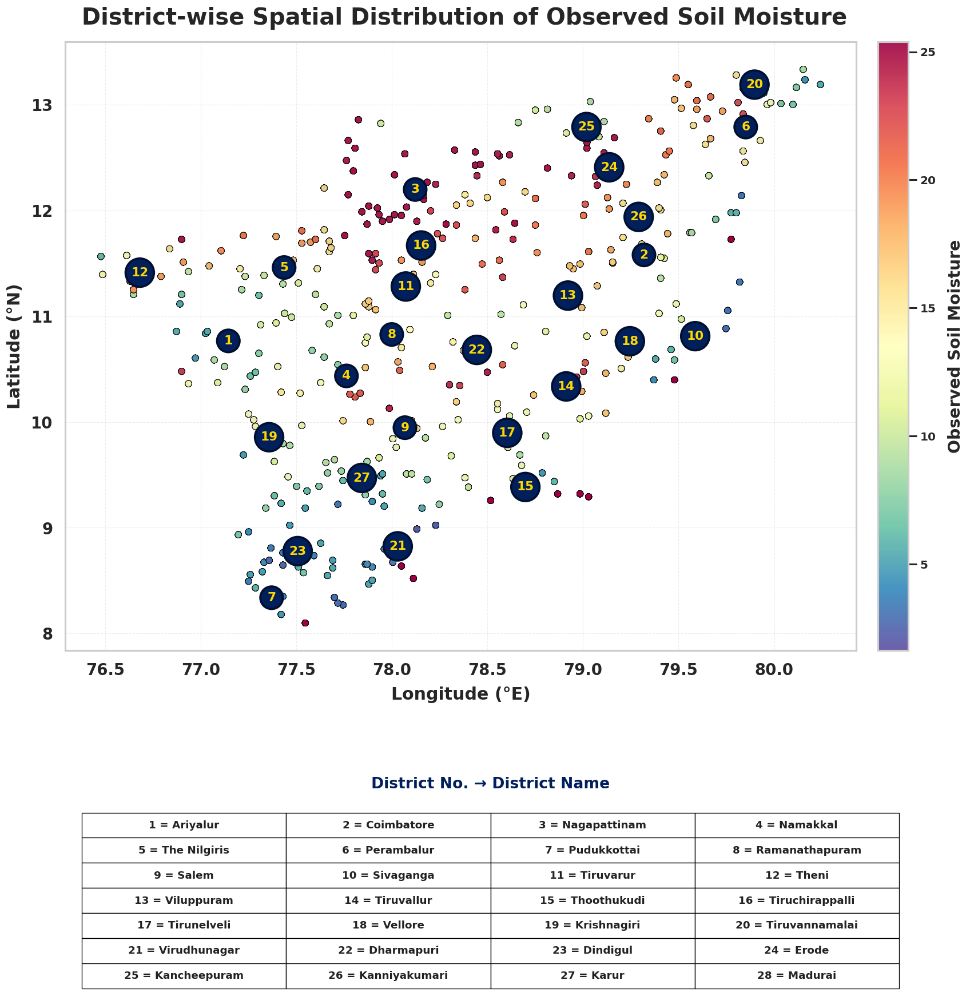

In [ ]:
# ============================================================
# FIGURE 15 – DISTRICT-WISE SPATIAL DISTRIBUTION
#
# FINAL VERSION
# - Navy blue circular district labels
# - Yellow district numbers
# - Large readable labels
# - Separate bottom section for district table
# - No heading/table overlap
# - No x-axis/table overlap
# - 4-column aligned district table
# - 600 DPI output
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec


# ============================================================
# 1. DISTRICT NUMBER → DISTRICT NAME
# ============================================================

district_names = {
    1: "Ariyalur",
    2: "Coimbatore",
    3: "Nagapattinam",
    4: "Namakkal",
    5: "The Nilgiris",
    6: "Perambalur",
    7: "Pudukkottai",
    8: "Ramanathapuram",
    9: "Salem",
    10: "Sivaganga",
    11: "Tiruvarur",
    12: "Theni",
    13: "Viluppuram",
    14: "Tiruvallur",
    15: "Thoothukudi",
    16: "Tiruchirappalli",
    17: "Tirunelveli",
    18: "Vellore",
    19: "Krishnagiri",
    20: "Tiruvannamalai",
    21: "Virudhunagar",
    22: "Dharmapuri",
    23: "Dindigul",
    24: "Erode",
    25: "Kancheepuram",
    26: "Kanniyakumari",
    27: "Karur",
    28: "Madurai"
}


# ============================================================
# 2. COPY DATA
# ============================================================

plot_df = df.copy()


# ============================================================
# 3. CONVERT LATITUDE / LONGITUDE TO NUMERIC
# ============================================================

plot_df["Latitude"] = pd.to_numeric(
    plot_df["Latitude"],
    errors="coerce"
)

plot_df["Longitude"] = pd.to_numeric(
    plot_df["Longitude"],
    errors="coerce"
)


# Remove invalid coordinates
plot_df = plot_df.dropna(
    subset=["Latitude", "Longitude"]
).copy()


# ============================================================
# 4. DISTRICT NUMBER
# ============================================================

plot_df["District_No"] = pd.to_numeric(
    plot_df["District"],
    errors="coerce"
)

plot_df = plot_df.dropna(
    subset=["District_No"]
).copy()

plot_df["District_No"] = (
    plot_df["District_No"]
    .astype(int)
)


# ============================================================
# IMPORTANT:
# KEEP ONLY DISTRICTS 1–28
#
# This removes invalid values such as 0.
# ============================================================

plot_df = plot_df[
    plot_df["District_No"].between(1, 28)
].copy()


# ============================================================
# 5. SOIL MOISTURE
# ============================================================

soil_col = "SoilMoisture"

plot_df[soil_col] = pd.to_numeric(
    plot_df[soil_col],
    errors="coerce"
)

plot_df = plot_df.dropna(
    subset=[soil_col]
).copy()

soil_values = plot_df[soil_col]


# ============================================================
# 6. STYLE
# ============================================================

sns.set_theme(
    style="whitegrid",
    context="talk"
)


# ============================================================
# 7. CREATE FIGURE USING GRIDSPEC
#
# TOP    = MAP
# BOTTOM = DISTRICT TABLE
#
# This completely separates the table from the graph.
# ============================================================

fig = plt.figure(
    figsize=(16, 18)
)

gs = GridSpec(
    nrows=2,
    ncols=1,
    figure=fig,

    # Large map + smaller table area
    height_ratios=[5.4, 2.0],

    # Space between map and table
    hspace=0.28
)


# ============================================================
# 8. MAP AXES
# ============================================================

ax = fig.add_subplot(
    gs[0]
)


# ============================================================
# 9. SCATTER PLOT
# ============================================================

scatter = ax.scatter(
    plot_df["Longitude"],
    plot_df["Latitude"],

    c=soil_values,

    cmap="Spectral_r",

    s=45,

    alpha=0.90,

    edgecolors="black",

    linewidths=0.45,

    zorder=2
)


# ============================================================
# 10. REPRESENTATIVE LOCATION FOR EACH DISTRICT
# ============================================================

district_locations = (
    plot_df
    .groupby("District_No")
    .agg(
        Longitude=("Longitude", "mean"),
        Latitude=("Latitude", "mean")
    )
    .reset_index()
)


# ============================================================
# 11. DISTRICT NUMBER LABELS
#
# NAVY BLUE CIRCLE
# YELLOW NUMBER
# ============================================================

for _, row in district_locations.iterrows():

    district_no = int(row["District_No"])

    ax.text(
        row["Longitude"],
        row["Latitude"],

        # District number
        str(district_no),

        # Larger number
        fontsize=13,

        # Bold
        fontweight="bold",

        # Yellow number
        color="#FFD700",

        # Center
        ha="center",
        va="center",

        # Navy blue circular background
        bbox=dict(
            boxstyle="circle,pad=0.45",

            # Navy blue
            facecolor="#001F5B",

            # Dark navy border
            edgecolor="#000F2E",

            linewidth=2.2,

            alpha=1.0
        ),

        # Always above points
        zorder=10
    )


# ============================================================
# 12. MAP TITLE
# ============================================================

ax.set_title(
    " District-wise Spatial Distribution of Observed Soil Moisture",

    fontsize=24,

    fontweight="bold",

    pad=18
)


# ============================================================
# 13. X AXIS
# ============================================================

ax.set_xlabel(
    "Longitude (°E)",

    fontsize=18,

    fontweight="bold",

    labelpad=8
)


# ============================================================
# 14. Y AXIS
# ============================================================

ax.set_ylabel(
    "Latitude (°N)",

    fontsize=18,

    fontweight="bold",

    labelpad=8
)


# ============================================================
# 15. COLORBAR
# ============================================================

cbar = fig.colorbar(
    scatter,
    ax=ax,
    pad=0.025,
    fraction=0.045
)

cbar.set_label(
    "Observed Soil Moisture",

    fontsize=17,

    fontweight="bold",

    labelpad=12
)

cbar.ax.tick_params(
    labelsize=12
)


# ============================================================
# 16. GRID
# ============================================================

ax.grid(
    True,

    linestyle="--",

    linewidth=0.7,

    alpha=0.35
)


# ============================================================
# 17. CREATE SEPARATE TABLE AXES
#
# This is the KEY FIX.
#
# The table has its own completely separate area.
# ============================================================

table_ax = fig.add_subplot(
    gs[1]
)


# Hide axes
table_ax.axis("off")


# ============================================================
# 18. DISTRICT TABLE HEADING
# ============================================================

table_ax.text(
    0.50,
    0.96,

    "District No. → District Name",

    ha="center",
    va="top",

    fontsize=16,

    fontweight="bold",

    color="#001F5B",

    transform=table_ax.transAxes
)


# ============================================================
# 19. CREATE TABLE DATA
#
# 28 districts
# 7 rows × 4 columns
# ============================================================

table_data = []

for row_number in range(7):

    row_data = []

    for column_number in range(4):

        district_no = (
            row_number * 4
            + column_number
            + 1
        )

        district_label = (
            f"{district_no} = "
            f"{district_names[district_no]}"
        )

        row_data.append(
            district_label
        )

    table_data.append(
        row_data
    )


# ============================================================
# 20. CREATE TABLE
# ============================================================

table = table_ax.table(
    cellText=table_data,

    cellLoc="center",

    loc="center",

    bbox=[
        0.02,    # left
        0.02,    # bottom
        0.96,    # width
        0.78     # height
    ]
)


# ============================================================
# 21. TABLE FONT
# ============================================================

table.auto_set_font_size(
    False
)


# ============================================================
# 22. TABLE CELL FORMATTING
# ============================================================

for (row, col), cell in table.get_celld().items():

    # Font size
    cell.set_fontsize(11)

    # Bold text
    cell.set_text_props(
        fontweight="bold",
        color="#222222",
        ha="center",
        va="center"
    )

    # White background
    cell.set_facecolor(
        "white"
    )

    # Black border
    cell.set_edgecolor(
        "black"
    )

    # Border thickness
    cell.set_linewidth(
        0.8
    )


# ============================================================
# 23. FINAL LAYOUT
# ============================================================

plt.tight_layout(
    rect=[
        0.02,
        0.02,
        0.98,
        0.98
    ]
)


# ============================================================
# 24. SAVE HIGH-RESOLUTION FIGURE
# ============================================================

plt.savefig(
    "Figure_15_District_Wise_Observed_Soil_Moisture.png",

    dpi=600,

    bbox_inches="tight",

    facecolor="white"
)


# ============================================================
# 25. DISPLAY
# ============================================================

plt.show()

In [ ]:
print("df:", "df" in globals())
print("final_pred:", "final_pred" in globals())
print("y_test:", "y_test" in globals())
print("X_test:", "X_test" in globals())
print("pred_df:", "pred_df" in globals())
print(df.columns.tolist())

In [ ]:
import os

print("Files available in /content:\n")

for file in os.listdir("/content"):
    print(file)
import os

keywords = [
    "pred",
    "hybrid",
    "oof",
    "result",
    "model",
    "rf",
    "xgb",
    "transformer"
]

print("\nPossible useful files:\n")

for file in os.listdir("/content"):

    name = file.lower()

    if any(k in name for k in keywords):
        print(file)